In [70]:
from pathlib import Path
import shutil

# Project Root
PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

# Source file
SOURCE_FILE = (
    PROJECT_DIR
    / "data"
    / "working"
    / "02_inspection"
    / "insp_sessions.csv"
)

# Target directory
TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

# Target file
TARGET_FILE = TARGET_DIR / "clean_sessions.csv"

# Create target directory
TARGET_DIR.mkdir(parents=True, exist_ok=True)

# Copy source file to target file
shutil.copy2(SOURCE_FILE, TARGET_FILE)

print("File copied successfully!")
print(f"Source: {SOURCE_FILE}")
print(f"Target: {TARGET_FILE}")

File copied successfully!
Source: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_sessions.csv
Target: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv


DATASET LOADED SUCCESSFULLY
Source file: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Rows: 5,408,063
Columns: 13


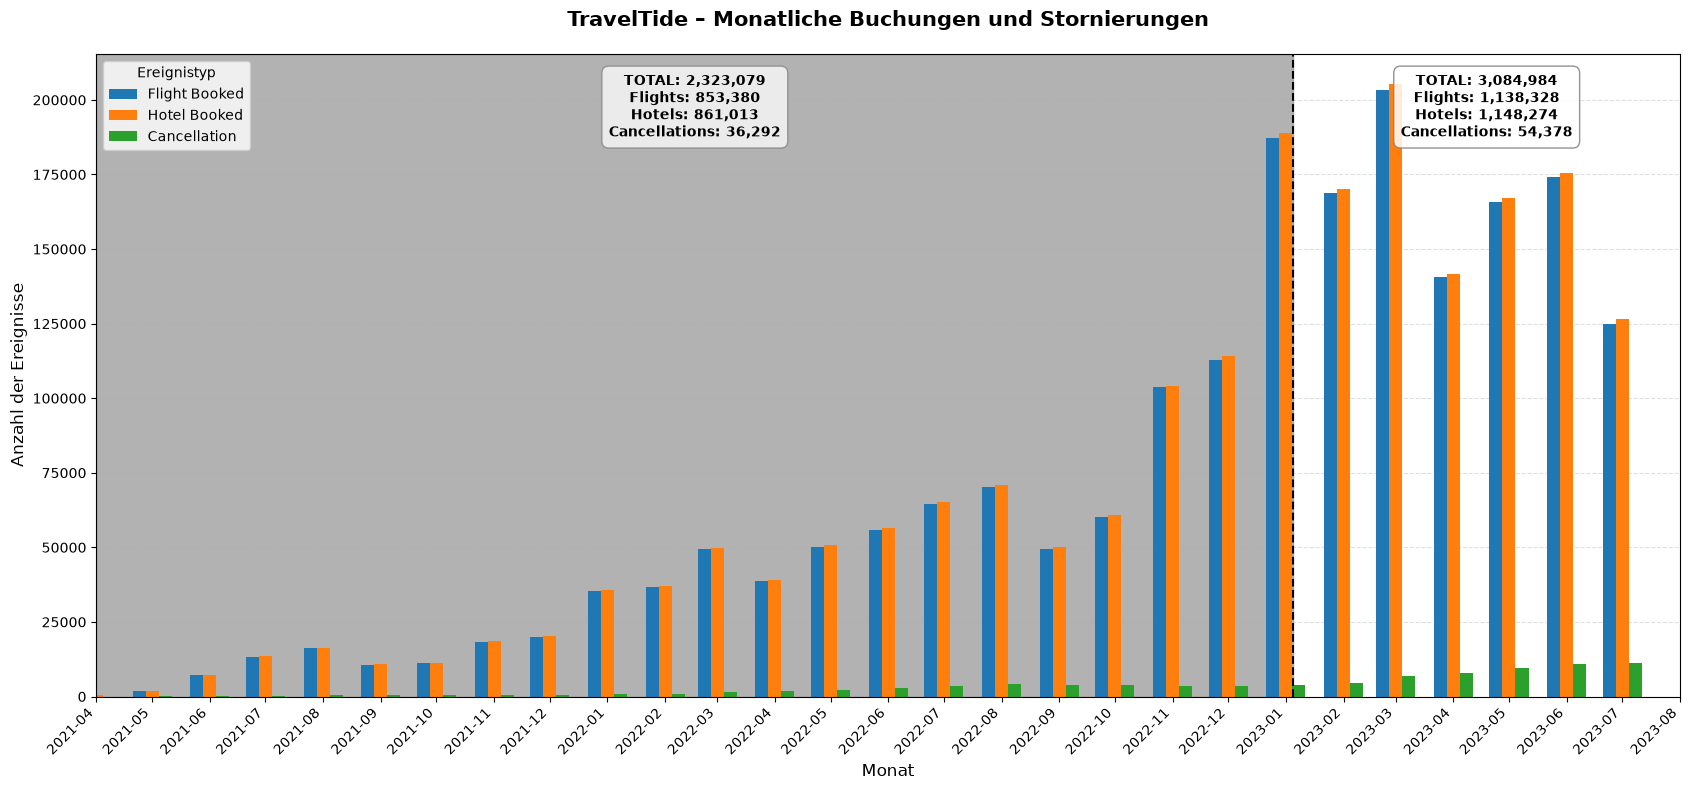

STATISTIK BIS EINSCHLIESSLICH 04.01.2023


,TOTAL,Flights,Hotels,Cancellations
0,2323079,853380,861013,36292



STATISTIK AB 05.01.2023, 00:00 UHR


,TOTAL,Flights,Hotels,Cancellations
0,3084984,1138328,1148274,54378



KONTROLLE
Datensätze gesamt: 5,408,063
Datensätze in beiden Bereichen: 5,408,063


In [71]:
# ============================================================
# TRAVELTIDE – MONTHLY BOOKINGS ANALYSIS
# ============================================================

# ============================================================
# 1. BIBLIOTHEKEN IMPORTIEREN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# ============================================================
# 2. TARGET_FILE FESTLEGEN UND DATEN LADEN
# ============================================================

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

TARGET_FILE = TARGET_DIR / "clean_sessions.csv"

# Prüfen, ob die Datei existiert
if not TARGET_FILE.exists():
    raise FileNotFoundError(
        f"Target file not found: {TARGET_FILE}"
    )

# CSV-Datei laden
sessions = pd.read_csv(TARGET_FILE)

print("DATASET LOADED SUCCESSFULLY")
print(f"Source file: {TARGET_FILE}")
print(f"Rows: {len(sessions):,}")
print(f"Columns: {len(sessions.columns):,}")

# ============================================================
# 3. DATEN VORBEREITEN
# ============================================================

sessions["session_start"] = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

# Buchungsspalten numerisch umwandeln
booking_columns = [
    "flight_booked",
    "hotel_booked",
    "cancellation"
]

for col in booking_columns:
    sessions[col] = pd.to_numeric(
        sessions[col],
        errors="coerce"
    ).fillna(0)

# Datensätze mit gültigem Zeitstempel verwenden
plot_sessions = sessions.dropna(
    subset=["session_start"]
).copy()

# Stichtag festlegen
cutoff = pd.Timestamp("2023-01-05 00:00:00")

# ============================================================
# 4. MONATLICHE BUCHUNGEN AGGREGIEREN
# ============================================================

plot_sessions["month"] = (
    plot_sessions["session_start"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_bookings = (
    plot_sessions
    .groupby("month")[booking_columns]
    .sum()
)

# ============================================================
# 5. STATISTIKEN FÜR DIE BEIDEN ZEITBEREICHE BERECHNEN
# ============================================================

# Bereich 1: bis einschließlich 04.01.2023
before_cutoff = plot_sessions[
    plot_sessions["session_start"] < cutoff
]

# Bereich 2: ab 05.01.2023, 00:00 Uhr
after_cutoff = plot_sessions[
    plot_sessions["session_start"] >= cutoff
]

def calculate_statistics(data):
    return {
        "TOTAL": len(data),
        "Flights": data["flight_booked"].sum(),
        "Hotels": data["hotel_booked"].sum(),
        "Cancellations": data["cancellation"].sum()
    }

stats_before = calculate_statistics(before_cutoff)
stats_after = calculate_statistics(after_cutoff)

# ============================================================
# 6. ZEITGRENZEN FESTLEGEN
# ============================================================

start_date = monthly_bookings.index.min()
end_date = monthly_bookings.index.max() + pd.offsets.MonthBegin(1)

# ============================================================
# 7. DIAGRAMM ERSTELLEN
# ============================================================

fig, ax = plt.subplots(figsize=(17, 8))

# Hintergrund bis 04.01.2023 grau einfärben
ax.axvspan(
    start_date,
    cutoff,
    color="gray",
    alpha=0.6,
    zorder=0
)

# Ab 05.01.2023 bleibt der Hintergrund weiß
ax.set_facecolor("white")

# Monatspositionen als Datumswerte
x = mdates.date2num(monthly_bookings.index)

# Gruppierte Säulen
bar_width = 7
offsets = [-7, 0, 7]

ax.bar(
    x + offsets[0],
    monthly_bookings["flight_booked"],
    width=bar_width,
    label="Flight Booked",
    zorder=2
)

ax.bar(
    x + offsets[1],
    monthly_bookings["hotel_booked"],
    width=bar_width,
    label="Hotel Booked",
    zorder=2
)

ax.bar(
    x + offsets[2],
    monthly_bookings["cancellation"],
    width=bar_width,
    label="Cancellation",
    zorder=2
)

# Trennlinie am 05.01.2023
ax.axvline(
    cutoff,
    color="black",
    linestyle="--",
    linewidth=1.5,
    zorder=3
)

# ============================================================
# 8. GESAMTSTATISTIKEN IN BEIDEN BEREICHEN ANZEIGEN
# ============================================================

def format_statistics(stats):
    return (
        f"TOTAL: {stats['TOTAL']:,}\n"
        f"Flights: {stats['Flights']:,.0f}\n"
        f"Hotels: {stats['Hotels']:,.0f}\n"
        f"Cancellations: {stats['Cancellations']:,.0f}"
    )

# Mittelpunkt des grauen Bereichs
gray_midpoint = start_date + (
    cutoff - start_date
) / 2

# Mittelpunkt des weißen Bereichs
white_midpoint = cutoff + (
    end_date - cutoff
) / 2

# Position der Statistiken im oberen Diagrammbereich
ax.text(
    mdates.date2num(gray_midpoint),
    0.97,
    format_statistics(stats_before),
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="black",
    bbox=dict(
        facecolor="white",
        alpha=0.75,
        edgecolor="gray",
        boxstyle="round,pad=0.5"
    ),
    zorder=5
)

ax.text(
    mdates.date2num(white_midpoint),
    0.97,
    format_statistics(stats_after),
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold",
    color="black",
    bbox=dict(
        facecolor="white",
        alpha=0.85,
        edgecolor="gray",
        boxstyle="round,pad=0.5"
    ),
    zorder=5
)

# ============================================================
# 9. DIAGRAMM FORMATIEREN
# ============================================================

ax.set_title(
    "TravelTide – Monatliche Buchungen und Stornierungen",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Monat", fontsize=12)
ax.set_ylabel("Anzahl der Ereignisse", fontsize=12)

# Monatsbeschriftung
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=45, ha="right")

ax.legend(
    title="Ereignistyp",
    loc="upper left"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.set_xlim(start_date, end_date)

plt.tight_layout()
plt.show()

# ============================================================
# 10. KONTROLLAUSGABE
# ============================================================

print("STATISTIK BIS EINSCHLIESSLICH 04.01.2023")
display(pd.DataFrame([stats_before]))

print("\nSTATISTIK AB 05.01.2023, 00:00 UHR")
display(pd.DataFrame([stats_after]))

print("\nKONTROLLE")
print(f"Datensätze gesamt: {len(plot_sessions):,}")
print(
    f"Datensätze in beiden Bereichen: "
    f"{stats_before['TOTAL'] + stats_after['TOTAL']:,}"
)


DATASET LOADED SUCCESSFULLY
Source file: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Rows: 5,408,063
Columns: 13

DATA PREPARATION COMPLETED
Datensätze für die Korrelationsanalyse: 5,371,178

KORRELATIONSMATRIX – TRAVELTIDE SESSIONS


,session_duration,flight_booked,hotel_booked,page_clicks,cancellation
session_duration,1.000,0.193,0.192,0.847,0.962
flight_booked,0.193,1.000,0.731,0.373,0.133
hotel_booked,0.192,0.731,1.000,0.373,0.132
page_clicks,0.847,0.373,0.373,1.000,0.735
cancellation,0.962,0.133,0.132,0.735,1.000


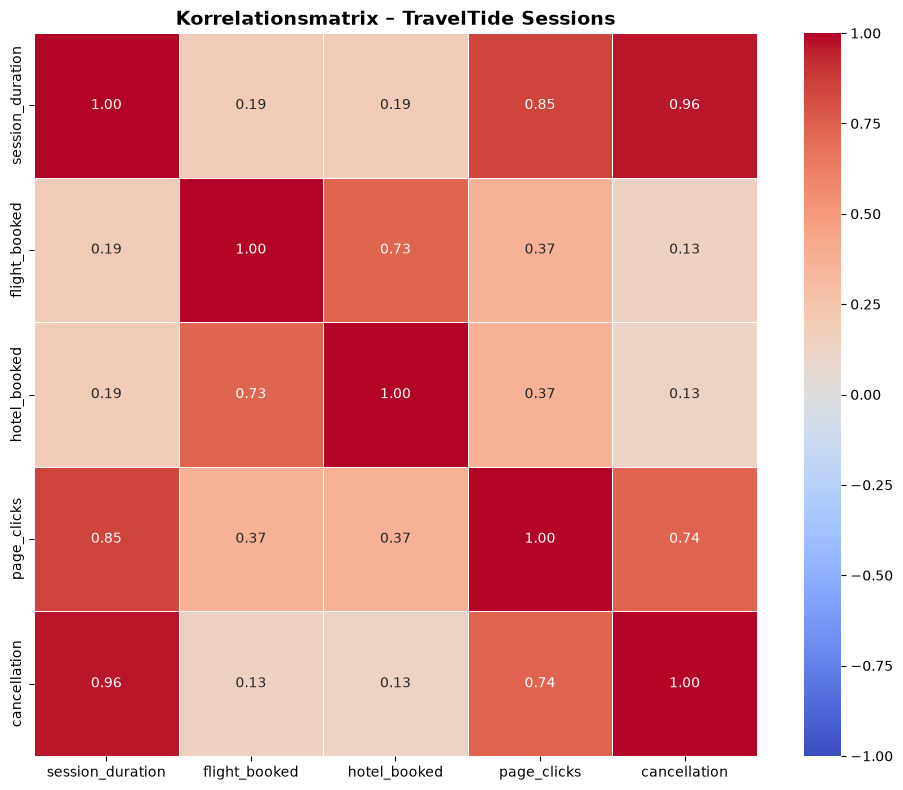


KONTROLLE DER KORRELATIONSANALYSE
Quelldatei: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Ursprüngliche Datensätze: 5,408,063
Verwendete Datensätze: 5,371,178
Ausgeschlossene Datensätze: 36,885

Analysierte Variablen:
['session_duration', 'flight_booked', 'hotel_booked', 'page_clicks', 'cancellation']


In [72]:
# ============================================================
# TRAVELTIDE – KORRELATIONSMATRIX
# ============================================================

# ============================================================
# 1. BIBLIOTHEKEN IMPORTIEREN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

# ============================================================
# 2. PROJEKTPFAD UND TARGET_FILE FESTLEGEN
# ============================================================

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

TARGET_FILE = TARGET_DIR / "clean_sessions.csv"

# ============================================================
# 3. DATEI PRÜFEN UND DATEN LADEN
# ============================================================

if not TARGET_FILE.exists():
    raise FileNotFoundError(
        f"Target file not found: {TARGET_FILE}"
    )

sessions = pd.read_csv(TARGET_FILE)

print("DATASET LOADED SUCCESSFULLY")
print(f"Source file: {TARGET_FILE}")
print(f"Rows: {len(sessions):,}")
print(f"Columns: {len(sessions.columns):,}")

# ============================================================
# 4. DATEN FÜR DIE KORRELATIONSANALYSE VORBEREITEN
# ============================================================

# Kopie erstellen, damit der ursprüngliche DataFrame
# sessions unverändert bleibt

correlation_data = sessions.copy()

# ------------------------------------------------------------
# 4.1 Zeitspalten in datetime umwandeln
# ------------------------------------------------------------

correlation_data["session_start"] = pd.to_datetime(
    correlation_data["session_start"],
    errors="coerce"
)

correlation_data["session_end"] = pd.to_datetime(
    correlation_data["session_end"],
    errors="coerce"
)

# ------------------------------------------------------------
# 4.2 Sessiondauer in Minuten berechnen
# ------------------------------------------------------------

correlation_data["session_duration"] = (
    correlation_data["session_end"]
    - correlation_data["session_start"]
).dt.total_seconds() / 60

# ------------------------------------------------------------
# 4.3 Benötigte Variablen auswählen
# ------------------------------------------------------------

correlation_data = correlation_data[
    [
        "session_duration",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        "cancellation"
    ]
].copy()

# ------------------------------------------------------------
# 4.4 Variablen numerisch umwandeln
# ------------------------------------------------------------

for column in correlation_data.columns:
    correlation_data[column] = pd.to_numeric(
        correlation_data[column],
        errors="coerce"
    )

# ============================================================
# 5. DATEN BEREINIGEN
# ============================================================

# Negative Sessiondauern ausschließen
correlation_data = correlation_data[
    correlation_data["session_duration"] >= 0
].copy()

# Fehlende Werte für die Korrelationsanalyse ausschließen
correlation_data = correlation_data.dropna()

print("\nDATA PREPARATION COMPLETED")
print(
    f"Datensätze für die Korrelationsanalyse: "
    f"{len(correlation_data):,}"
)

# ============================================================
# 6. KORRELATIONSMATRIX BERECHNEN
# ============================================================

correlation_matrix = correlation_data.corr(
    method="pearson"
)

print("\nKORRELATIONSMATRIX – TRAVELTIDE SESSIONS")

display(correlation_matrix.round(3))

# ============================================================
# 7. KORRELATIONSMATRIX VISUALISIEREN
# ============================================================

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title(
    "Korrelationsmatrix – TravelTide Sessions",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# ============================================================
# 8. KONTROLLAUSGABE
# ============================================================

print("\nKONTROLLE DER KORRELATIONSANALYSE")

print(f"Quelldatei: {TARGET_FILE}")
print(f"Ursprüngliche Datensätze: {len(sessions):,}")
print(f"Verwendete Datensätze: {len(correlation_data):,}")
print(
    f"Ausgeschlossene Datensätze: "
    f"{len(sessions) - len(correlation_data):,}"
)

print("\nAnalysierte Variablen:")
print(correlation_data.columns.tolist())


DATASET LOADED SUCCESSFULLY
Source file: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Rows: 5,408,063
Columns: 13

DATA PREPARATION COMPLETED
Ursprüngliche Sessions: 5,408,063
Gültige Sessions: 5,371,178
Ausgeschlossene Sessions: 36,885


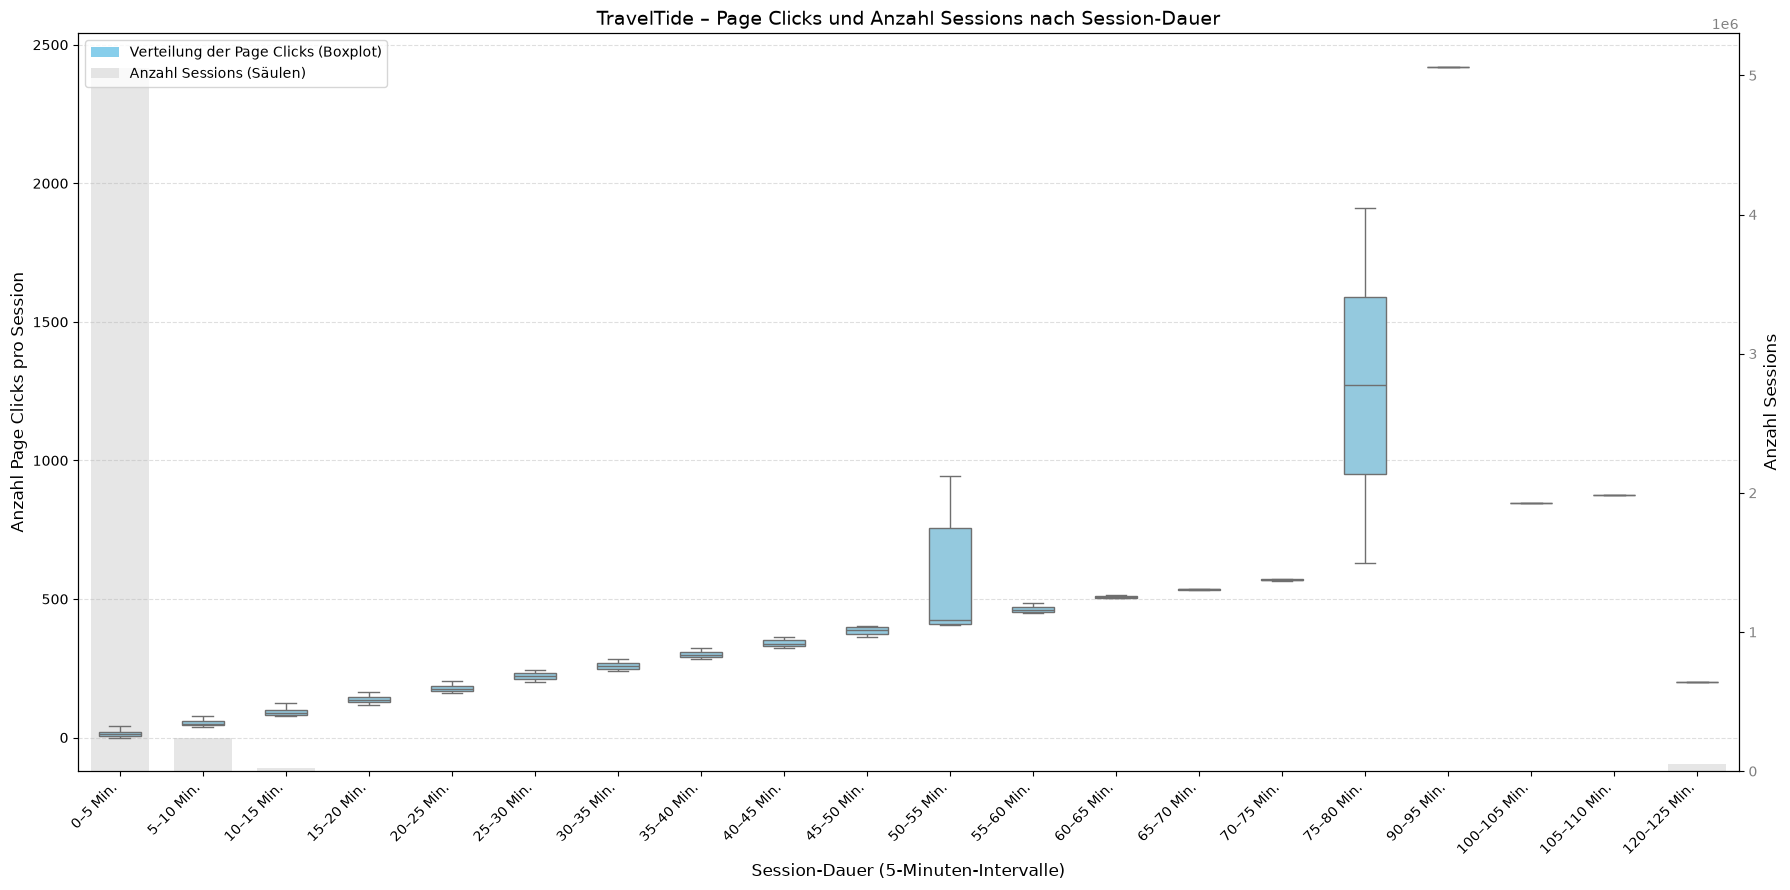


--- ANZAHL DER SESSIONS JE 5-MINUTEN-INTERVALL ---


,Zeitintervall,Anzahl Sessions
0,0–5 Min.,"5,051,161"
1,5–10 Min.,"238,056"
2,10–15 Min.,"25,310"
3,15–20 Min.,"4,200"
4,20–25 Min.,"1,166"
5,25–30 Min.,422
6,30–35 Min.,155
7,35–40 Min.,67
8,40–45 Min.,36
9,45–50 Min.,16



ANALYSE-KONTROLLE
Quelldatei: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Gesamtzahl gültiger Sessions: 5,371,178
Kontrollsumme Sessions: 5,371,178
Kürzeste Session: 0.02 Minuten
Längste Session: 120.00 Minuten


In [73]:
# ============================================================
# TRAVELTIDE – PAGE CLICKS NACH SESSION-DAUER
# ============================================================

# ============================================================
# 1. BIBLIOTHEKEN IMPORTIEREN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from matplotlib.patches import Patch
from IPython.display import display

# ============================================================
# 2. TARGET_FILE FESTLEGEN UND DATEN LADEN
# ============================================================

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

TARGET_FILE = TARGET_DIR / "clean_sessions.csv"

# Prüfen, ob die Datei existiert
if not TARGET_FILE.exists():
    raise FileNotFoundError(
        f"Target file not found: {TARGET_FILE}"
    )

# CSV-Datei laden
sessions = pd.read_csv(TARGET_FILE)

print("DATASET LOADED SUCCESSFULLY")
print(f"Source file: {TARGET_FILE}")
print(f"Rows: {len(sessions):,}")
print(f"Columns: {len(sessions.columns):,}")

# ============================================================
# 3. ZEITSTEMPEL UND PAGE CLICKS KONVERTIEREN
# ============================================================

sessions["session_start"] = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

sessions["session_end"] = pd.to_datetime(
    sessions["session_end"],
    errors="coerce"
)

sessions["page_clicks"] = pd.to_numeric(
    sessions["page_clicks"],
    errors="coerce"
)

# ============================================================
# 4. SESSION-DAUER IN MINUTEN BERECHNEN
# ============================================================

sessions["session_duration_min"] = (
    sessions["session_end"] - sessions["session_start"]
).dt.total_seconds() / 60

# ============================================================
# 5. GÜLTIGE DATENSÄTZE AUSWÄHLEN
# ============================================================

analysis_data = sessions.dropna(
    subset=[
        "session_start",
        "session_end",
        "session_duration_min",
        "page_clicks"
    ]
).copy()

# Negative Session-Dauern und Page Clicks ausschließen
analysis_data = analysis_data[
    (analysis_data["session_duration_min"] >= 0) &
    (analysis_data["page_clicks"] >= 0)
].copy()

print("\nDATA PREPARATION COMPLETED")
print(f"Ursprüngliche Sessions: {len(sessions):,}")
print(f"Gültige Sessions: {len(analysis_data):,}")
print(
    f"Ausgeschlossene Sessions: "
    f"{len(sessions) - len(analysis_data):,}"
)

# Abbrechen, falls keine gültigen Daten vorhanden sind
if analysis_data.empty:
    raise ValueError(
        "Keine gültigen Datensätze für die Analyse vorhanden."
    )

# ============================================================
# 6. 5-MINUTEN-INTERVALLE BILDEN
# ============================================================

analysis_data["duration_interval"] = (
    np.floor(
        analysis_data["session_duration_min"] / 5
    ) * 5
).astype(int)

# ============================================================
# 7. REIHENFOLGE UND BESCHRIFTUNG DER INTERVALLE
# ============================================================

interval_order = sorted(
    analysis_data["duration_interval"].unique()
)

interval_labels = [
    f"{i}–{i+5} Min."
    for i in interval_order
]

# ============================================================
# 8. ANZAHL DER SESSIONS JE ZEITINTERVALL ZÄHLEN
# ============================================================

session_counts = (
    analysis_data
    .groupby("duration_interval")
    .size()
    .reindex(interval_order, fill_value=0)
)

# Positionen der Zeitintervalle
positions = np.arange(len(interval_order))

# ============================================================
# 9. KOMBI-DIAGRAMM ERSTELLEN
# ============================================================

fig, ax1 = plt.subplots(figsize=(18, 9))

# ------------------------------------------------------------
# SÄULENDIAGRAMM IM HINTERGRUND
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.bar(
    positions,
    session_counts.values,
    width=0.7,
    color="lightgray",
    alpha=0.55,
    label="Anzahl Sessions",
    zorder=1
)

ax2.set_ylabel(
    "Anzahl Sessions",
    fontsize=12
)

ax2.tick_params(
    axis="y",
    labelcolor="gray"
)

# Ebenen festlegen
ax2.set_zorder(1)
ax1.set_zorder(2)
ax1.patch.set_visible(False)

# ------------------------------------------------------------
# BOXPLOT IM VORDERGRUND
# ------------------------------------------------------------

sns.boxplot(
    data=analysis_data,
    x="duration_interval",
    y="page_clicks",
    order=interval_order,
    color="skyblue",
    showfliers=False,
    width=0.5,
    ax=ax1,
    zorder=3
)

# ------------------------------------------------------------
# ACHSEN UND BESCHRIFTUNGEN
# ------------------------------------------------------------

ax1.set_xticks(positions)

ax1.set_xticklabels(
    interval_labels,
    rotation=45,
    ha="right"
)

ax1.set_xlabel(
    "Session-Dauer (5-Minuten-Intervalle)",
    fontsize=12
)

ax1.set_ylabel(
    "Anzahl Page Clicks pro Session",
    fontsize=12
)

ax1.set_title(
    "TravelTide – Page Clicks und Anzahl Sessions nach Session-Dauer",
    fontsize=14
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

# ------------------------------------------------------------
# LEGENDE
# ------------------------------------------------------------

legend_elements = [
    Patch(
        facecolor="skyblue",
        label="Verteilung der Page Clicks (Boxplot)"
    ),
    Patch(
        facecolor="lightgray",
        alpha=0.55,
        label="Anzahl Sessions (Säulen)"
    )
]

ax1.legend(
    handles=legend_elements,
    loc="upper left"
)

plt.tight_layout()
plt.show()

# ============================================================
# 10. ERGEBNISTABELLE ERSTELLEN
# ============================================================

session_summary = pd.DataFrame({
    "Zeitintervall": interval_labels,
    "Anzahl Sessions": session_counts.values
})

# ============================================================
# 11. ERGEBNISTABELLE ANZEIGEN
# ============================================================

print("\n--- ANZAHL DER SESSIONS JE 5-MINUTEN-INTERVALL ---")

display(
    session_summary.style.format({
        "Anzahl Sessions": "{:,.0f}"
    })
)

# ============================================================
# 12. KONTROLLAUSGABE
# ============================================================

print("\nANALYSE-KONTROLLE")

print(f"Quelldatei: {TARGET_FILE}")
print(f"Gesamtzahl gültiger Sessions: {len(analysis_data):,}")

print(
    f"Kontrollsumme Sessions: "
    f"{session_summary['Anzahl Sessions'].sum():,}"
)

print(
    f"Kürzeste Session: "
    f"{analysis_data['session_duration_min'].min():.2f} Minuten"
)

print(
    f"Längste Session: "
    f"{analysis_data['session_duration_min'].max():.2f} Minuten"
)


C:\Users\Cjjru\AppData\Local\Temp\ipykernel_9432\3004261827.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


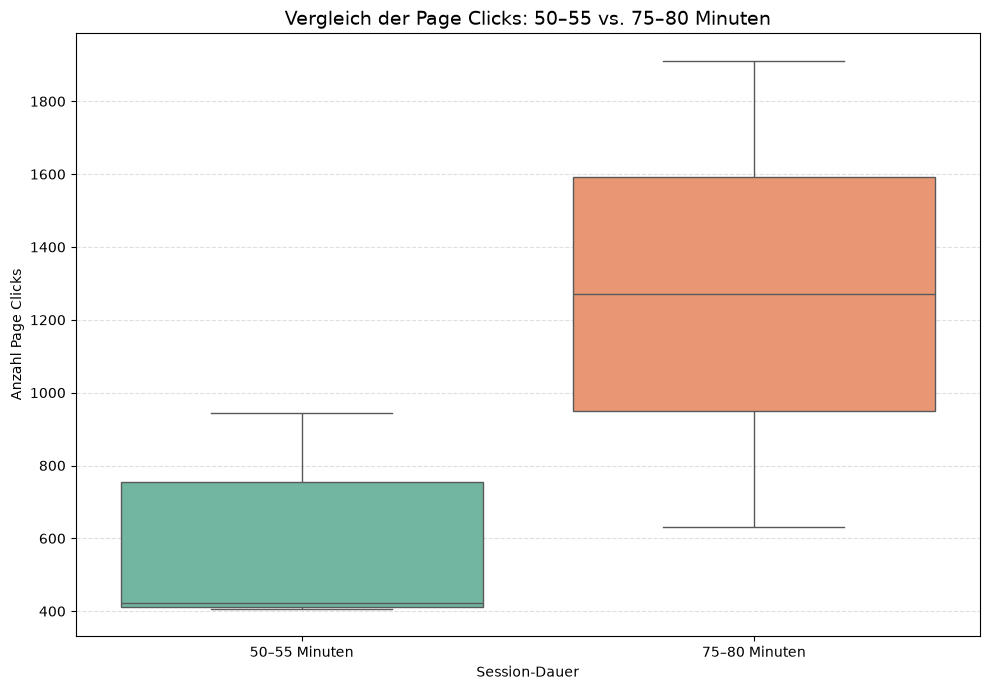

In [74]:
# ============================================================
# 9. BOXPLOT – VERGLEICH 50–55 UND 75–80 MINUTEN
# ============================================================

# Gewünschte Intervalle auswählen
selected_intervals = [50, 75]

comparison_data = analysis_data[
    analysis_data["duration_interval"].isin(selected_intervals)
].copy()

# Beschriftungen erstellen
comparison_data["Zeitintervall"] = comparison_data[
    "duration_interval"
].map({
    50: "50–55 Minuten",
    75: "75–80 Minuten"
})

# Eigenes Diagramm erstellen
plt.figure(figsize=(10, 7))

sns.boxplot(
    data=comparison_data,
    x="Zeitintervall",
    y="page_clicks",
    order=["50–55 Minuten", "75–80 Minuten"],
    palette="Set2",
    showfliers=False
)

plt.title(
    "Vergleich der Page Clicks: 50–55 vs. 75–80 Minuten",
    fontsize=14
)

plt.xlabel("Session-Dauer")
plt.ylabel("Anzahl Page Clicks")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

DATASET LOADED SUCCESSFULLY
Source file: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Rows: 5,408,063
Columns: 13


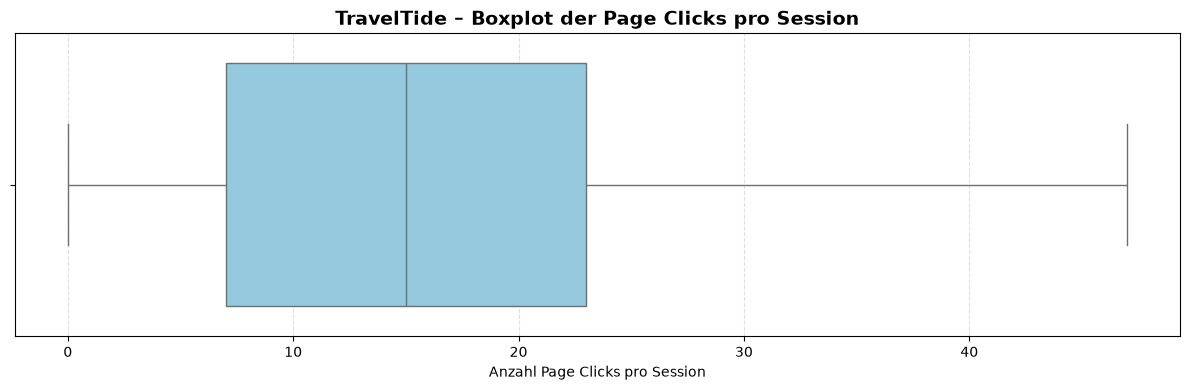


KONTROLLAUSGABE
Quelldatei: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Ursprüngliche Sessions: 5,408,063
Gültige Sessions: 5,408,063
Ausgeschlossene Datensätze: 0

DESKRIPTIVE STATISTIKEN – PAGE CLICKS


,Page Clicks
count,5408063.00
mean,18.77
std,22.18
min,0.00
25%,7.00
50%,15.00
75%,23.00
max,2421.00


In [75]:
# ============================================================
# TRAVELTIDE – BOXPLOT PAGE CLICKS PRO SESSION
# ============================================================

# ============================================================
# 1. BIBLIOTHEKEN IMPORTIEREN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# ============================================================
# 2. TARGET_FILE FESTLEGEN UND DATEN LADEN
# ============================================================

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

TARGET_FILE = TARGET_DIR / "clean_sessions.csv"

# Prüfen, ob die Datei existiert
if not TARGET_FILE.exists():
    raise FileNotFoundError(
        f"Target file not found: {TARGET_FILE}"
    )

# CSV-Datei laden
sessions = pd.read_csv(TARGET_FILE)

print("DATASET LOADED SUCCESSFULLY")
print(f"Source file: {TARGET_FILE}")
print(f"Rows: {len(sessions):,}")
print(f"Columns: {len(sessions.columns):,}")

# ============================================================
# 3. PAGE CLICKS VORBEREITEN
# ============================================================

# Prüfen, ob die benötigte Spalte vorhanden ist
if "page_clicks" not in sessions.columns:
    raise KeyError(
        "Die Spalte 'page_clicks' wurde in der CSV-Datei nicht gefunden."
    )

click_data = pd.to_numeric(
    sessions["page_clicks"],
    errors="coerce"
).dropna()

# Nur nicht-negative Werte berücksichtigen
click_data = click_data[click_data >= 0]

# Prüfen, ob gültige Daten vorhanden sind
if click_data.empty:
    raise ValueError(
        "Keine gültigen Page-Clicks-Werte für die Analyse vorhanden."
    )

# ============================================================
# 4. BOXPLOT ERSTELLEN
# ============================================================

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=click_data,
    color="skyblue",
    showfliers=False
)

plt.title(
    "TravelTide – Boxplot der Page Clicks pro Session",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Anzahl Page Clicks pro Session")

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

# ============================================================
# 5. ANZAHL DER BERÜCKSICHTIGTEN SESSIONS
# ============================================================

print("\nKONTROLLAUSGABE")

print(f"Quelldatei: {TARGET_FILE}")
print(f"Ursprüngliche Sessions: {len(sessions):,}")
print(f"Gültige Sessions: {len(click_data):,}")
print(
    f"Ausgeschlossene Datensätze: "
    f"{len(sessions) - len(click_data):,}"
)

# ============================================================
# 6. DESKRIPTIVE STATISTIKEN
# ============================================================

print("\nDESKRIPTIVE STATISTIKEN – PAGE CLICKS")

display(
    click_data.describe().to_frame(
        name="Page Clicks"
    ).round(2)
)


In [76]:
# ============================================================
# 1. PERZENTILE BERECHNEN
# ============================================================

percentiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

quantiles = click_data.quantile(percentiles)

# ============================================================
# 2. PERZENTILGRENZEN FESTLEGEN
# ============================================================

bin_edges = [
    click_data.min(),
    *quantiles.tolist(),
    click_data.max()
]

percentile_labels = [
    "P0–P25",
    "P25–P50",
    "P50–P75",
    "P75–P90",
    "P90–P95",
    "P95–P99",
    "P99–P100"
]

# ============================================================
# 3. SESSIONS JE BIN ZÄHLEN
# ============================================================

total_sessions = click_data.count()

bin_stats = []

for i, label in enumerate(percentile_labels):

    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    # Erste Gruppe inklusive unterer Grenze,
    # alle weiteren Gruppen exklusive unterer Grenze
    if i == 0:
        mask = (
            (click_data >= lower) &
            (click_data <= upper)
        )
    else:
        mask = (
            (click_data > lower) &
            (click_data <= upper)
        )

    session_count = mask.sum()

    percentage = (
        session_count / total_sessions * 100
    )

    bin_stats.append({
        "Perzentil": label,
        "Untere Grenze": lower,
        "Obere Grenze": upper,
        "Anzahl Sessions": session_count,
        "Prozent-Anteil (%)": percentage
    })

# ============================================================
# 4. TABELLE ERSTELLEN
# ============================================================

bin_stats = pd.DataFrame(bin_stats)

# ============================================================
# 5. ERGEBNIS ANZEIGEN
# ============================================================

print("Verteilung der Page Clicks nach Perzentilen")

display(
    bin_stats.style.format({
        "Untere Grenze": "{:,.0f}",
        "Obere Grenze": "{:,.0f}",
        "Anzahl Sessions": "{:,.0f}",
        "Prozent-Anteil (%)": "{:.0f}%"
    })
)

print(f"\nGesamtzahl Sessions: {total_sessions:,.0f}")
print(
    f"Kontrollsumme Sessions: "
    f"{bin_stats['Anzahl Sessions'].sum():,.0f}"
)
print(
    f"Kontrollsumme Prozent: "
    f"{bin_stats['Prozent-Anteil (%)'].sum():.0f}%"
)

Verteilung der Page Clicks nach Perzentilen


,Perzentil,Untere Grenze,Obere Grenze,Anzahl Sessions,Prozent-Anteil (%)
0,P0–P25,0,7,"1,461,718",27%
1,P25–P50,7,15,"1,303,829",24%
2,P50–P75,15,23,"1,390,852",26%
3,P75–P90,23,33,"721,702",13%
4,P90–P95,33,44,"260,465",5%
5,P95–P99,44,127,"215,514",4%
6,P99–P100,127,"2,421","53,983",1%



Gesamtzahl Sessions: 5,408,063
Kontrollsumme Sessions: 5,408,063
Kontrollsumme Prozent: 100%


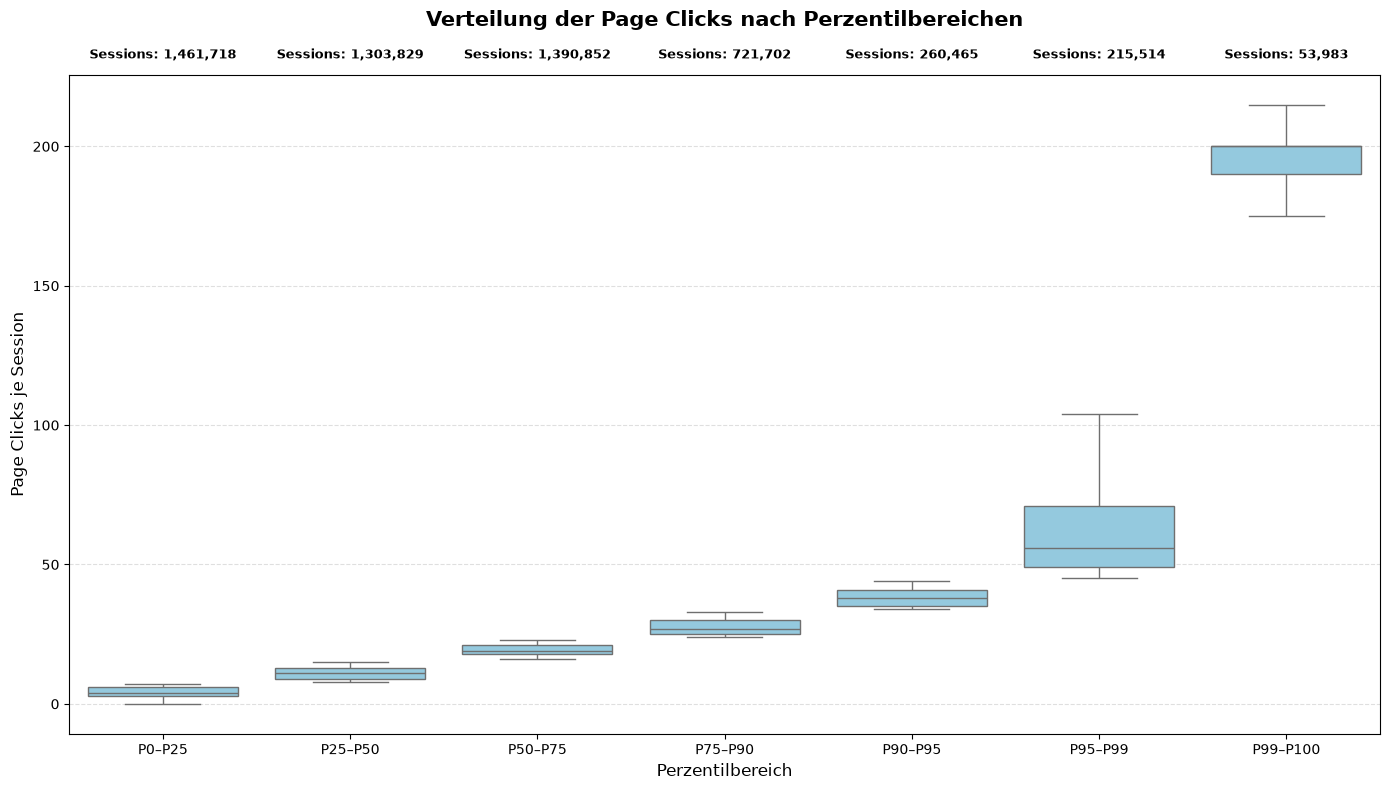

Sessions je Perzentilbereich:


,Perzentilbereich,Untere Grenze,Obere Grenze,Anzahl Sessions,Prozent-Anteil (%)
0,P0–P25,0,7,"1,461,718",27.0%
1,P25–P50,7,15,"1,303,829",24.1%
2,P50–P75,15,23,"1,390,852",25.7%
3,P75–P90,23,33,"721,702",13.3%
4,P90–P95,33,44,"260,465",4.8%
5,P95–P99,44,127,"215,514",4.0%
6,P99–P100,127,"2,421","53,983",1.0%


In [77]:
# ============================================================
# 1. BIBLIOTHEKEN IMPORTIEREN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 2. PERZENTILE UND BIN-GRENZEN BERECHNEN
# ============================================================

percentiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

quantiles = click_data.quantile(percentiles)

bin_edges = [
    click_data.min(),
    *quantiles.tolist(),
    click_data.max()
]

percentile_labels = [
    "P0–P25",
    "P25–P50",
    "P50–P75",
    "P75–P90",
    "P90–P95",
    "P95–P99",
    "P99–P100"
]

# ============================================================
# 3. SESSIONS DEN PERZENTILBEREICHEN ZUORDNEN
# ============================================================

plot_data = pd.DataFrame({
    "page_clicks": click_data
})

plot_data["Perzentilbereich"] = pd.NA

for i, label in enumerate(percentile_labels):

    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    if i == 0:
        mask = (
            (plot_data["page_clicks"] >= lower) &
            (plot_data["page_clicks"] <= upper)
        )
    else:
        mask = (
            (plot_data["page_clicks"] > lower) &
            (plot_data["page_clicks"] <= upper)
        )

    plot_data.loc[mask, "Perzentilbereich"] = label

# ============================================================
# 4. ANZAHL DER SESSIONS JE BEREICH BERECHNEN
# ============================================================

session_counts = (
    plot_data["Perzentilbereich"]
    .value_counts()
    .reindex(percentile_labels, fill_value=0)
)

# ============================================================
# 5. BOXPLOT ERSTELLEN
# ============================================================

plt.figure(figsize=(14, 8))

ax = sns.boxplot(
    data=plot_data,
    x="Perzentilbereich",
    y="page_clicks",
    order=percentile_labels,
    color="skyblue",
    showfliers=False
)

# ============================================================
# 6. SESSION-ANZAHL ÜBER DEN BOXPLOTS ANZEIGEN
# ============================================================

for i, label in enumerate(percentile_labels):

    count = session_counts[label]

    ax.text(
        i,
        1.02,
        f"Sessions: {count:,.0f}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# ============================================================
# 7. BESCHRIFTUNG UND LAYOUT
# ============================================================

plt.title(
    "Verteilung der Page Clicks nach Perzentilbereichen",
    fontsize=15,
    fontweight="bold",
    pad=35
)

plt.xlabel("Perzentilbereich", fontsize=12)
plt.ylabel("Page Clicks je Session", fontsize=12)

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ============================================================
# 8. ERGEBNISTABELLE AUSGEBEN
# ============================================================

result_table = pd.DataFrame({
    "Perzentilbereich": percentile_labels,
    "Untere Grenze": bin_edges[:-1],
    "Obere Grenze": bin_edges[1:],
    "Anzahl Sessions": session_counts.values
})

result_table["Prozent-Anteil (%)"] = (
    result_table["Anzahl Sessions"] /
    result_table["Anzahl Sessions"].sum() * 100
)

print("Sessions je Perzentilbereich:")

display(
    result_table.style.format({
        "Untere Grenze": "{:,.0f}",
        "Obere Grenze": "{:,.0f}",
        "Anzahl Sessions": "{:,.0f}",
        "Prozent-Anteil (%)": "{:.1f}%"
    })
)



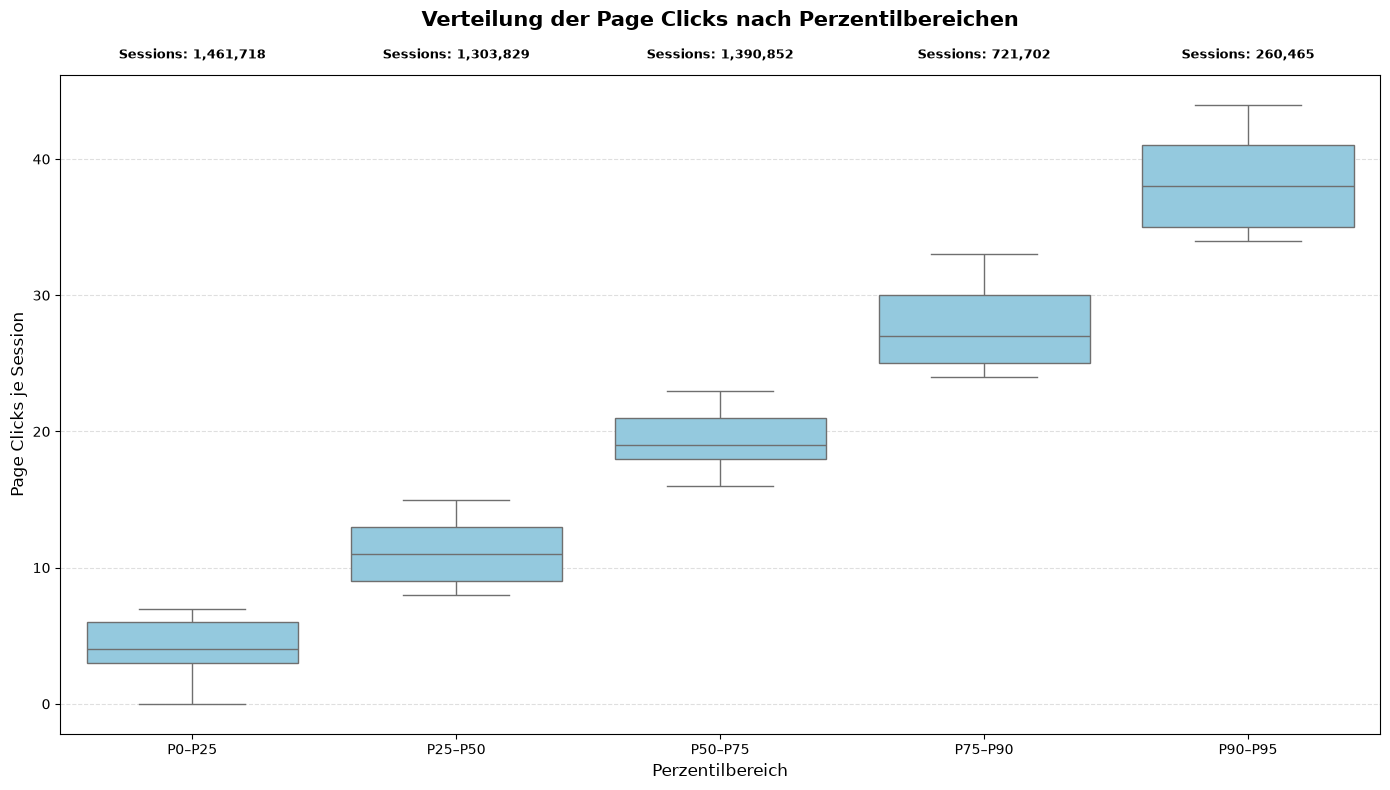

Sessions je Perzentilbereich:


,Perzentilbereich,Untere Grenze,Obere Grenze,Anzahl Sessions,Prozent-Anteil (%)
0,P0–P25,0,7,"1,461,718",27.0%
1,P25–P50,7,15,"1,303,829",24.1%
2,P50–P75,15,23,"1,390,852",25.7%
3,P75–P90,23,33,"721,702",13.3%
4,P90–P95,33,44,"260,465",4.8%



Gesamtzahl aller Sessions: 5,408,063
Berücksichtigte Sessions bis P95: 5,138,566
Nicht berücksichtigte Sessions oberhalb P95: 269,497


In [78]:
# ============================================================
# 1. BIBLIOTHEKEN IMPORTIEREN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 2. PERZENTILE UND BIN-GRENZEN BERECHNEN
# ============================================================

percentiles = [0.25, 0.50, 0.75, 0.90, 0.95]

quantiles = click_data.quantile(percentiles)

bin_edges = [
    click_data.min(),
    *quantiles.tolist()
]

percentile_labels = [
    "P0–P25",
    "P25–P50",
    "P50–P75",
    "P75–P90",
    "P90–P95"
]

# ============================================================
# 3. SESSIONS DEN PERZENTILBEREICHEN ZUORDNEN
# ============================================================

plot_data = pd.DataFrame({
    "page_clicks": click_data
})

plot_data["Perzentilbereich"] = pd.NA

for i, label in enumerate(percentile_labels):

    lower = bin_edges[i]
    upper = bin_edges[i + 1]

    if i == 0:
        mask = (
            (plot_data["page_clicks"] >= lower) &
            (plot_data["page_clicks"] <= upper)
        )
    else:
        mask = (
            (plot_data["page_clicks"] > lower) &
            (plot_data["page_clicks"] <= upper)
        )

    plot_data.loc[mask, "Perzentilbereich"] = label

# ============================================================
# 4. ANZAHL DER SESSIONS JE BEREICH BERECHNEN
# ============================================================

session_counts = (
    plot_data["Perzentilbereich"]
    .value_counts()
    .reindex(percentile_labels, fill_value=0)
)

# ============================================================
# 5. BOXPLOT ERSTELLEN
# ============================================================

plt.figure(figsize=(14, 8))

ax = sns.boxplot(
    data=plot_data.dropna(subset=["Perzentilbereich"]),
    x="Perzentilbereich",
    y="page_clicks",
    order=percentile_labels,
    color="skyblue",
    showfliers=False
)

# ============================================================
# 6. SESSION-ANZAHL ÜBER DEN BOXPLOTS ANZEIGEN
# ============================================================

for i, label in enumerate(percentile_labels):

    count = session_counts[label]

    ax.text(
        i,
        1.02,
        f"Sessions: {count:,.0f}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# ============================================================
# 7. BESCHRIFTUNG UND LAYOUT
# ============================================================

plt.title(
    "Verteilung der Page Clicks nach Perzentilbereichen",
    fontsize=15,
    fontweight="bold",
    pad=35
)

plt.xlabel("Perzentilbereich", fontsize=12)
plt.ylabel("Page Clicks je Session", fontsize=12)

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ============================================================
# 8. ERGEBNISTABELLE AUSGEBEN
# ============================================================

result_table = pd.DataFrame({
    "Perzentilbereich": percentile_labels,
    "Untere Grenze": bin_edges[:-1],
    "Obere Grenze": bin_edges[1:],
    "Anzahl Sessions": session_counts.values
})

result_table["Prozent-Anteil (%)"] = (
    result_table["Anzahl Sessions"] /
    click_data.count() * 100
)

print("Sessions je Perzentilbereich:")

display(
    result_table.style.format({
        "Untere Grenze": "{:,.0f}",
        "Obere Grenze": "{:,.0f}",
        "Anzahl Sessions": "{:,.0f}",
        "Prozent-Anteil (%)": "{:.1f}%"
    })
)

print(f"\nGesamtzahl aller Sessions: {click_data.count():,.0f}")
print(f"Berücksichtigte Sessions bis P95: {session_counts.sum():,.0f}")
print(f"Nicht berücksichtigte Sessions oberhalb P95: "
      f"{click_data.count() - session_counts.sum():,.0f}")


# ============================================================
# ============================================================
# 0. DATEN VORBEREITEN – EINMALIG AUSFÜHREN
# ============================================================
# ============================================================

In [101]:
# ============================================================
# TABELLENSTRUKTUR VON clean_sessions.csv ÜBERNEHMEN
# ============================================================

# Quelldatei
TARGET_FILE = TARGET_DIR / "clean_sessions.csv"

# Zieldatei
OUTPUT_FILE = TARGET_DIR / "clean_all_result.csv"

# ------------------------------------------------------------
# 1. Quelldatei prüfen
# ------------------------------------------------------------

if not TARGET_FILE.exists():
    raise FileNotFoundError(
        f"Target file not found: {TARGET_FILE}"
    )

# ------------------------------------------------------------
# 2. Originaldatei laden
# ------------------------------------------------------------

target_data = pd.read_csv(
    TARGET_FILE,
    dtype={"session_id": "string"}
)

# ------------------------------------------------------------
# 3. Leere Output-Datei mit identischer Tabellenstruktur
#    erstellen
# ------------------------------------------------------------

empty_output = target_data.iloc[0:0].copy()

empty_output.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("OUTPUT FILE SUCCESSFULLY CREATED")
print(f"Source file: {TARGET_FILE}")
print(f"Output file: {OUTPUT_FILE}")

# ------------------------------------------------------------
# 4. Tabellenstruktur kontrollieren
# ------------------------------------------------------------

output_data = pd.read_csv(
    OUTPUT_FILE,
    dtype={"session_id": "string"}
)

print("\nSTRUKTURVERGLEICH")

print("\nSpalten in TARGET_FILE:")
print(target_data.columns.tolist())

print("\nSpalten in OUTPUT_FILE:")
print(output_data.columns.tolist())

print("\nSTRUKTUR IDENTISCH:")
print(
    target_data.columns.tolist()
    == output_data.columns.tolist()
)

print(f"\nAnzahl Spalten: {len(output_data.columns)}")
print(f"Anzahl Datensätze: {len(output_data)}")

print("\nOUTPUT FILE READY FOR FURTHER ANALYSIS")


OUTPUT FILE SUCCESSFULLY CREATED
Source file: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_sessions.csv
Output file: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_all_result.csv

STRUKTURVERGLEICH

Spalten in TARGET_FILE:
['session_id', 'user_id', 'trip_id', 'session_start', 'session_end', 'flight_discount', 'hotel_discount', 'flight_discount_amount', 'hotel_discount_amount', 'flight_booked', 'hotel_booked', 'page_clicks', 'cancellation']

Spalten in OUTPUT_FILE:
['session_id', 'user_id', 'trip_id', 'session_start', 'session_end', 'flight_discount', 'hotel_discount', 'flight_discount_amount', 'hotel_discount_amount', 'flight_booked', 'hotel_booked', 'page_clicks', 'cancellation']

STRUKTUR IDENTISCH:
True

Anzahl Spalten: 13
Anzahl Datensätze: 0

OUTPUT FILE READY FOR FURTHER ANALYSIS


In [102]:
# ============================================================
# 0. DATEN FÜR DAS CLUSTERINGVORBEREITEN – EINMALIG AUSFÜHREN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 0.1 Prüfen, ob sessions existiert
# ------------------------------------------------------------

if "sessions" not in globals():
    raise NameError(
        "Der DataFrame 'sessions' wurde noch nicht definiert."
    )

if sessions.empty:
    raise ValueError("Der DataFrame 'sessions' ist leer.")

# ------------------------------------------------------------
# 0.2 Benötigte Spalten überprüfen
# ------------------------------------------------------------

required_columns = [
    "session_id",
    "session_start",
    "session_end",
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    "cancellation"
]

missing_columns = [
    col for col in required_columns
    if col not in sessions.columns
]

if missing_columns:
    raise ValueError(
        f"Folgende Spalten fehlen: {missing_columns}"
    )

# Session-ID als String erhalten
cluster_data = sessions[required_columns].copy()

cluster_data["session_id"] = (
    cluster_data["session_id"].astype("string")
)

# ------------------------------------------------------------
# 0.3 Zeitstempel konvertieren
# ------------------------------------------------------------

cluster_data["session_start"] = pd.to_datetime(
    cluster_data["session_start"],
    errors="coerce",
    utc=True
)

cluster_data["session_end"] = pd.to_datetime(
    cluster_data["session_end"],
    errors="coerce",
    utc=True
)

# ------------------------------------------------------------
# 0.4 Numerische Spalten konvertieren
# ------------------------------------------------------------

numeric_columns = [
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    "cancellation"
]

for col in numeric_columns:
    cluster_data[col] = pd.to_numeric(
        cluster_data[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 0.5 Session-Dauer berechnen
# ------------------------------------------------------------

cluster_data["session_duration_min"] = (
    cluster_data["session_end"] -
    cluster_data["session_start"]
).dt.total_seconds() / 60

# ------------------------------------------------------------
# 0.6 Zeitliche Merkmale berechnen
# ------------------------------------------------------------

cluster_data["start_hour"] = (
    cluster_data["session_start"].dt.hour
)

cluster_data["weekday"] = (
    cluster_data["session_start"].dt.dayofweek
)

cluster_data["month"] = (
    cluster_data["session_start"].dt.month
)

# ------------------------------------------------------------
# 0.7 Fehlende und ungültige Werte entfernen
# ------------------------------------------------------------

feature_columns = [
    "session_duration_min",
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    "cancellation",
    "start_hour",
    "weekday",
    "month"
]

cluster_data = cluster_data.dropna(
    subset=feature_columns + ["session_id"]
).copy()

# Nur gültige Werte behalten
cluster_data = cluster_data[
    (cluster_data["session_duration_min"] >= 0) &
    (cluster_data["page_clicks"] >= 0) &
    (cluster_data["flight_booked"] >= 0) &
    (cluster_data["hotel_booked"] >= 0) &
    (cluster_data["cancellation"] >= 0)
].copy()

if cluster_data.empty:
    raise ValueError(
        "Nach der Datenbereinigung sind keine Sessions übrig."
    )

# ------------------------------------------------------------
# 0.8 Page Clicks logarithmisch transformieren
# ------------------------------------------------------------

cluster_data["page_clicks_log"] = np.log1p(
    cluster_data["page_clicks"]
)

# ------------------------------------------------------------
# 0.9 Merkmale für das Clustering festlegen
# ------------------------------------------------------------

feature_columns = [
    "session_duration_min",
    "flight_booked",
    "hotel_booked",
    "page_clicks_log",
    "cancellation",
    "start_hour",
    "weekday",
    "month"
]

# session_id wird bewusst NICHT als Merkmal verwendet
X = cluster_data[feature_columns].copy()

# Zusätzliche Prüfung auf unendliche Werte
X = X.replace([np.inf, -np.inf], np.nan)

valid_indices = X.dropna().index

X = X.loc[valid_indices]
cluster_data = cluster_data.loc[valid_indices].copy()

if len(X) < 2:
    raise ValueError(
        "Zu wenige gültige Sessions für das Clustering."
    )

# ------------------------------------------------------------
# 0.10 Daten standardisieren
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=feature_columns
)

# ------------------------------------------------------------
# 0.11 Stichprobe für die Clustering-Verfahren erstellen
# ------------------------------------------------------------

sample_size = min(10000, len(cluster_data))

sample_indices = cluster_data.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_scaled.loc[sample_indices].copy()

# ------------------------------------------------------------
# 0.12 Ergebnisse kontrollieren
# ------------------------------------------------------------

print("DATENVORBEREITUNG ABGESCHLOSSEN")
print("-----------------------------------")

print(f"Ursprüngliche Sessions: {len(sessions):,}")
print(f"Bereinigte Sessions: {len(cluster_data):,}")
print(f"Sessions für Clustering: {len(X_sample):,}")
print(f"Anzahl verwendeter Merkmale: {len(feature_columns)}")

print("\nVerwendete Merkmale:")
print(feature_columns)

print("\nDimensionen der Daten:")
print("X:", X.shape)
print("X_scaled:", X_scaled.shape)
print("X_sample:", X_sample.shape)

print("\nSESSION-ID-KONTROLLE")
print(f"Vorhandene IDs: {cluster_data['session_id'].notna().sum():,}")
print(f"Eindeutige IDs: {cluster_data['session_id'].nunique():,}")

# Session-ID und Merkmale gemeinsam kontrollieren
display(
    cluster_data[
        ["session_id"] + feature_columns
    ].head(10)
)


C:\Users\Cjjru\AppData\Local\Temp\ipykernel_9432\2370326106.py:107: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  cluster_data["session_start"].dt.dayofweek


DATENVORBEREITUNG ABGESCHLOSSEN
-----------------------------------
Ursprüngliche Sessions: 5,408,063
Bereinigte Sessions: 5,371,178
Sessions für Clustering: 10,000
Anzahl verwendeter Merkmale: 8

Verwendete Merkmale:
['session_duration_min', 'flight_booked', 'hotel_booked', 'page_clicks_log', 'cancellation', 'start_hour', 'weekday', 'month']

Dimensionen der Daten:
X: (5371178, 8)
X_scaled: (5371178, 8)
X_sample: (10000, 8)

SESSION-ID-KONTROLLE
Vorhandene IDs: 5,371,178
Eindeutige IDs: 5,371,178


,session_id,session_duration_min,flight_booked,hotel_booked,page_clicks_log,cancellation,start_hour,weekday,month
0,275450-c9095461e19f482296686ee955f026dc,4.466667,False,False,3.610918,False,16,3,6
1,275473-f7d52afbbb7546c8ac5ada433abd6eb3,0.266667,False,False,1.098612,False,19,3,6
2,275679-97b7e062a4b0493db934bf2921f39957,3.066667,True,True,3.258097,False,14,3,6
3,276121-c9d32570954f4d8d93f7bcc8de887007,1.566667,False,False,2.639057,False,15,3,6
4,276181-5fe2c26c5e98418d8e784ae5013fc727,0.266667,False,False,1.098612,False,22,3,6
5,276194-66dcf78424ac4436bead3cfc599dcb0e,1.050000,False,False,2.197225,False,21,3,6
6,276224-e4f9f5c982a64aa5a0603a97e770cec0,3.066667,True,True,3.258097,False,5,3,6
7,276311-53b0a779668b49de840ac3b2c499e693,0.616667,False,False,1.791759,False,6,3,6
8,276374-5b513599cc9b424cba2a2bba25c7cf98,3.916667,True,True,3.465736,False,14,3,6
9,276419-b247119a40b14fc29087034d2eee1041,0.783333,False,False,1.945910,False,14,3,6


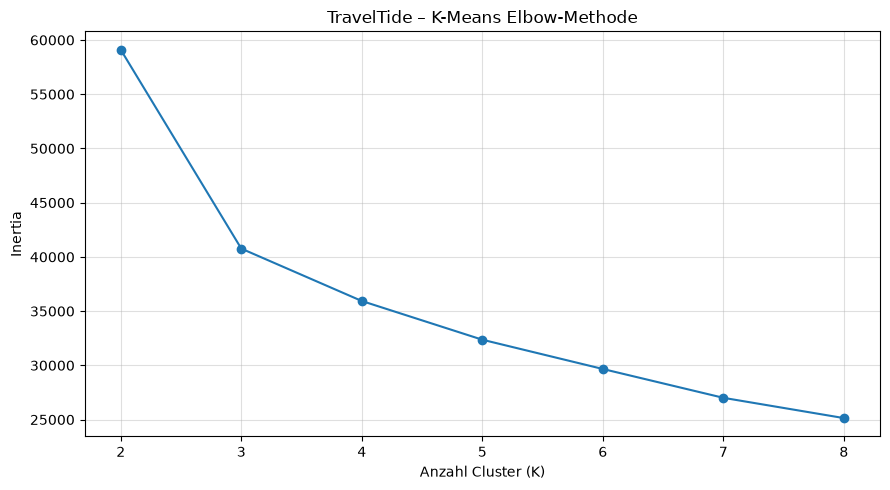

K-MEANS – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
KMeans_Cluster,
0,3393
1,107
2,3435
3,3065


K-MEANS – DURCHSCHNITTLICHE CLUSTER-MERKMALE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation
KMeans_Cluster,,,,,
0,1.46,0.05,0.06,11.72,0.0
1,117.94,1.00,1.00,189.98,1.0
2,3.31,0.93,0.92,26.70,0.0
3,1.43,0.06,0.06,11.49,0.0


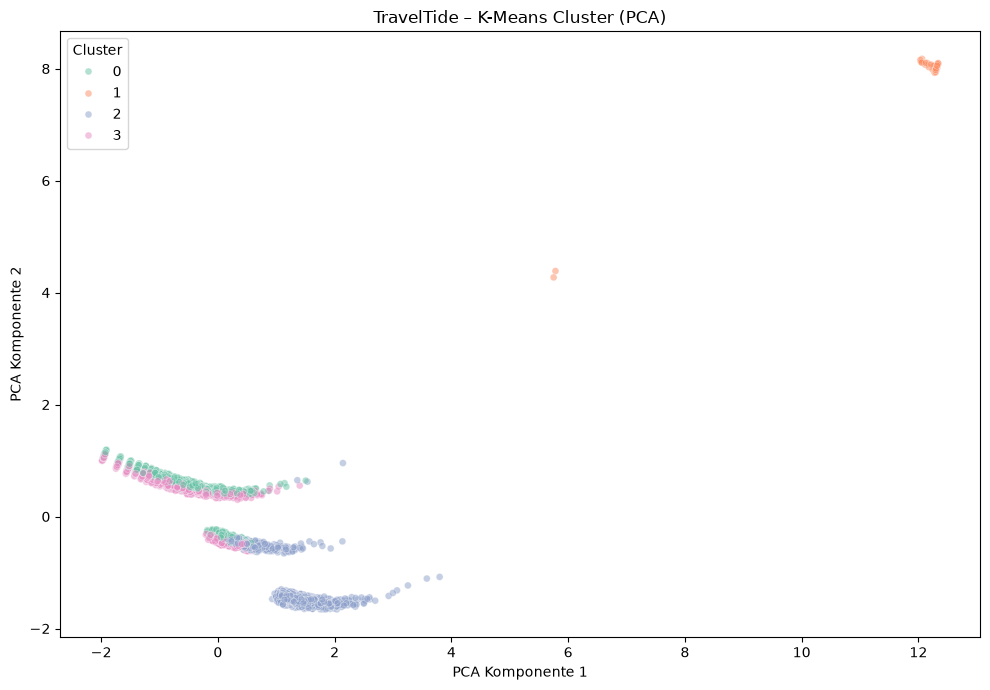

Erklärte Varianz durch PCA: 54.79%
K-MEANS – SESSION-ID-KONTROLLE
Anzahl Sessions: 10,000
Eindeutige Session-IDs: 10,000


,session_id,KMeans_Cluster,flight_booked,hotel_booked,cancellation,page_clicks,session_duration_min
1564942,32878-ddd6438c473e46e0bc38d86a77dce174,2,True,True,False,28,3.350000
2954666,198465-f46407c4f045412c9a1c495aaeb54a1d,2,True,True,False,30,3.783333
1280225,91651-e2f80920bc8e48a6a9820d3b07d4854b,3,False,False,False,11,1.333333
2476691,364011-51f024f255fd4e26827cda7897d411e4,3,False,False,False,8,1.016667
1182763,96455-3e1a1d8425d845358b0ae5bc3f72c7db,0,True,False,False,21,2.633333
3671148,432195-148628d5d2074b0292296d8c0a96b047,3,False,False,False,11,1.450000
1018675,25147-d5b5ef95a8974d8db44f9b73510e6e43,0,False,False,False,9,1.116667
1608048,17087-c1ccd436dfb845c294a8b64fb10b1450,2,True,True,False,17,2.050000
1598622,155414-bdc9a68e8b694776a82cc4ee73971c6c,0,False,True,False,10,1.333333
1614094,87706-75e5e3f788b2475caadd46f855255efe,2,True,True,False,22,2.716667


In [103]:
# ============================================================
# 1. K-MEANS CLUSTERING
# ============================================================

from sklearn.cluster import KMeans

# ------------------------------------------------------------
# 1.1 Elbow-Methode: optimale Cluster-Anzahl untersuchen
# ------------------------------------------------------------

inertias = []

k_values = range(2, 9)

for k in k_values:

    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_test.fit(X_sample)

    inertias.append(kmeans_test.inertia_)

# Elbow-Diagramm
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.title("TravelTide – K-Means Elbow-Methode")
plt.xlabel("Anzahl Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 1.2 K-Means mit vier Clustern
# ------------------------------------------------------------

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_sample)

# Originaldaten einschließlich session_id übernehmen
cluster_results = cluster_data.loc[
    sample_indices
].copy()

# Cluster-Zuordnung ergänzen
cluster_results["KMeans_Cluster"] = kmeans_labels

# ------------------------------------------------------------
# 1.3 Cluster-Größen anzeigen
# ------------------------------------------------------------

print("K-MEANS – ANZAHL SESSIONS JE CLUSTER")

display(
    cluster_results["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# ------------------------------------------------------------
# 1.4 Cluster-Merkmale analysieren
# ------------------------------------------------------------

kmeans_profile = cluster_results.groupby(
    "KMeans_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        "cancellation"
    ]
].mean().round(2)

print("K-MEANS – DURCHSCHNITTLICHE CLUSTER-MERKMALE")

display(kmeans_profile)

# ------------------------------------------------------------
# 1.5 Cluster visualisieren (PCA)
# ------------------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_sample)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette="Set2",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – K-Means Cluster (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

print(
    "Erklärte Varianz durch PCA:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

# ------------------------------------------------------------
# 1.6 SESSION-IDs und Cluster-Zuordnung kontrollieren
# ------------------------------------------------------------

print("K-MEANS – SESSION-ID-KONTROLLE")

print(
    f"Anzahl Sessions: {len(cluster_results):,}"
)

print(
    f"Eindeutige Session-IDs: "
    f"{cluster_results['session_id'].nunique():,}"
)

display(
    cluster_results[
        [
            "session_id",
            "KMeans_Cluster",
            "flight_booked",
            "hotel_booked",
            "cancellation",
            "page_clicks",
            "session_duration_min"
        ]
    ].head(20)
)


In [104]:
# ============================================================
# 4.5 K-MEANS CLUSTER 1 AN OUTPUT ANHÄNGEN
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 4.5.1 Dateipfade festlegen
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

TARGET_FILE = TARGET_DIR / "clean_sessions.csv"
OUTPUT_FILE = TARGET_DIR / "clean_all_result.csv"

# ------------------------------------------------------------
# 4.5.2 Session-IDs aus K-Means Cluster 1 übernehmen
# ------------------------------------------------------------

kmeans_selected = cluster_results.loc[
    cluster_results["KMeans_Cluster"] == 1,
    ["session_id", "KMeans_Cluster"]
].copy()

kmeans_selected["session_id"] = (
    kmeans_selected["session_id"].astype("string")
)

kmeans_selected = kmeans_selected.drop_duplicates(
    subset="session_id"
)

print("K-MEANS CLUSTER 1")

print(
    f"Anzahl eindeutiger Session-IDs: "
    f"{len(kmeans_selected):,}"
)

# ------------------------------------------------------------
# 4.5.3 Originaldaten aus clean_sessions.csv laden
# ------------------------------------------------------------

clean_sessions = pd.read_csv(
    TARGET_FILE,
    dtype={"session_id": "string"}
)

# ------------------------------------------------------------
# 4.5.4 Vollständige Datensätze anhand der session_id suchen
# ------------------------------------------------------------

kmeans_sessions = clean_sessions.merge(
    kmeans_selected,
    on="session_id",
    how="inner"
)

print(
    f"Gefundene vollständige Datensätze: "
    f"{len(kmeans_sessions):,}"
)

# ------------------------------------------------------------
# 4.5.5 Bestehende Output-Datei laden
# ------------------------------------------------------------

if not OUTPUT_FILE.exists():
    raise FileNotFoundError(
        f"Output-Datei nicht gefunden: {OUTPUT_FILE}"
    )

existing_results = pd.read_csv(
    OUTPUT_FILE,
    dtype={"session_id": "string"}
)

# ------------------------------------------------------------
# 4.5.6 Bereits vorhandene Session-IDs ausschließen
# ------------------------------------------------------------

existing_ids = existing_results["session_id"].dropna()

new_sessions = kmeans_sessions[
    ~kmeans_sessions["session_id"].isin(existing_ids)
].copy()

# ------------------------------------------------------------
# 4.5.7 Neue Datensätze an bestehende Datei anhängen
# ------------------------------------------------------------

combined_results = pd.concat(
    [existing_results, new_sessions],
    ignore_index=True,
    sort=False
)

# ------------------------------------------------------------
# 4.5.8 Aktualisierte Datei speichern
# ------------------------------------------------------------

combined_results.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print("\nK-MEANS CLUSTER 1 ERFOLGREICH ÜBERNOMMEN")
print(f"Neue Datensätze: {len(new_sessions):,}")
print(
    f"Bereits vorhandene Datensätze: "
    f"{len(kmeans_sessions) - len(new_sessions):,}"
)
print(f"Datensätze insgesamt: {len(combined_results):,}")
print(f"Gespeicherte Datei: {OUTPUT_FILE}")

# ------------------------------------------------------------
# 4.5.9 Kontrolle der übernommenen Daten
# ------------------------------------------------------------

display(
    new_sessions[
        ["session_id", "KMeans_Cluster"]
    ].head(20)
)

# ------------------------------------------------------------
# 4.5.10 Daten für Data Wrangler bereitstellen
# ------------------------------------------------------------

clean_all_result = combined_results.copy()

display(clean_all_result)


K-MEANS CLUSTER 1
Anzahl eindeutiger Session-IDs: 107
Gefundene vollständige Datensätze: 107

K-MEANS CLUSTER 1 ERFOLGREICH ÜBERNOMMEN
Neue Datensätze: 107
Bereits vorhandene Datensätze: 0
Datensätze insgesamt: 107
Gespeicherte Datei: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clean_all_result.csv


,session_id,KMeans_Cluster
0,5921-cfd12355449d46ff99d3b6fbf016a80c,1
1,7399-1248663449ef4b74a813684c4c21c14b,1
2,11300-139e4d0992d34736bad5071314bcac21,1
3,16425-016ed898153845e687a56578e05d4fff,1
4,30393-2d51d87aa2ec4eed9e65c96a7a6ca7f9,1
5,32391-16e38a03ef96429c83aefdf7a87d73f7,1
6,35321-fee9c0876b994317883fe0ab6b85b78b,1
7,37500-7d4adab29f28434f9f35fa5a2ab24ab8,1
8,30619-c1c5a11b74b24f04a0e8129c9c2c548f,1
9,57952-8329872215034f809f44881b6c35be6f,1


,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,KMeans_Cluster
0,5921-cfd12355449d46ff99d3b6fbf016a80c,5921,5921-98c49ad6d1e14c68aaa2d9a86fc7fc72,2021-10-25 21:42:05,2021-10-25 23:42:05,True,True,NaN,NaN,True,True,200,True,1.0
1,7399-1248663449ef4b74a813684c4c21c14b,7399,7399-a699ebfb990542b1903de4fc0202270e,2021-06-19 12:21:56,2021-06-19 14:21:56,True,True,NaN,NaN,True,True,200,True,1.0
2,11300-139e4d0992d34736bad5071314bcac21,11300,11300-5d9b7c869a3c49a89658cd9e42b2e10a,2021-08-28 20:26:09,2021-08-28 22:26:09,True,True,NaN,NaN,True,True,200,True,1.0
3,16425-016ed898153845e687a56578e05d4fff,16425,16425-084e90e155ac4bf8a251a74dbf597da1,2022-01-14 17:19:32,2022-01-14 19:19:32,True,True,NaN,NaN,True,True,200,True,1.0
4,30393-2d51d87aa2ec4eed9e65c96a7a6ca7f9,30393,30393-b8406fcd9a144442999b1a4da768ada9,2022-02-14 15:32:12,2022-02-14 17:32:12,True,True,NaN,NaN,True,True,200,True,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,838513-21d305cc91f840f8a6841456f5b24d24,838513,838513-ae89c2bee6de4250bf1eb4432e739ee0,2023-06-10 23:50:39,2023-06-11 00:00:39,True,True,NaN,NaN,True,True,10,True,1.0
103,892232-7fb3dace0c204ab491f8efd57e4f56f7,892232,892232-15330f983b7a44bfbb3ab44c9b7fae95,2023-06-21 21:34:09,2023-06-21 23:34:09,True,True,NaN,NaN,True,True,200,True,1.0
104,217215-8f1f370da1544cbbbd17640bb61ab32e,217215,217215-5e77d3584d954adda523a2accfc9bcc6,2023-06-13 20:38:42,2023-06-13 22:38:42,True,True,NaN,NaN,True,True,200,True,1.0
105,211618-e1be4e174591404e9e19393175feb79b,211618,211618-817a3620780444ddafeea5adba91cf6d,2023-07-02 09:16:40,2023-07-02 11:16:40,True,True,NaN,NaN,True,True,200,True,1.0


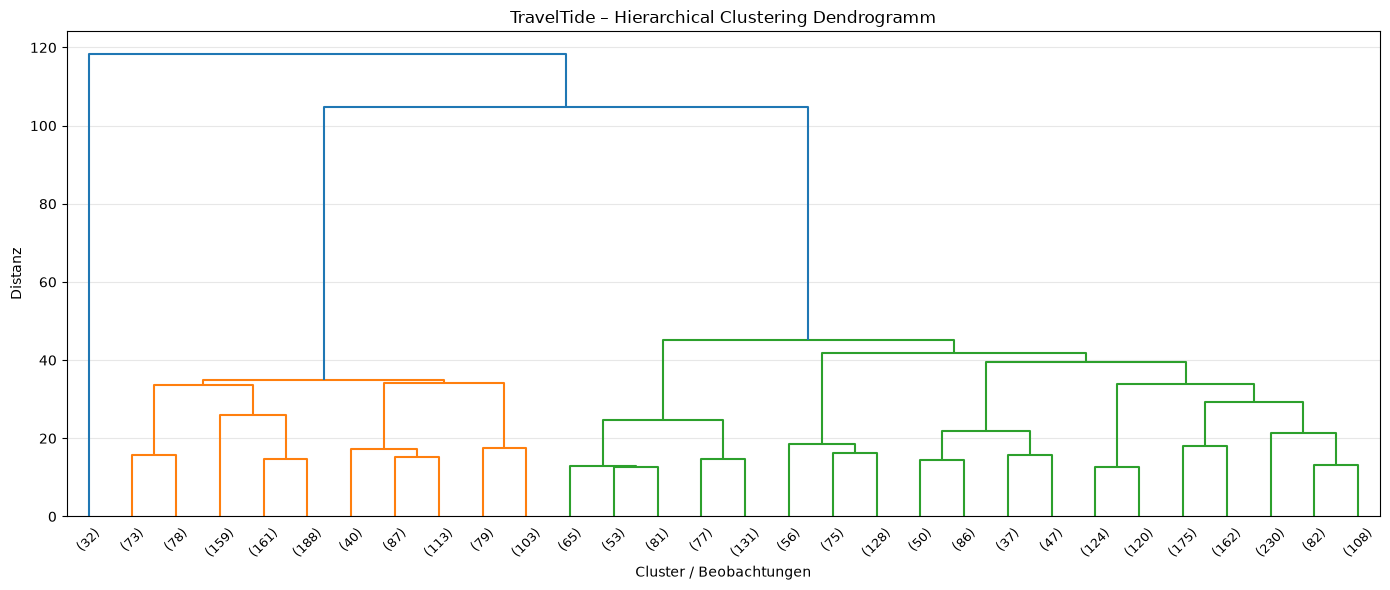

HIERARCHICAL – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
Hierarchical_Cluster,
1,32
2,1081
3,407
4,1480


HIERARCHICAL – CLUSTER-PROFILE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation
Hierarchical_Cluster,,,,,
1,120.00,1.00,1.0,195.06,1.0
2,3.16,0.83,1.0,25.51,0.0
3,1.21,0.00,0.0,9.69,0.0
4,1.52,0.12,0.0,12.22,0.0


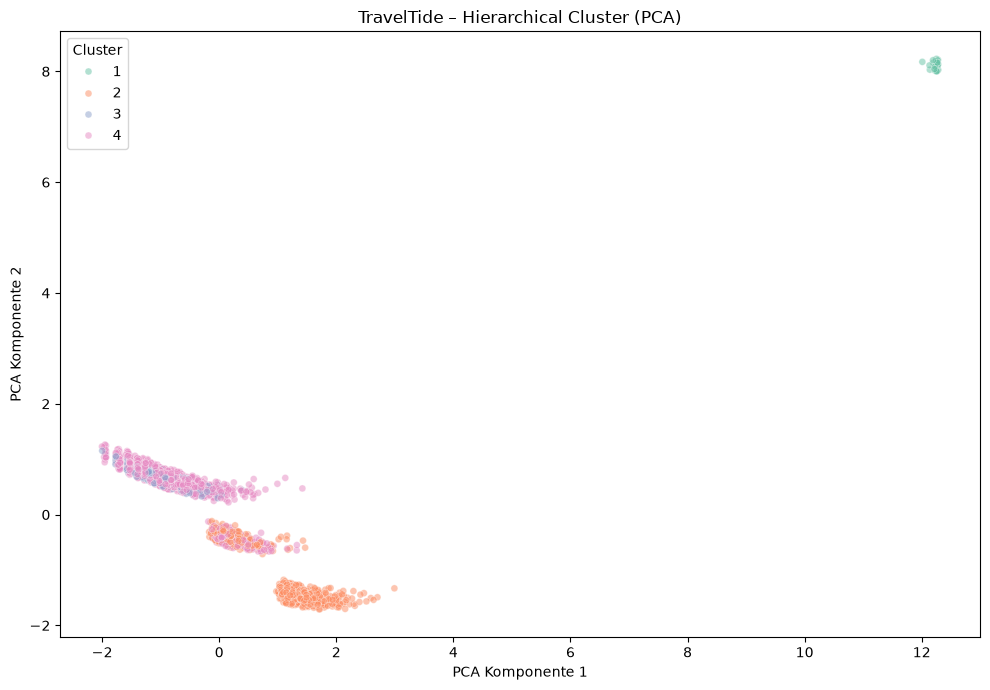

HIERARCHICAL – SESSION-ID-KONTROLLE
Anzahl Sessions: 3,000
Eindeutige Session-IDs: 3,000


,session_id,Hierarchical_Cluster,flight_booked,hotel_booked,cancellation,page_clicks,session_duration_min
1320326,168364-803d909317de4fc6ae764effe0fccb7a,2,True,True,False,23,2.800000
4552586,586372-c2d744309ec84a538b603a15b1f8629b,4,False,False,False,4,0.466667
4648678,746274-6d4f74429035414e85ebeae10f0a8f3b,2,True,True,False,77,9.666667
4249695,357524-ef9844ab04e44ac79b21e8f5b9362639,4,False,False,False,5,0.616667
4880600,743669-37a433bb7204419db7950579ff6ec21e,4,False,False,False,11,1.400000
2172563,387786-fa28db4722c44cc7baffb4e89316c3cd,4,False,False,False,10,1.266667
4183463,632348-3e3d841bbefb4dd080b954b958fa6d5b,3,False,False,False,9,1.066667
4973218,858661-fe655fdfb332440587a42c22d7f3dd67,4,False,False,False,17,2.100000
4899664,843015-b259bf5a639c47af9448cf7c9da5cf4e,2,True,True,False,16,1.983333
5194596,178586-6b0fe133ed59444b8a734a7019db48e8,3,False,False,False,10,1.216667


Hierarchical-Cluster-Ergebnisse inklusive session_id gespeichert.


In [105]:
# ============================================================
# 2. HIERARCHICAL CLUSTERING
# ============================================================

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster
)

# ------------------------------------------------------------
# 2.1 Kleinere Stichprobe erstellen
# ------------------------------------------------------------

hier_sample_size = min(3000, len(X_sample))

X_hier = X_sample.sample(
    n=hier_sample_size,
    random_state=42
)

# ------------------------------------------------------------
# 2.2 Hierarchisches Clustering berechnen
# ------------------------------------------------------------

# session_id wird NICHT für das Clustering verwendet.
# Es werden ausschließlich die Feature-Spalten aus X_hier genutzt.

Z = linkage(
    X_hier,
    method="ward"
)

# ------------------------------------------------------------
# 2.3 Dendrogramm darstellen
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title("TravelTide – Hierarchical Clustering Dendrogramm")
plt.xlabel("Cluster / Beobachtungen")
plt.ylabel("Distanz")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2.4 Vier Cluster erstellen
# ------------------------------------------------------------

hier_labels = fcluster(
    Z,
    t=4,
    criterion="maxclust"
)

# Originaldaten einschließlich session_id übernehmen
# Die Reihenfolge entspricht den Beobachtungen in X_hier.

hier_results = cluster_data.loc[
    X_hier.index
].copy()

# Cluster-Zuordnung ergänzen
hier_results["Hierarchical_Cluster"] = hier_labels

# session_id sicher als String beibehalten
hier_results["session_id"] = hier_results["session_id"].astype("string")

# ------------------------------------------------------------
# 2.5 Cluster-Größen anzeigen
# ------------------------------------------------------------

print("HIERARCHICAL – ANZAHL SESSIONS JE CLUSTER")

display(
    hier_results["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# ------------------------------------------------------------
# 2.6 Cluster-Profile berechnen
# ------------------------------------------------------------

hier_profile = hier_results.groupby(
    "Hierarchical_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        "cancellation"
    ]
].mean().round(2)

print("HIERARCHICAL – CLUSTER-PROFILE")

display(hier_profile)

# ------------------------------------------------------------
# 2.7 Visualisierung mit PCA
# ------------------------------------------------------------

X_hier_pca = PCA(
    n_components=2
).fit_transform(X_hier)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_hier_pca[:, 0],
    y=X_hier_pca[:, 1],
    hue=hier_labels,
    palette="Set2",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – Hierarchical Cluster (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2.8 SESSION-ID-KONTROLLE
# ------------------------------------------------------------

print("HIERARCHICAL – SESSION-ID-KONTROLLE")

print(f"Anzahl Sessions: {len(hier_results):,}")
print(
    f"Eindeutige Session-IDs: "
    f"{hier_results['session_id'].nunique():,}"
)

display(
    hier_results[
        [
            "session_id",
            "Hierarchical_Cluster",
            "flight_booked",
            "hotel_booked",
            "cancellation",
            "page_clicks",
            "session_duration_min"
        ]
    ].head(20)
)

# ------------------------------------------------------------
# 2.9 ERGEBNISSE FÜR WEITERE ANALYSEN SPEICHERN
# ------------------------------------------------------------

# Vollständige Ergebnisse inklusive session_id exportieren

hier_results.to_csv(
    "Hierarchical_Cluster_Results.csv",
    index=False
)

print("Hierarchical-Cluster-Ergebnisse inklusive session_id gespeichert.")


In [106]:
# ============================================================
# KONTROLLE: HIERARCHICAL CLUSTER 1
# ============================================================

print("HIERARCHICAL – KONTROLLE CLUSTER 1")

cluster_1_check = hier_results.loc[
    hier_results["Hierarchical_Cluster"] == 1
].copy()

print(
    f"Anzahl Sessions in Cluster 1: "
    f"{len(cluster_1_check):,}"
)

display(
    cluster_1_check[
        [
            "session_id",
            "Hierarchical_Cluster",
            "flight_booked",
            "hotel_booked",
            "cancellation",
            "page_clicks",
            "session_duration_min"
        ]
    ]
)


HIERARCHICAL – KONTROLLE CLUSTER 1
Anzahl Sessions in Cluster 1: 32


,session_id,Hierarchical_Cluster,flight_booked,hotel_booked,cancellation,page_clicks,session_duration_min
479426,186394-ac1c76f46a1f4bdcb772fcfbe6586151,1,True,True,True,200,120.0
480749,157422-244f514214184f228fb40aab199b789b,1,True,True,True,200,120.0
467555,125966-d505da844d1c4a3b9ef99fb34f1cef1c,1,True,True,True,200,120.0
494877,148669-a4436b75b9bc41b29bc989b089f41a6a,1,True,True,True,163,120.0
457506,11300-139e4d0992d34736bad5071314bcac21,1,True,True,True,200,120.0
456542,5921-cfd12355449d46ff99d3b6fbf016a80c,1,True,True,True,200,120.0
509211,430089-fc5ec05e34a74812b17993e06a2dd1ea,1,True,True,True,197,120.0
460352,37500-7d4adab29f28434f9f35fa5a2ab24ab8,1,True,True,True,200,120.0
474604,72387-b005da8afe8b461a84708284ce67ccef,1,True,True,True,200,120.0
534029,651332-719f5fb0260d46df886196d63b76734d,1,True,True,True,200,120.0


In [108]:
# ============================================================
# KONTROLLE: HIERARCHICAL CLUSTER 1
# INKLUSIVE ID-VERGLEICH MIT clean_all_result.csv
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. Dateipfad festlegen
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

OUTPUT_FILE = TARGET_DIR / "clean_all_result.csv"


# ------------------------------------------------------------
# 2. Hierarchical Cluster 1 auswählen
# ------------------------------------------------------------

cluster_1_check = hier_results.loc[
    hier_results["Hierarchical_Cluster"] == 1
].copy()

cluster_1_check["session_id"] = (
    cluster_1_check["session_id"].astype("string")
)

cluster_1_check = cluster_1_check.drop_duplicates(
    subset="session_id"
)


# ------------------------------------------------------------
# 3. Bestehende Output-Datei laden
# ------------------------------------------------------------

if not OUTPUT_FILE.exists():
    raise FileNotFoundError(
        f"Output-Datei nicht gefunden: {OUTPUT_FILE}"
    )

clean_all_result = pd.read_csv(
    OUTPUT_FILE,
    dtype={"session_id": "string"}
)

# Alle vorhandenen IDs ermitteln
existing_ids = set(
    clean_all_result["session_id"].dropna()
)

# Gesamtzahlen der Output-Datei
total_output_rows = len(clean_all_result)
total_output_ids = clean_all_result["session_id"].nunique()


# ------------------------------------------------------------
# 4. Session-IDs vergleichen
# ------------------------------------------------------------

already_present = cluster_1_check[
    "session_id"
].isin(existing_ids)

# Noch nicht vorhandene Datensätze
new_cluster_1 = cluster_1_check.loc[
    ~already_present
].copy()


# ------------------------------------------------------------
# 5. Ergebnis ausgeben
# ------------------------------------------------------------

print("=" * 60)
print("HIERARCHICAL CLUSTER 1 – ID-VERGLEICH")
print("=" * 60)

print("\nCLUSTER-VERGLEICH")
print("-" * 60)

print(
    f"Cluster 1:                          "
    f"{len(cluster_1_check):,} Datensätze"
)

print(
    f'Davon schon in "clean_all_result.csv": '
    f"{int(already_present.sum()):,}"
)

print(
    f"Kopiert (Differenz):                "
    f"{len(new_cluster_1):,}"
)

print("\nGESAMTÜBERSICHT clean_all_result.csv")
print("-" * 60)

print(
    f"Datensätze insgesamt:               "
    f"{total_output_rows:,}"
)

print(
    f"Eindeutige session_id insgesamt:    "
    f"{total_output_ids:,}"
)

print(
    f"Fehlende session_id:                "
    f"{clean_all_result['session_id'].isna().sum():,}"
)

print("=" * 60)


# ------------------------------------------------------------
# 6. Cluster 1 vollständig anzeigen
# ------------------------------------------------------------

print("\nDATENSÄTZE IN HIERARCHICAL CLUSTER 1")

display(
    cluster_1_check[
        [
            "session_id",
            "Hierarchical_Cluster",
            "flight_booked",
            "hotel_booked",
            "cancellation",
            "page_clicks",
            "session_duration_min"
        ]
    ]
)


# ------------------------------------------------------------
# 7. Noch nicht vorhandene Session-IDs anzeigen
# ------------------------------------------------------------

print("\nNOCH NICHT IN clean_all_result.csv VORHANDEN")

display(
    new_cluster_1[
        [
            "session_id",
            "Hierarchical_Cluster",
            "flight_booked",
            "hotel_booked",
            "cancellation",
            "page_clicks",
            "session_duration_min"
        ]
    ]
)


HIERARCHICAL CLUSTER 1 – ID-VERGLEICH

CLUSTER-VERGLEICH
------------------------------------------------------------
Cluster 1:                          32 Datensätze
Davon schon in "clean_all_result.csv": 32
Kopiert (Differenz):                0

GESAMTÜBERSICHT clean_all_result.csv
------------------------------------------------------------
Datensätze insgesamt:               107
Eindeutige session_id insgesamt:    107
Fehlende session_id:                0

DATENSÄTZE IN HIERARCHICAL CLUSTER 1


,session_id,Hierarchical_Cluster,flight_booked,hotel_booked,cancellation,page_clicks,session_duration_min
479426,186394-ac1c76f46a1f4bdcb772fcfbe6586151,1,True,True,True,200,120.0
480749,157422-244f514214184f228fb40aab199b789b,1,True,True,True,200,120.0
467555,125966-d505da844d1c4a3b9ef99fb34f1cef1c,1,True,True,True,200,120.0
494877,148669-a4436b75b9bc41b29bc989b089f41a6a,1,True,True,True,163,120.0
457506,11300-139e4d0992d34736bad5071314bcac21,1,True,True,True,200,120.0
456542,5921-cfd12355449d46ff99d3b6fbf016a80c,1,True,True,True,200,120.0
509211,430089-fc5ec05e34a74812b17993e06a2dd1ea,1,True,True,True,197,120.0
460352,37500-7d4adab29f28434f9f35fa5a2ab24ab8,1,True,True,True,200,120.0
474604,72387-b005da8afe8b461a84708284ce67ccef,1,True,True,True,200,120.0
534029,651332-719f5fb0260d46df886196d63b76734d,1,True,True,True,200,120.0



NOCH NICHT IN clean_all_result.csv VORHANDEN


,session_id,Hierarchical_Cluster,flight_booked,hotel_booked,cancellation,page_clicks,session_duration_min


DBSCAN – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
DBSCAN_Cluster,
-1,8
0,2918
1,5733
2,612
3,624
4,105


Erkannte Cluster: 5
Sessions im Rauschen: 8
Anteil Rauschen: 0.08%
DBSCAN – CLUSTER-PROFILE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation
DBSCAN_Cluster,,,,,
-1,18.69,0.62,0.62,133.62,0.25
0,3.28,1.00,1.00,26.46,0.00
1,1.41,0.00,0.00,11.36,0.00
2,2.38,1.00,0.00,19.16,0.00
3,2.30,0.00,1.00,18.57,0.00
4,120.00,1.00,1.00,193.41,1.00


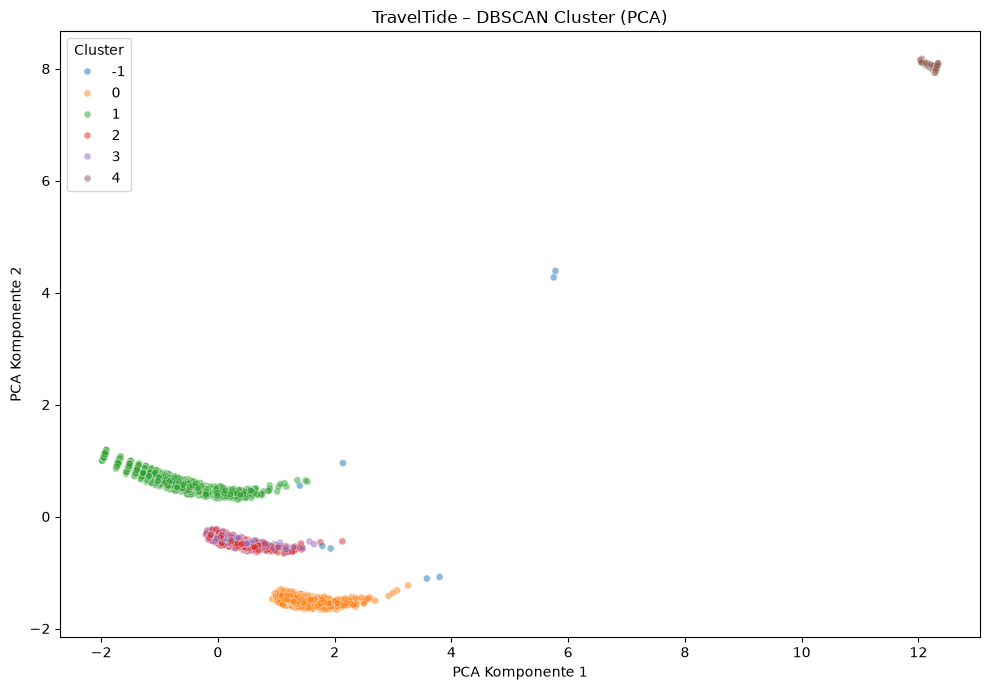

In [109]:
# ============================================================
# 3. DBSCAN CLUSTERING
# ============================================================

from sklearn.cluster import DBSCAN

# ------------------------------------------------------------
# 3.1 DBSCAN durchführen
# ------------------------------------------------------------

dbscan = DBSCAN(
    eps=1.5,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_sample)

dbscan_results = cluster_data.loc[
    X_sample.index
].copy()

dbscan_results["DBSCAN_Cluster"] = dbscan_labels

# ------------------------------------------------------------
# 3.2 Anzahl der Sessions je Cluster
# ------------------------------------------------------------

print("DBSCAN – ANZAHL SESSIONS JE CLUSTER")

display(
    dbscan_results["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# Cluster -1 bedeutet: Rauschen / nicht zugeordnet
noise_count = (
    dbscan_results["DBSCAN_Cluster"] == -1
).sum()

cluster_count = len(
    set(dbscan_labels) - {-1}
)

print(f"Erkannte Cluster: {cluster_count}")
print(f"Sessions im Rauschen: {noise_count:,}")
print(
    f"Anteil Rauschen: "
    f"{noise_count / len(dbscan_results) * 100:.2f}%"
)

# ------------------------------------------------------------
# 3.3 Cluster-Profile berechnen
# ------------------------------------------------------------

dbscan_profile = dbscan_results.groupby(
    "DBSCAN_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        "cancellation"
    ]
].mean().round(2)

print("DBSCAN – CLUSTER-PROFILE")

display(dbscan_profile)

# ------------------------------------------------------------
# 3.4 Visualisierung mit PCA
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=dbscan_labels,
    palette="tab10",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – DBSCAN Cluster (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


In [119]:
# ------------------------------------------------------------
# 3.5.9 Vergleichsausgabe je Cluster und Gesamtbestand
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("ERGEBNIS DES ID-VERGLEICHS")
print("=" * 60)

print("\nDBSCAN CLUSTER -1")
print("-" * 40)
print(f"Cluster -1:                          {len(cluster_minus_1):,} Datensätze")
print(f"Davon schon in clean_all_result.csv: {int(minus_1_already_present.sum()):,}")
print(f"Kopiert (Differenz):                 {len(new_cluster_minus_1):,}")

print("\nDBSCAN CLUSTER 4")
print("-" * 40)
print(f"Cluster 4:                           {len(cluster_4):,} Datensätze")
print(f"Davon schon in clean_all_result.csv: {int(cluster_4_already_present.sum()):,}")
print(f"Kopiert (Differenz):                 {len(new_cluster_4):,}")

print("\n" + "=" * 60)
print("BESTAND: clean_all_result.csv")
print("=" * 60)

print(
    f"Datensätze insgesamt:                "
    f"{len(combined_results):,}"
)

print(
    f"Eindeutige session_id insgesamt:     "
    f"{combined_results['session_id'].nunique():,}"
)

print(
    f"Fehlende session_id:                 "
    f"{combined_results['session_id'].isna().sum():,}"
)

print("=" * 60)




ERGEBNIS DES ID-VERGLEICHS

DBSCAN CLUSTER -1
----------------------------------------
Cluster -1:                          8 Datensätze
Davon schon in clean_all_result.csv: 8
Kopiert (Differenz):                 0

DBSCAN CLUSTER 4
----------------------------------------
Cluster 4:                           105 Datensätze
Davon schon in clean_all_result.csv: 105
Kopiert (Differenz):                 0

BESTAND: clean_all_result.csv
Datensätze insgesamt:                107
Eindeutige session_id insgesamt:     107
Fehlende session_id:                 0



GMM – ANZAHL SESSIONS JE CLUSTER
--------------------------------------------------


,Anzahl Sessions
GMM_Cluster,
0,4176
1,1981
2,3736
3,107



GMM – CLUSTER-PROFILE
--------------------------------------------------


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation,GMM_Confidence
GMM_Cluster,,,,,,
0,3.066,0.846,0.849,24.746,0.0,1.000
1,2.649,0.000,0.000,21.357,0.0,0.971
2,0.704,0.000,0.000,5.638,0.0,0.982
3,117.944,1.000,1.000,189.981,1.0,1.000



GMM – DURCHSCHNITTLICHE ZUORDNUNGSSICHERHEIT
--------------------------------------------------


,Durchschnittliche Confidence
GMM_Cluster,
0,1.000
1,0.971
2,0.982
3,1.000


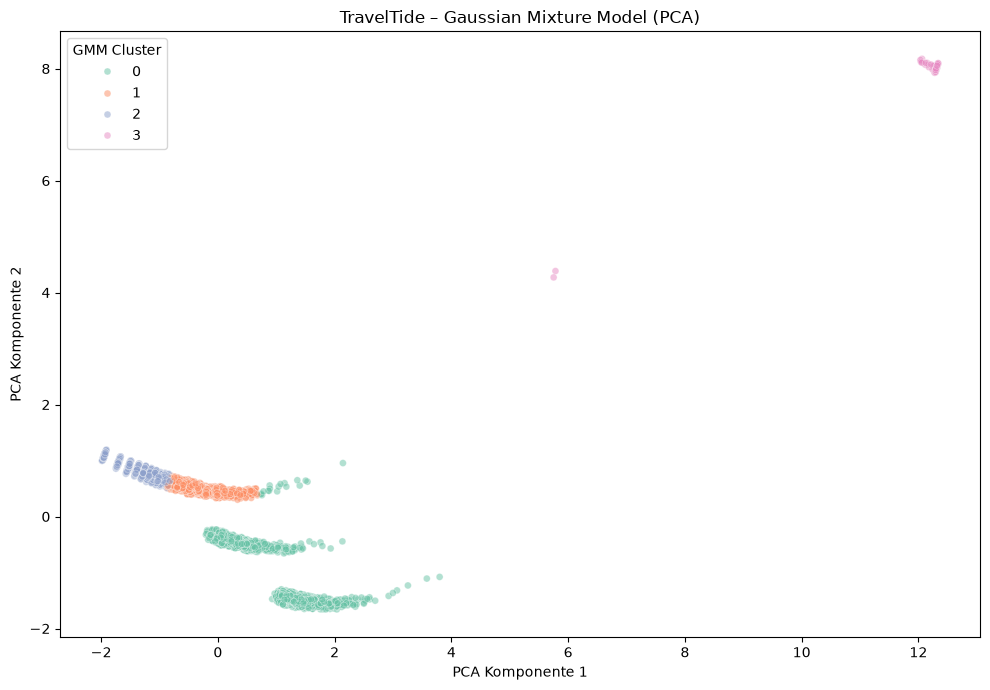


GMM – MODELLGÜTE
--------------------------------------------------
GMM BIC: -163,310.00
GMM AIC: -164,600.65

GMM – SESSION-KONTROLLE
--------------------------------------------------
Sessions insgesamt: 10,000
Eindeutige session_id: 10,000
Fehlende session_id: 0


,session_id,GMM_Cluster,GMM_Confidence,cancellation
1564942,32878-ddd6438c473e46e0bc38d86a77dce174,0,1.000000,False
2954666,198465-f46407c4f045412c9a1c495aaeb54a1d,0,1.000000,False
1280225,91651-e2f80920bc8e48a6a9820d3b07d4854b,2,0.688800,False
2476691,364011-51f024f255fd4e26827cda7897d411e4,2,0.999080,False
1182763,96455-3e1a1d8425d845358b0ae5bc3f72c7db,0,1.000000,False
3671148,432195-148628d5d2074b0292296d8c0a96b047,1,0.936368,False
1018675,25147-d5b5ef95a8974d8db44f9b73510e6e43,2,0.990132,False
1608048,17087-c1ccd436dfb845c294a8b64fb10b1450,0,1.000000,False
1598622,155414-bdc9a68e8b694776a82cc4ee73971c6c,0,1.000000,False
1614094,87706-75e5e3f788b2475caadd46f855255efe,0,1.000000,False


In [112]:
# ============================================================
# 4. GAUSSIAN MIXTURE MODELS (GMM)
# ============================================================

from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 4.1 GMM mit vier Komponenten berechnen
# ------------------------------------------------------------

gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    random_state=42,
    n_init=3
)

# Modell trainieren
gmm.fit(X_sample)

# Cluster-Zuordnung berechnen
gmm_labels = gmm.predict(X_sample)

# Wahrscheinlichkeiten der Cluster-Zugehörigkeit
gmm_probabilities = gmm.predict_proba(X_sample)


# ------------------------------------------------------------
# 4.2 GMM-Ergebnisse erstellen
# ------------------------------------------------------------

gmm_results = cluster_data.loc[
    X_sample.index
].copy()

gmm_results["GMM_Cluster"] = gmm_labels

# Höchste Cluster-Zuordnungswahrscheinlichkeit
gmm_results["GMM_Confidence"] = (
    gmm_probabilities.max(axis=1)
)


# ------------------------------------------------------------
# 4.3 Anzahl der Sessions je Cluster
# ------------------------------------------------------------

print("\nGMM – ANZAHL SESSIONS JE CLUSTER")
print("-" * 50)

display(
    gmm_results["GMM_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)


# ------------------------------------------------------------
# 4.4 Cluster-Profile berechnen
# ------------------------------------------------------------

gmm_profile = gmm_results.groupby(
    "GMM_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        "cancellation",
        "GMM_Confidence"
    ]
].mean().round(3)

print("\nGMM – CLUSTER-PROFILE")
print("-" * 50)

display(gmm_profile)


# ------------------------------------------------------------
# 4.5 Durchschnittliche Zuordnungssicherheit
# ------------------------------------------------------------

print("\nGMM – DURCHSCHNITTLICHE ZUORDNUNGSSICHERHEIT")
print("-" * 50)

display(
    gmm_results.groupby("GMM_Cluster")[
        "GMM_Confidence"
    ].mean().round(3).to_frame(
        "Durchschnittliche Confidence"
    )
)


# ------------------------------------------------------------
# 4.6 Visualisierung mit PCA
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=gmm_labels,
    palette="Set2",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – Gaussian Mixture Model (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="GMM Cluster")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4.7 Modellgüte: BIC und AIC
# ------------------------------------------------------------

gmm_bic = gmm.bic(X_sample)
gmm_aic = gmm.aic(X_sample)

print("\nGMM – MODELLGÜTE")
print("-" * 50)

print(f"GMM BIC: {gmm_bic:,.2f}")
print(f"GMM AIC: {gmm_aic:,.2f}")


# ------------------------------------------------------------
# 4.8 Kontrolle der Session-IDs
# ------------------------------------------------------------

print("\nGMM – SESSION-KONTROLLE")
print("-" * 50)

print(
    f"Sessions insgesamt: "
    f"{len(gmm_results):,}"
)

print(
    f"Eindeutige session_id: "
    f"{gmm_results['session_id'].nunique():,}"
)

print(
    f"Fehlende session_id: "
    f"{gmm_results['session_id'].isna().sum():,}"
)

# Ergebnisse anzeigen
display(
    gmm_results[
        [
            "session_id",
            "GMM_Cluster",
            "GMM_Confidence",
            "cancellation"
        ]
    ].head(20)
)


In [113]:
# ============================================================
# 4.7 GMM CLUSTER 3 – ID-VERGLEICH UND DATENSÄTZE ANHÄNGEN
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 4.7.1 Zielverzeichnis und Dateipfade
# ------------------------------------------------------------

TARGET_DIR = (
    PROJECT_DIR / "data" / "working" / "03_cleaning"
)

TARGET_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = TARGET_DIR / "clean_all_result.csv"
CLUSTER_SESSION_FILE = TARGET_DIR / "Cluster_Session.csv"


# ------------------------------------------------------------
# 4.7.2 Sessions aus GMM-Cluster 3 auswählen
# ------------------------------------------------------------

gmm_cluster_3_sessions = gmm_results.loc[
    gmm_results["GMM_Cluster"] == 3
].copy()

gmm_cluster_3_sessions["session_id"] = (
    gmm_cluster_3_sessions["session_id"].astype("string")
)

gmm_cluster_3_sessions = (
    gmm_cluster_3_sessions.drop_duplicates(
        subset="session_id"
    )
)


# ------------------------------------------------------------
# 4.7.3 clean_all_result.csv laden
# ------------------------------------------------------------

if not OUTPUT_FILE.exists():
    raise FileNotFoundError(
        f"Output-Datei nicht gefunden: {OUTPUT_FILE}"
    )

clean_all_result = pd.read_csv(
    OUTPUT_FILE,
    dtype={"session_id": "string"}
)

# IDs aus clean_all_result.csv
existing_ids = set(
    clean_all_result["session_id"].dropna()
)


# ------------------------------------------------------------
# 4.7.4 GMM Cluster 3 mit clean_all_result.csv vergleichen
# ------------------------------------------------------------

already_present = gmm_cluster_3_sessions[
    "session_id"
].isin(existing_ids)

# Noch nicht vorhandene Datensätze
new_gmm_cluster_3 = gmm_cluster_3_sessions.loc[
    ~already_present
].copy()


# ------------------------------------------------------------
# 4.7.5 Cluster_Session.csv laden
# ------------------------------------------------------------

if CLUSTER_SESSION_FILE.exists():
    cluster_sessions = pd.read_csv(
        CLUSTER_SESSION_FILE,
        dtype={"session_id": "string"}
    )
else:
    cluster_sessions = pd.DataFrame()


# ------------------------------------------------------------
# 4.7.6 Bereits in Cluster_Session.csv vorhandene IDs prüfen
# ------------------------------------------------------------

if (
    not cluster_sessions.empty
    and "session_id" in cluster_sessions.columns
):
    cluster_session_ids = set(
        cluster_sessions["session_id"].dropna()
    )
else:
    cluster_session_ids = set()

# Nur noch nicht in Cluster_Session.csv vorhandene IDs
new_cluster_sessions = gmm_cluster_3_sessions.loc[
    ~gmm_cluster_3_sessions["session_id"].isin(
        cluster_session_ids
    )
].copy()


# ------------------------------------------------------------
# 4.7.7 Neue Datensätze an Cluster_Session.csv anhängen
# ------------------------------------------------------------

combined_cluster_sessions = pd.concat(
    [cluster_sessions, new_cluster_sessions],
    ignore_index=True,
    sort=False
)

combined_cluster_sessions.to_csv(
    CLUSTER_SESSION_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4.7.8 Gesamtbestand clean_all_result.csv ermitteln
# ------------------------------------------------------------

total_output_rows = len(clean_all_result)

total_output_ids = (
    clean_all_result["session_id"].nunique()
)

missing_output_ids = (
    clean_all_result["session_id"].isna().sum()
)


# ------------------------------------------------------------
# 4.7.9 Auswertung ausgeben
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("GMM CLUSTER 3 – ID-VERGLEICH")
print("=" * 65)

print("\nGMM CLUSTER 3")
print("-" * 50)

print(
    f"Cluster 3:                          "
    f"{len(gmm_cluster_3_sessions):,} Datensätze"
)

print(
    f"Davon schon in clean_all_result.csv: "
    f"{int(already_present.sum()):,}"
)

print(
    f"Noch nicht vorhanden (Differenz):    "
    f"{len(new_gmm_cluster_3):,}"
)

print("\nBESTAND: clean_all_result.csv")
print("-" * 50)

print(
    f"Datensätze insgesamt:                "
    f"{total_output_rows:,}"
)

print(
    f"Eindeutige session_id insgesamt:     "
    f"{total_output_ids:,}"
)

print(
    f"Fehlende session_id:                 "
    f"{missing_output_ids:,}"
)

print("\nCLUSTER_SESSION.csv")
print("-" * 50)

print(
    f"Neu hinzugefügte Sessions:           "
    f"{len(new_cluster_sessions):,}"
)

print(
    f"Datensätze insgesamt:                "
    f"{len(combined_cluster_sessions):,}"
)

print(f"Gespeichert unter: {CLUSTER_SESSION_FILE}")

print("=" * 65)


# ------------------------------------------------------------
# 4.7.10 GMM Cluster 3 kontrollieren
# ------------------------------------------------------------

print("\nGMM CLUSTER 3 – SESSION-ÜBERSICHT")

display(
    gmm_cluster_3_sessions[
        [
            "session_id",
            "GMM_Cluster",
            "GMM_Confidence"
        ]
    ]
)

print("\nNOCH NICHT IN clean_all_result.csv VORHANDEN")

display(
    new_gmm_cluster_3[
        [
            "session_id",
            "GMM_Cluster",
            "GMM_Confidence"
        ]
    ]
)


# ------------------------------------------------------------
# 4.7.11 Daten für Data Wrangler bereitstellen
# ------------------------------------------------------------

cluster_sessions = combined_cluster_sessions.copy()

display(cluster_sessions)



GMM CLUSTER 3 – ID-VERGLEICH

GMM CLUSTER 3
--------------------------------------------------
Cluster 3:                          107 Datensätze
Davon schon in clean_all_result.csv: 107
Noch nicht vorhanden (Differenz):    0

BESTAND: clean_all_result.csv
--------------------------------------------------
Datensätze insgesamt:                107
Eindeutige session_id insgesamt:     107
Fehlende session_id:                 0

CLUSTER_SESSION.csv
--------------------------------------------------
Neu hinzugefügte Sessions:           107
Datensätze insgesamt:                107
Gespeichert unter: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\Cluster_Session.csv

GMM CLUSTER 3 – SESSION-ÜBERSICHT


,session_id,GMM_Cluster,GMM_Confidence
474334,161220-54882c8a100640cbb3b4bd7483cc321c,3,1.0
463876,85319-d93a3675c60545d1b92afa308d07dddb,3,1.0
491616,276302-b982f7b2ed7e45d3974ff97cb9109679,3,1.0
531661,728143-74a38c74844b48628ebcd5be3d81a2b2,3,1.0
495596,295929-66c5fab793fc4d43abf5c8a9c7fe1938,3,1.0
...,...,...,...
474454,124774-d7408dceabeb4963a923b27c5f4ac276,3,1.0
496192,232838-0f296980d6d148f38d4d158badfb5b21,3,1.0
496988,251552-95af8d8977ae4f929e749808d70380b3,3,1.0
472821,167842-bf165fe827cc40b58a86f844e88bb99c,3,1.0



NOCH NICHT IN clean_all_result.csv VORHANDEN


,session_id,GMM_Cluster,GMM_Confidence


,session_id,session_start,session_end,flight_booked,hotel_booked,page_clicks,cancellation,session_duration_min,start_hour,weekday,month,page_clicks_log,GMM_Cluster,GMM_Confidence
0,161220-54882c8a100640cbb3b4bd7483cc321c,2022-05-27 13:41:05+00:00,2022-05-27 15:41:05+00:00,True,True,200,True,120.0,13,4,5,5.303305,3,1.0
1,85319-d93a3675c60545d1b92afa308d07dddb,2022-04-03 22:20:06+00:00,2022-04-04 00:20:06+00:00,True,True,200,True,120.0,22,6,4,5.303305,3,1.0
2,276302-b982f7b2ed7e45d3974ff97cb9109679,2022-12-05 21:10:11+00:00,2022-12-05 21:20:11+00:00,True,True,10,True,10.0,21,0,12,2.397895,3,1.0
3,728143-74a38c74844b48628ebcd5be3d81a2b2,2023-06-10 20:20:31+00:00,2023-06-10 22:20:31+00:00,True,True,200,True,120.0,20,5,6,5.303305,3,1.0
4,295929-66c5fab793fc4d43abf5c8a9c7fe1938,2022-11-15 12:37:24+00:00,2022-11-15 14:37:24+00:00,True,True,200,True,120.0,12,1,11,5.303305,3,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,124774-d7408dceabeb4963a923b27c5f4ac276,2022-08-08 19:10:14+00:00,2022-08-08 21:10:14+00:00,True,True,200,True,120.0,19,0,8,5.303305,3,1.0
103,232838-0f296980d6d148f38d4d158badfb5b21,2023-01-05 18:30:24+00:00,2023-01-05 20:30:24+00:00,True,True,200,True,120.0,18,3,1,5.303305,3,1.0
104,251552-95af8d8977ae4f929e749808d70380b3,2023-04-25 11:26:25+00:00,2023-04-25 13:26:25+00:00,True,True,200,True,120.0,11,1,4,5.303305,3,1.0
105,167842-bf165fe827cc40b58a86f844e88bb99c,2022-09-09 20:46:37+00:00,2022-09-09 22:46:37+00:00,True,True,168,True,120.0,20,4,9,5.129899,3,1.0


MONATLICHE ANALYSE


,TOTAL,Flights,Hotels,Cancellations,Avg_Page_Clicks,Avg_Duration
session_start,,,,,,
2021-04-30 00:00:00+00:00,1388,494,493,0,16.83,2.09
2021-05-31 00:00:00+00:00,5256,1855,1893,15,17.34,2.42
2021-06-30 00:00:00+00:00,20955,7286,7316,72,17.29,2.47
2021-07-31 00:00:00+00:00,37162,13268,13539,172,17.63,2.61
2021-08-31 00:00:00+00:00,44601,16108,16149,297,17.93,2.84
2021-09-30 00:00:00+00:00,28436,10495,10517,333,18.83,3.42
2021-10-31 00:00:00+00:00,30463,11066,11143,310,18.47,3.22
2021-11-30 00:00:00+00:00,50014,18096,18297,343,18.06,2.87
2021-12-31 00:00:00+00:00,54554,19766,20000,358,17.98,2.83


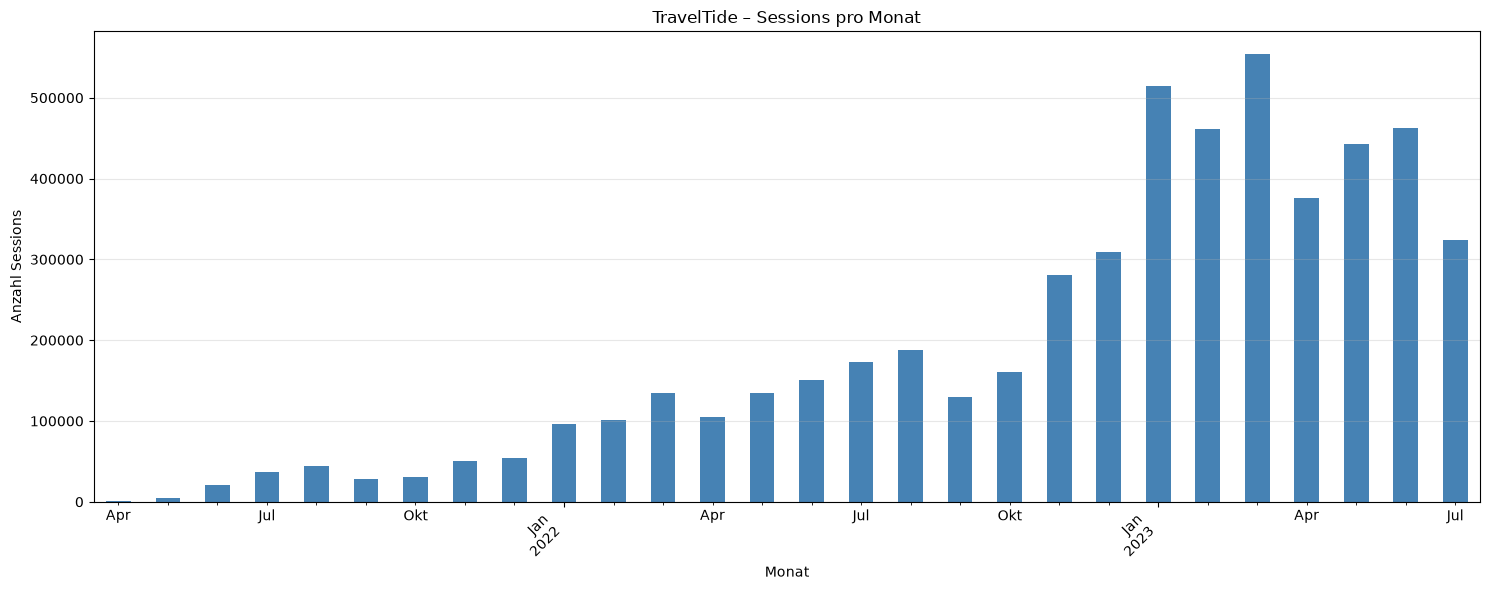

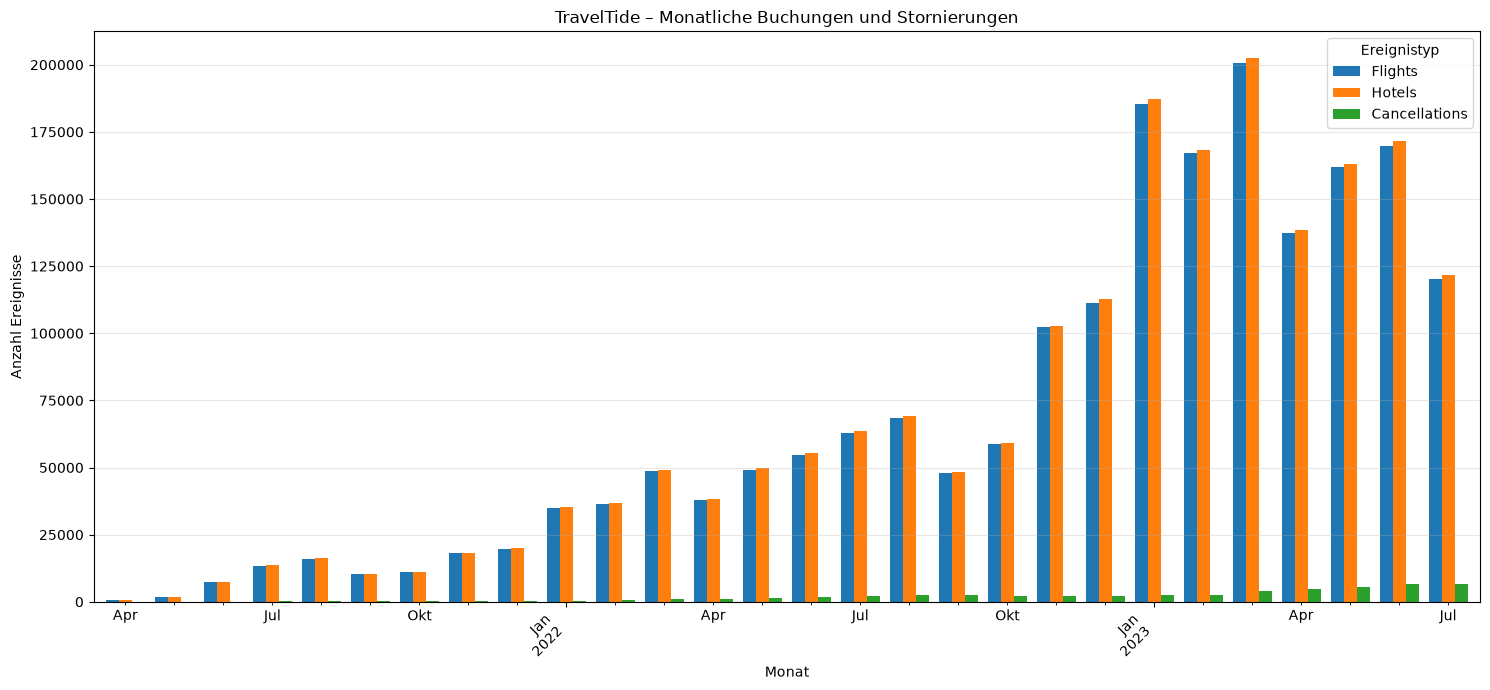

ANALYSE NACH WOCHENTAG


,TOTAL,Flights,Hotels,Cancellations,Avg_Page_Clicks
Montag,771407,280366,282967,7594,18.50
Dienstag,772310,280968,283140,7566,18.47
Mittwoch,773278,281752,284524,7733,18.51
Donnerstag,776706,282853,285698,7840,18.54
Freitag,757900,276298,278659,7861,18.58
Samstag,756894,275628,277856,7569,18.50
Sonntag,762683,276958,279558,7622,18.51


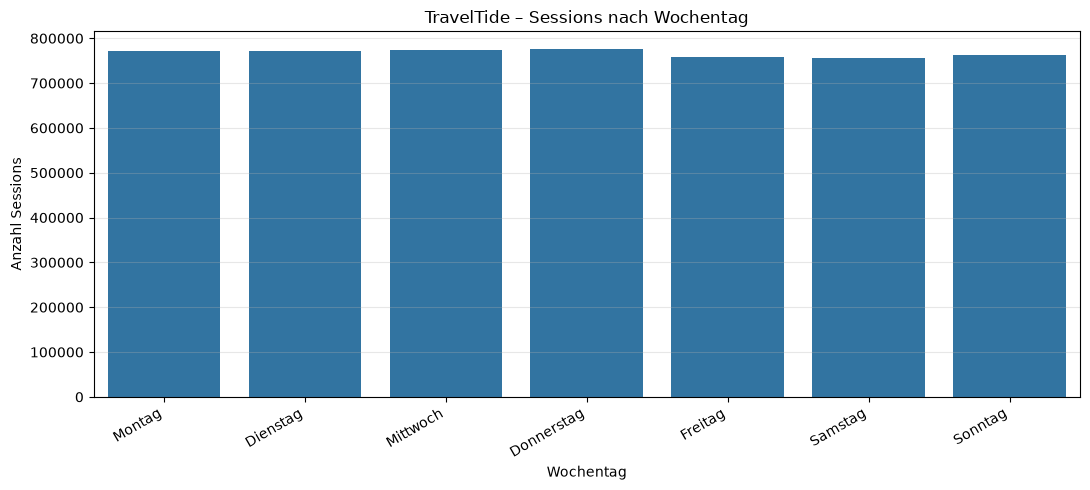

ANALYSE NACH TAGESSTUNDE


,TOTAL,Flights,Hotels,Cancellations
start_hour,,,,
0,28863,10476,10578,298
1,61530,22385,22536,606
2,68268,24955,25210,678
3,75310,27468,27753,789
4,84657,30655,31022,817
5,93690,34355,34664,930
6,104360,38334,38415,1011
7,117499,42706,43163,1142
8,132467,48417,48837,1325


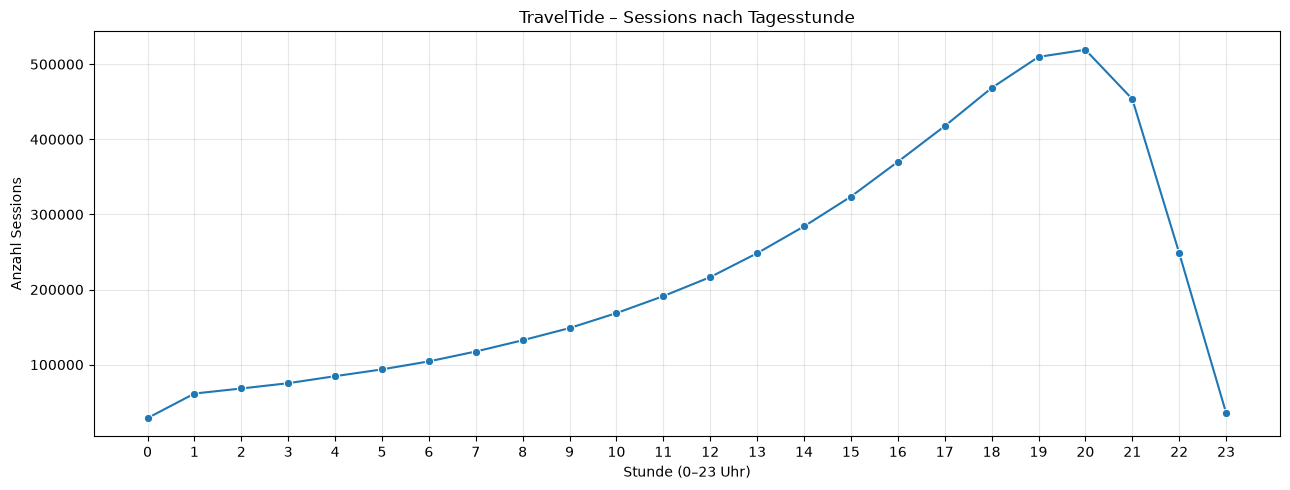

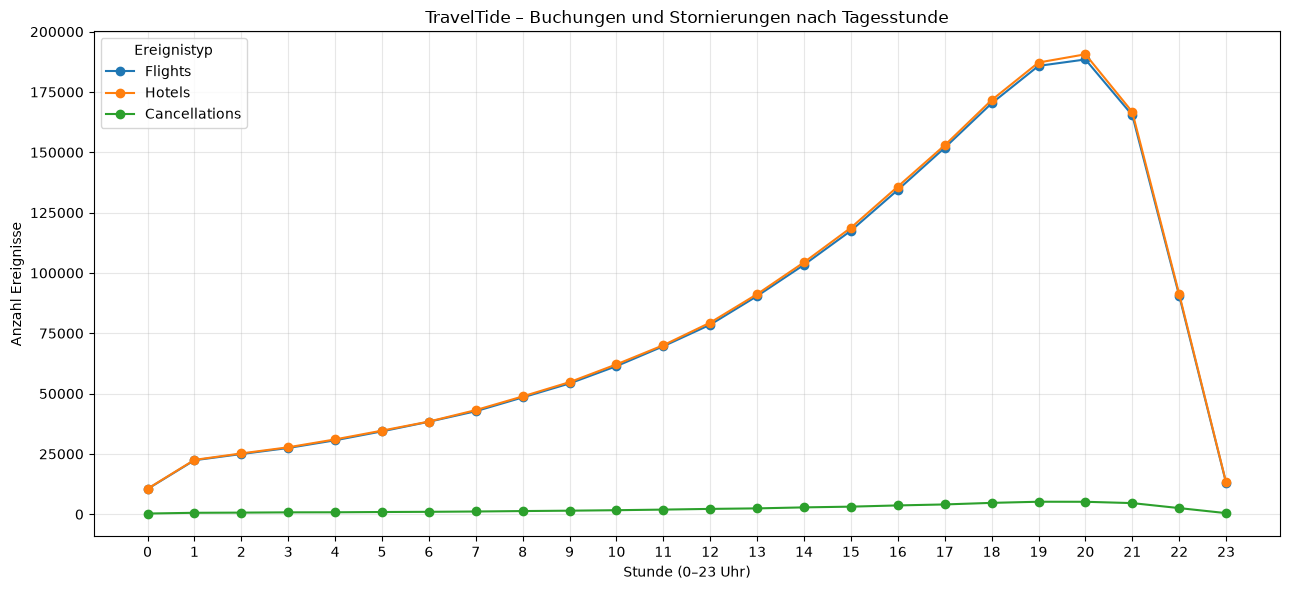

In [114]:
# ============================================================
# 6. ZEITLICHE GRUPPIERUNG
# ============================================================

# ------------------------------------------------------------
# 6.1 Monatliche Aggregation
# ------------------------------------------------------------

monthly_analysis = (
    cluster_data
    .set_index("session_start")
    .resample("ME")
    .agg(
        TOTAL=("session_duration_min", "size"),
        Flights=("flight_booked", "sum"),
        Hotels=("hotel_booked", "sum"),
        Cancellations=("cancellation", "sum"),
        Avg_Page_Clicks=("page_clicks", "mean"),
        Avg_Duration=("session_duration_min", "mean")
    )
)

print("MONATLICHE ANALYSE")

display(monthly_analysis.round(2))


# ------------------------------------------------------------
# 6.2 Sessions pro Monat visualisieren
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

monthly_analysis["TOTAL"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("TravelTide – Sessions pro Monat")
plt.xlabel("Monat")
plt.ylabel("Anzahl Sessions")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.3 Buchungen und Stornierungen pro Monat
# ------------------------------------------------------------

monthly_analysis[
    ["Flights", "Hotels", "Cancellations"]
].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title(
    "TravelTide – Monatliche Buchungen und Stornierungen"
)

plt.xlabel("Monat")
plt.ylabel("Anzahl Ereignisse")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Ereignistyp")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.4 Sessions nach Wochentag
# ------------------------------------------------------------

weekday_names = [
    "Montag",
    "Dienstag",
    "Mittwoch",
    "Donnerstag",
    "Freitag",
    "Samstag",
    "Sonntag"
]

weekday_analysis = (
    cluster_data
    .groupby("weekday")
    .agg(
        TOTAL=("session_duration_min", "size"),
        Flights=("flight_booked", "sum"),
        Hotels=("hotel_booked", "sum"),
        Cancellations=("cancellation", "sum"),
        Avg_Page_Clicks=("page_clicks", "mean")
    )
)

weekday_analysis.index = [
    weekday_names[i]
    for i in weekday_analysis.index
]

print("ANALYSE NACH WOCHENTAG")

display(weekday_analysis.round(2))

plt.figure(figsize=(11, 5))

sns.barplot(
    x=weekday_analysis.index,
    y=weekday_analysis["TOTAL"]
)

plt.title("TravelTide – Sessions nach Wochentag")
plt.xlabel("Wochentag")
plt.ylabel("Anzahl Sessions")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.5 Sessions nach Tageszeit
# ------------------------------------------------------------

hour_analysis = (
    cluster_data
    .groupby("start_hour")
    .agg(
        TOTAL=("session_duration_min", "size"),
        Flights=("flight_booked", "sum"),
        Hotels=("hotel_booked", "sum"),
        Cancellations=("cancellation", "sum")
    )
)

print("ANALYSE NACH TAGESSTUNDE")

display(hour_analysis)

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=hour_analysis,
    x=hour_analysis.index,
    y="TOTAL",
    marker="o"
)

plt.title("TravelTide – Sessions nach Tagesstunde")
plt.xlabel("Stunde (0–23 Uhr)")
plt.ylabel("Anzahl Sessions")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.6 Buchungsverhalten nach Tagesstunde
# ------------------------------------------------------------

hour_analysis[
    ["Flights", "Hotels", "Cancellations"]
].plot(
    kind="line",
    marker="o",
    figsize=(13, 6)
)

plt.title(
    "TravelTide – Buchungen und Stornierungen nach Tagesstunde"
)

plt.xlabel("Stunde (0–23 Uhr)")
plt.ylabel("Anzahl Ereignisse")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(title="Ereignistyp")

plt.tight_layout()
plt.show()


Die Daten aus clean_all_result.csv analysieren

In [115]:
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Dateipfad festlegen
# --------------------------------------------------

PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

TARGET_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "03_cleaning"
)

OUTPUT_FILE = TARGET_DIR / "clean_all_result.csv"


# --------------------------------------------------
# 2. CSV-Datei als DataFrame laden
# --------------------------------------------------

clean_all_result = pd.read_csv(
    OUTPUT_FILE,
    dtype={"session_id": "string"}
)


# --------------------------------------------------
# 3. DataFrame anzeigen
# --------------------------------------------------

display(clean_all_result)


# --------------------------------------------------
# 4. Übersicht der Daten ausgeben
# --------------------------------------------------

print("Anzahl der Zeilen:", len(clean_all_result))
print("Anzahl der Spalten:", len(clean_all_result.columns))
print(
    "Eindeutige session_id:",
    clean_all_result["session_id"].nunique()
)

print("\nSpaltenübersicht:")
print(clean_all_result.info())


,session_id,user_id,trip_id,session_start,session_end,flight_discount,hotel_discount,flight_discount_amount,hotel_discount_amount,flight_booked,hotel_booked,page_clicks,cancellation,KMeans_Cluster
0,5921-cfd12355449d46ff99d3b6fbf016a80c,5921,5921-98c49ad6d1e14c68aaa2d9a86fc7fc72,2021-10-25 21:42:05,2021-10-25 23:42:05,True,True,NaN,NaN,True,True,200,True,1.0
1,7399-1248663449ef4b74a813684c4c21c14b,7399,7399-a699ebfb990542b1903de4fc0202270e,2021-06-19 12:21:56,2021-06-19 14:21:56,True,True,NaN,NaN,True,True,200,True,1.0
2,11300-139e4d0992d34736bad5071314bcac21,11300,11300-5d9b7c869a3c49a89658cd9e42b2e10a,2021-08-28 20:26:09,2021-08-28 22:26:09,True,True,NaN,NaN,True,True,200,True,1.0
3,16425-016ed898153845e687a56578e05d4fff,16425,16425-084e90e155ac4bf8a251a74dbf597da1,2022-01-14 17:19:32,2022-01-14 19:19:32,True,True,NaN,NaN,True,True,200,True,1.0
4,30393-2d51d87aa2ec4eed9e65c96a7a6ca7f9,30393,30393-b8406fcd9a144442999b1a4da768ada9,2022-02-14 15:32:12,2022-02-14 17:32:12,True,True,NaN,NaN,True,True,200,True,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,838513-21d305cc91f840f8a6841456f5b24d24,838513,838513-ae89c2bee6de4250bf1eb4432e739ee0,2023-06-10 23:50:39,2023-06-11 00:00:39,True,True,NaN,NaN,True,True,10,True,1.0
103,892232-7fb3dace0c204ab491f8efd57e4f56f7,892232,892232-15330f983b7a44bfbb3ab44c9b7fae95,2023-06-21 21:34:09,2023-06-21 23:34:09,True,True,NaN,NaN,True,True,200,True,1.0
104,217215-8f1f370da1544cbbbd17640bb61ab32e,217215,217215-5e77d3584d954adda523a2accfc9bcc6,2023-06-13 20:38:42,2023-06-13 22:38:42,True,True,NaN,NaN,True,True,200,True,1.0
105,211618-e1be4e174591404e9e19393175feb79b,211618,211618-817a3620780444ddafeea5adba91cf6d,2023-07-02 09:16:40,2023-07-02 11:16:40,True,True,NaN,NaN,True,True,200,True,1.0


Anzahl der Zeilen: 107
Anzahl der Spalten: 14
Eindeutige session_id: 107

Spaltenübersicht:
<class 'pandas.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   session_id              107 non-null    string 
 1   user_id                 107 non-null    int64  
 2   trip_id                 107 non-null    str    
 3   session_start           107 non-null    str    
 4   session_end             107 non-null    str    
 5   flight_discount         107 non-null    bool   
 6   hotel_discount          107 non-null    bool   
 7   flight_discount_amount  0 non-null      float64
 8   hotel_discount_amount   0 non-null      float64
 9   flight_booked           107 non-null    bool   
 10  hotel_booked            107 non-null    bool   
 11  page_clicks             107 non-null    int64  
 12  cancellation            107 non-null    bool   
 13  KMeans_Cluster

Anzahl aller Datensätze: 107
Anzahl gültiger Sessions: 107
Ungültige oder fehlende Zeitangaben: 0

----------------------------------------
KÜRZESTE SESSION
----------------------------------------
Dauer: 10.00 Minuten
Startdatum: 2022-12-05
Wochentag: Montag
Startuhrzeit: 21:10:11

----------------------------------------
LÄNGSTE SESSION
----------------------------------------
Dauer: 120.00 Minuten
Startdatum: 2021-10-25
Wochentag: Montag
Startuhrzeit: 21:42:05

----------------------------------------
ÜBERSICHT SESSION-DAUER
----------------------------------------
count    107.00
mean     117.94
std       14.97
min       10.00
25%      120.00
50%      120.00
75%      120.00
max      120.00
Name: session_duration_min, dtype: float64

----------------------------------------
SESSIONS NACH WOCHENTAG
----------------------------------------
session_weekday
Montag        24
Dienstag      18
Mittwoch      11
Donnerstag    10
Freitag       17
Samstag       11
Sonntag       16
Name: count,

C:\Users\Cjjru\AppData\Local\Temp\ipykernel_9432\1900210059.py:45: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  clean_all_result["session_start"].dt.dayofweek.map(weekday_names)


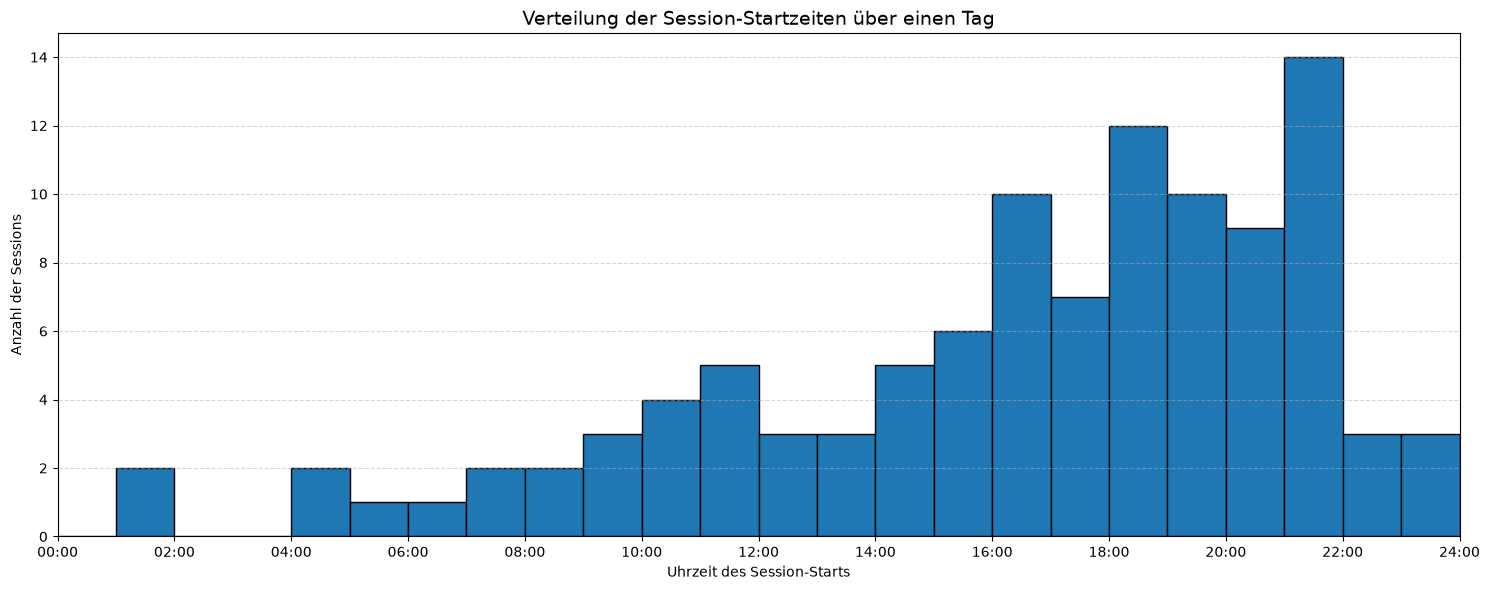

In [120]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Zeitspalten in datetime umwandeln
# --------------------------------------------------

clean_all_result["session_start"] = pd.to_datetime(
    clean_all_result["session_start"],
    errors="coerce"
)

clean_all_result["session_end"] = pd.to_datetime(
    clean_all_result["session_end"],
    errors="coerce"
)


# --------------------------------------------------
# 2. Session-Dauer berechnen
# --------------------------------------------------

clean_all_result["session_duration_min"] = (
    clean_all_result["session_end"]
    - clean_all_result["session_start"]
).dt.total_seconds() / 60


# --------------------------------------------------
# 3. Wochentag und Startuhrzeit ermitteln
# --------------------------------------------------

weekday_names = {
    0: "Montag",
    1: "Dienstag",
    2: "Mittwoch",
    3: "Donnerstag",
    4: "Freitag",
    5: "Samstag",
    6: "Sonntag"
}

clean_all_result["session_weekday"] = (
    clean_all_result["session_start"].dt.dayofweek.map(weekday_names)
)

clean_all_result["session_start_time"] = (
    clean_all_result["session_start"].dt.strftime("%H:%M:%S")
)


# --------------------------------------------------
# 4. Gültige Sessions auswählen
# --------------------------------------------------

valid_sessions = clean_all_result.loc[
    clean_all_result["session_start"].notna()
    & clean_all_result["session_end"].notna()
    & (clean_all_result["session_duration_min"] >= 0)
].copy()

print("Anzahl aller Datensätze:", len(clean_all_result))
print("Anzahl gültiger Sessions:", len(valid_sessions))
print(
    "Ungültige oder fehlende Zeitangaben:",
    len(clean_all_result) - len(valid_sessions)
)


# --------------------------------------------------
# 5. Minimale und maximale Session-Dauer
# --------------------------------------------------

shortest_session = valid_sessions.loc[
    valid_sessions["session_duration_min"].idxmin()
]

longest_session = valid_sessions.loc[
    valid_sessions["session_duration_min"].idxmax()
]

print("\n----------------------------------------")
print("KÜRZESTE SESSION")
print("----------------------------------------")

print(f"Dauer: {shortest_session['session_duration_min']:.2f} Minuten")
print(f"Startdatum: {shortest_session['session_start'].date()}")
print(f"Wochentag: {shortest_session['session_weekday']}")
print(f"Startuhrzeit: {shortest_session['session_start_time']}")

print("\n----------------------------------------")
print("LÄNGSTE SESSION")
print("----------------------------------------")

print(f"Dauer: {longest_session['session_duration_min']:.2f} Minuten")
print(f"Startdatum: {longest_session['session_start'].date()}")
print(f"Wochentag: {longest_session['session_weekday']}")
print(f"Startuhrzeit: {longest_session['session_start_time']}")


# --------------------------------------------------
# 6. Weitere Kennzahlen zur Session-Dauer
# --------------------------------------------------

print("\n----------------------------------------")
print("ÜBERSICHT SESSION-DAUER")
print("----------------------------------------")

print(
    valid_sessions["session_duration_min"].describe()
    .round(2)
)


# --------------------------------------------------
# 7. Sessions nach Wochentag
# --------------------------------------------------

weekday_order = [
    "Montag",
    "Dienstag",
    "Mittwoch",
    "Donnerstag",
    "Freitag",
    "Samstag",
    "Sonntag"
]

weekday_counts = (
    valid_sessions["session_weekday"]
    .value_counts()
    .reindex(weekday_order, fill_value=0)
)

print("\n----------------------------------------")
print("SESSIONS NACH WOCHENTAG")
print("----------------------------------------")

print(weekday_counts)


# --------------------------------------------------
# 8. Startzeiten über einen vollständigen Tag
# --------------------------------------------------

# Startzeit in Sekunden seit Mitternacht umrechnen
start_seconds = (
    valid_sessions["session_start"].dt.hour * 3600
    + valid_sessions["session_start"].dt.minute * 60
    + valid_sessions["session_start"].dt.second
)

# Stundenweise Häufigkeit berechnen
hourly_counts = (
    valid_sessions["session_start"]
    .dt.hour
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

print("\n----------------------------------------")
print("SESSIONS NACH STARTSTUNDE")
print("----------------------------------------")

hourly_counts.index = [
    f"{hour:02d}:00–{hour:02d}:59"
    for hour in hourly_counts.index
]

print(hourly_counts)


# --------------------------------------------------
# 9. Grafik: Session-Starts über 24 Stunden
# --------------------------------------------------

plt.figure(figsize=(15, 6))

plt.hist(
    start_seconds,
    bins=np.arange(0, 86401, 3600),
    edgecolor="black"
)

# Zeitachse von 00:00 bis 24:00
plt.xticks(
    np.arange(0, 86401, 7200),
    [
        f"{hour:02d}:00"
        for hour in range(0, 25, 2)
    ]
)

plt.xlim(0, 86400)

plt.title(
    "Verteilung der Session-Startzeiten über einen Tag",
    fontsize=14
)

plt.xlabel("Uhrzeit des Session-Starts")
plt.ylabel("Anzahl der Sessions")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.tight_layout()
plt.show()


Cleaning session

In [137]:
import pandas as pd
from pathlib import Path

# 1. Pfade festlegen
target_dir = Path(TARGET_DIR)
target_file = Path(TARGET_FILE)

deleted_file = target_dir / "deleted_sessions.csv"

# Sicherstellen, dass der Zielordner existiert
target_dir.mkdir(parents=True, exist_ok=True)

# 2. TARGET_FILE einlesen
sessions = pd.read_csv(target_file)

# 3. session_start in Datumsformat umwandeln
sessions["session_start"] = pd.to_datetime(
    sessions["session_start"],
    errors="coerce"
)

# 4. Stichtag festlegen
cutoff_date = pd.Timestamp("2023-01-05")

# 5. Zu löschende Sessions identifizieren
delete_mask = sessions["session_start"] < cutoff_date

# 6. Zu löschende Datensätze kopieren
deleted_sessions = sessions.loc[delete_mask].copy()

# 7. Gelöschte Datensätze an deleted_sessions.csv anhängen
if not deleted_sessions.empty:
    deleted_sessions.to_csv(
        deleted_file,
        mode="a",
        header=not deleted_file.exists(),
        index=False
    )

# 8. Datensätze aus TARGET_FILE entfernen
sessions = sessions.loc[~delete_mask].copy()

# 9. TARGET_FILE aktualisieren
sessions.to_csv(target_file, index=False)

# 10. Kennzahlen berechnen
copied_count = len(deleted_sessions)
remaining_count = len(sessions)

# 11. Cleaning-Ergebnis anzeigen
print("CLEANING ERGEBNIS")
print("-" * 40)
print(f"In deleted_sessions.csv kopiert: {copied_count:,}")
print(f"Verbleibende Sessions:            {remaining_count:,}")
print(f"Ursprüngliche Sessions:           {copied_count + remaining_count:,}")

CLEANING ERGEBNIS
----------------------------------------
In deleted_sessions.csv kopiert: 2,323,079
Verbleibende Sessions:            3,084,984
Ursprüngliche Sessions:           5,408,063


In [138]:
import pandas as pd
from pathlib import Path

# 1. Dateipfade festlegen
target_dir = Path(TARGET_DIR)
target_file = Path(TARGET_FILE)
deleted_file = target_dir / "deleted_sessions.csv"

# 2. TARGET_FILE einlesen
sessions = pd.read_csv(target_file)

# 3. Ursprüngliche Anzahl feststellen
original_count = len(sessions)

# 4. page_clicks in numerische Werte umwandeln
sessions["page_clicks"] = pd.to_numeric(
    sessions["page_clicks"],
    errors="coerce"
)

# 5. Sessions mit weniger als 8 page_clicks identifizieren
delete_mask = sessions["page_clicks"] < 8

# 6. Zu löschende Datensätze kopieren
new_deleted_sessions = sessions.loc[delete_mask].copy()

# 7. Datensätze an deleted_sessions.csv anhängen
if not new_deleted_sessions.empty:
    new_deleted_sessions.to_csv(
        deleted_file,
        mode="a",
        header=not deleted_file.exists(),
        index=False
    )

# 8. Datensätze aus TARGET_FILE entfernen
sessions = sessions.loc[~delete_mask].copy()

# 9. Bereinigte TARGET_FILE speichern
sessions.to_csv(target_file, index=False)

# 10. Kennzahlen aktualisieren
copied_count = len(new_deleted_sessions)
remaining_count = len(sessions)

# 11. Cleaning-Ergebnis anzeigen
print("CLEANING ERGEBNIS")
print("-" * 40)
print(f"In deleted_sessions.csv kopiert: {copied_count:,}")
print(f"Verbleibende Sessions:            {remaining_count:,}")
print(f"Ursprüngliche Sessions:           {original_count:,}")

CLEANING ERGEBNIS
----------------------------------------
In deleted_sessions.csv kopiert: 832,895
Verbleibende Sessions:            2,252,089
Ursprüngliche Sessions:           3,084,984


In [139]:
import pandas as pd
from pathlib import Path

# 1. Dateipfade festlegen
target_dir = Path(TARGET_DIR)
target_file = Path(TARGET_FILE)
deleted_file = target_dir / "deleted_sessions.csv"

# 2. TARGET_FILE einlesen
sessions = pd.read_csv(target_file)

# 3. Ursprüngliche Anzahl feststellen
original_count = len(sessions)

# 4. page_clicks in numerische Werte umwandeln
sessions["page_clicks"] = pd.to_numeric(
    sessions["page_clicks"],
    errors="coerce"
)

# 5. Sessions mit mehr als 44 page_clicks identifizieren
delete_mask = sessions["page_clicks"] > 44

# 6. Zu löschende Datensätze kopieren
new_deleted_sessions = sessions.loc[delete_mask].copy()

# 7. Datensätze an deleted_sessions.csv anhängen
if not new_deleted_sessions.empty:
    new_deleted_sessions.to_csv(
        deleted_file,
        mode="a",
        header=not deleted_file.exists(),
        index=False
    )

# 8. Datensätze aus TARGET_FILE entfernen
sessions = sessions.loc[~delete_mask].copy()

# 9. Bereinigte TARGET_FILE speichern
sessions.to_csv(target_file, index=False)

# 10. Kennzahlen berechnen
copied_count = len(new_deleted_sessions)
remaining_count = len(sessions)

# 11. Cleaning-Ergebnis anzeigen
print("CLEANING ERGEBNIS")
print("-" * 40)
print(f"In deleted_sessions.csv kopiert: {copied_count:,}")
print(f"Verbleibende Sessions:            {remaining_count:,}")
print(f"Ursprüngliche Sessions:           {original_count:,}")

CLEANING ERGEBNIS
----------------------------------------
In deleted_sessions.csv kopiert: 155,790
Verbleibende Sessions:            2,096,299
Ursprüngliche Sessions:           2,252,089


In [140]:
# ============================================================
# 0. DATEN VORBEREITEN – EINMALIG AUSFÜHREN
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 0.1 Prüfen, ob sessions existiert
# ------------------------------------------------------------

if "sessions" not in globals():
    raise NameError(
        "Der DataFrame 'sessions' wurde noch nicht definiert."
    )

if sessions.empty:
    raise ValueError("Der DataFrame 'sessions' ist leer.")

# ------------------------------------------------------------
# 0.2 Richtige Cancellation-Spalte erkennen
# ------------------------------------------------------------

if "cancellation" in sessions.columns:
    cancellation_col = "cancellation"
elif "cancellations" in sessions.columns:
    cancellation_col = "cancellations"
else:
    raise ValueError(
        "Keine Spalte 'cancellation' oder "
        "'cancellations' gefunden."
    )

# ------------------------------------------------------------
# 0.3 Benötigte Spalten überprüfen
# ------------------------------------------------------------

required_columns = [
    "session_start",
    "session_end",
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    cancellation_col
]

missing_columns = [
    col for col in required_columns
    if col not in sessions.columns
]

if missing_columns:
    raise ValueError(
        f"Folgende Spalten fehlen: {missing_columns}"
    )

cluster_data = sessions[required_columns].copy()

# ------------------------------------------------------------
# 0.4 Zeitstempel konvertieren
# ------------------------------------------------------------

cluster_data["session_start"] = pd.to_datetime(
    cluster_data["session_start"],
    errors="coerce",
    utc=True
)

cluster_data["session_end"] = pd.to_datetime(
    cluster_data["session_end"],
    errors="coerce",
    utc=True
)

# ------------------------------------------------------------
# 0.5 Numerische Spalten konvertieren
# ------------------------------------------------------------

numeric_columns = [
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    cancellation_col
]

for col in numeric_columns:
    cluster_data[col] = pd.to_numeric(
        cluster_data[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 0.6 Session-Dauer berechnen
# ------------------------------------------------------------

cluster_data["session_duration_min"] = (
    cluster_data["session_end"] -
    cluster_data["session_start"]
).dt.total_seconds() / 60

# ------------------------------------------------------------
# 0.7 Zeitliche Merkmale berechnen
# ------------------------------------------------------------

cluster_data["start_hour"] = (
    cluster_data["session_start"].dt.hour
)

cluster_data["weekday"] = (
    cluster_data["session_start"].dt.dayofweek
)

cluster_data["month"] = (
    cluster_data["session_start"].dt.month
)

# ------------------------------------------------------------
# 0.8 Fehlende und ungültige Werte entfernen
# ------------------------------------------------------------

feature_columns = [
    "session_duration_min",
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    cancellation_col,
    "start_hour",
    "weekday",
    "month"
]

cluster_data = cluster_data.dropna(
    subset=feature_columns
).copy()

# Nur gültige Werte behalten
cluster_data = cluster_data[
    (cluster_data["session_duration_min"] >= 0) &
    (cluster_data["page_clicks"] >= 0) &
    (cluster_data["flight_booked"] >= 0) &
    (cluster_data["hotel_booked"] >= 0) &
    (cluster_data[cancellation_col] >= 0)
].copy()

# Prüfen, ob noch Daten vorhanden sind
if cluster_data.empty:
    raise ValueError(
        "Nach der Datenbereinigung sind keine Sessions übrig."
    )

# ------------------------------------------------------------
# 0.9 Page Clicks logarithmisch transformieren
# ------------------------------------------------------------

cluster_data["page_clicks_log"] = np.log1p(
    cluster_data["page_clicks"]
)

# ------------------------------------------------------------
# 0.10 Merkmale für das Clustering festlegen
# ------------------------------------------------------------

feature_columns = [
    "session_duration_min",
    "flight_booked",
    "hotel_booked",
    "page_clicks_log",
    cancellation_col,
    "start_hour",
    "weekday",
    "month"
]

X = cluster_data[feature_columns].copy()

# Zusätzliche Prüfung auf unendliche Werte
X = X.replace([np.inf, -np.inf], np.nan)

valid_indices = X.dropna().index

X = X.loc[valid_indices]
cluster_data = cluster_data.loc[valid_indices].copy()

if len(X) < 2:
    raise ValueError(
        "Zu wenige gültige Sessions für das Clustering."
    )

# ------------------------------------------------------------
# 0.11 Daten standardisieren
# ------------------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    index=X.index,
    columns=feature_columns
)

# ------------------------------------------------------------
# 0.12 Stichprobe für die Clustering-Verfahren erstellen
# ------------------------------------------------------------

sample_size = min(10000, len(cluster_data))

sample_indices = cluster_data.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_scaled.loc[sample_indices].copy()

# ------------------------------------------------------------
# 0.13 Ergebnisse kontrollieren
# ------------------------------------------------------------

print("DATENVORBEREITUNG ABGESCHLOSSEN")
print("-----------------------------------")

print(f"Ursprüngliche Sessions: {len(sessions):,}")
print(f"Bereinigte Sessions: {len(cluster_data):,}")
print(f"Sessions für Clustering: {len(X_sample):,}")
print(f"Anzahl verwendeter Merkmale: {len(feature_columns)}")

print("\nVerwendete Merkmale:")
print(feature_columns)

print("\nDimensionen der Daten:")
print("X:", X.shape)
print("X_scaled:", X_scaled.shape)
print("X_sample:", X_sample.shape)


C:\Users\Cjjru\AppData\Local\Temp\ipykernel_20972\924439383.py:115: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  cluster_data["session_start"].dt.dayofweek


DATENVORBEREITUNG ABGESCHLOSSEN
-----------------------------------
Ursprüngliche Sessions: 2,096,299
Bereinigte Sessions: 2,086,665
Sessions für Clustering: 10,000
Anzahl verwendeter Merkmale: 8

Verwendete Merkmale:
['session_duration_min', 'flight_booked', 'hotel_booked', 'page_clicks_log', 'cancellation', 'start_hour', 'weekday', 'month']

Dimensionen der Daten:
X: (2086665, 8)
X_scaled: (2086665, 8)
X_sample: (10000, 8)


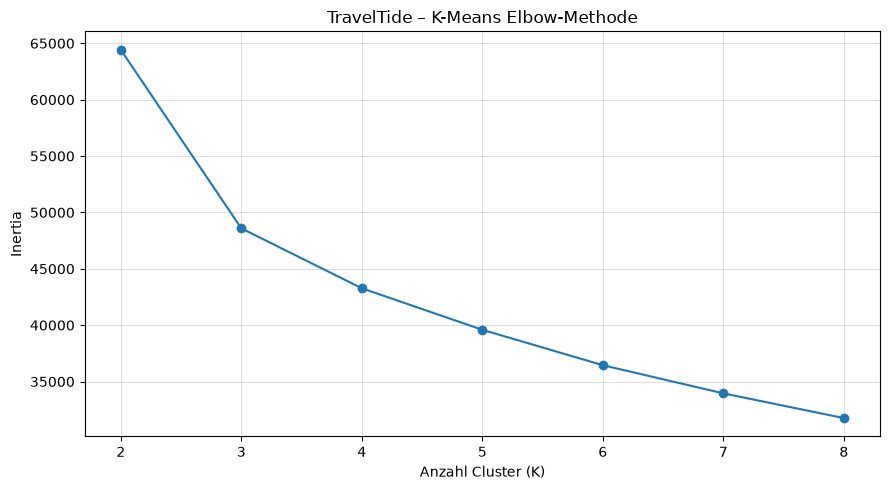

K-MEANS – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
KMeans_Cluster,
0,4158
1,1860
2,3968
3,14


K-MEANS – DURCHSCHNITTLICHE CLUSTER-MERKMALE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation
KMeans_Cluster,,,,,
0,2.97,1.00,1.00,23.98,0.0
1,3.21,0.17,0.21,25.92,0.0
2,1.48,0.14,0.14,11.93,0.0
3,10.00,1.00,1.00,10.00,1.0


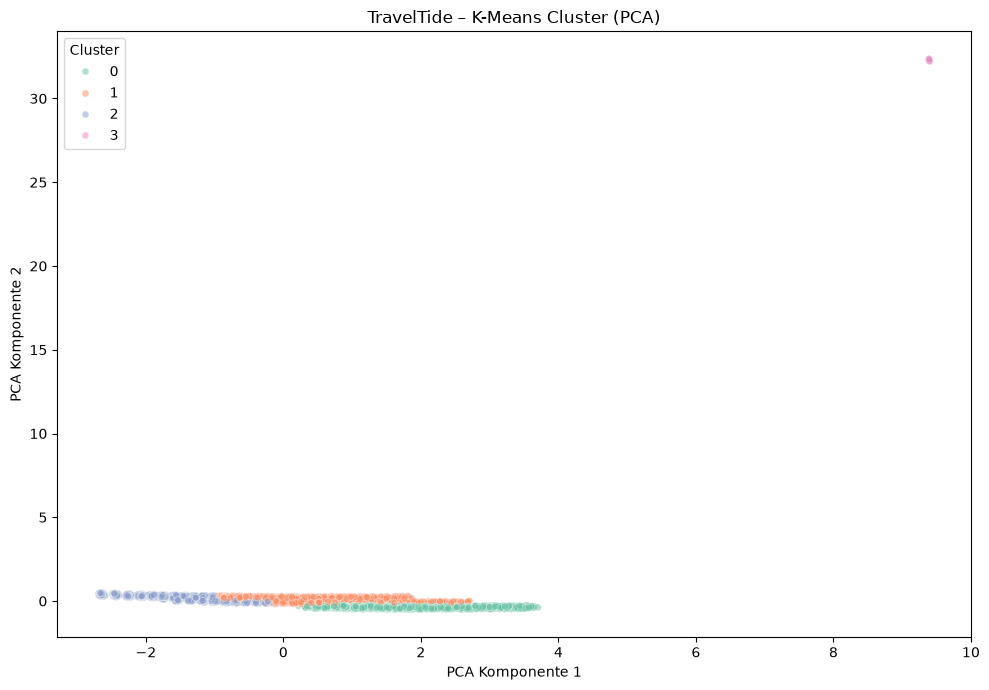

Erklärte Varianz durch PCA: 49.87%


In [141]:
# ============================================================
# 1. K-MEANS CLUSTERING
# ============================================================

from sklearn.cluster import KMeans

# ------------------------------------------------------------
# 1.1 Elbow-Methode: optimale Cluster-Anzahl untersuchen
# ------------------------------------------------------------

inertias = []

k_values = range(2, 9)

for k in k_values:

    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_test.fit(X_sample)

    inertias.append(kmeans_test.inertia_)

# Elbow-Diagramm
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.title("TravelTide – K-Means Elbow-Methode")
plt.xlabel("Anzahl Cluster (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 1.2 K-Means mit vier Clustern
# ------------------------------------------------------------

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_sample)

cluster_results = cluster_data.loc[
    sample_indices
].copy()

cluster_results["KMeans_Cluster"] = kmeans_labels

# ------------------------------------------------------------
# 1.3 Cluster-Größen anzeigen
# ------------------------------------------------------------

print("K-MEANS – ANZAHL SESSIONS JE CLUSTER")

display(
    cluster_results["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# ------------------------------------------------------------
# 1.4 Cluster-Merkmale analysieren
# ------------------------------------------------------------

kmeans_profile = cluster_results.groupby(
    "KMeans_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        cancellation_col
    ]
].mean().round(2)

print("K-MEANS – DURCHSCHNITTLICHE CLUSTER-MERKMALE")

display(kmeans_profile)

# ------------------------------------------------------------
# 1.5 Cluster visualisieren (PCA)
# ------------------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_sample)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette="Set2",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – K-Means Cluster (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

print(
    "Erklärte Varianz durch PCA:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)


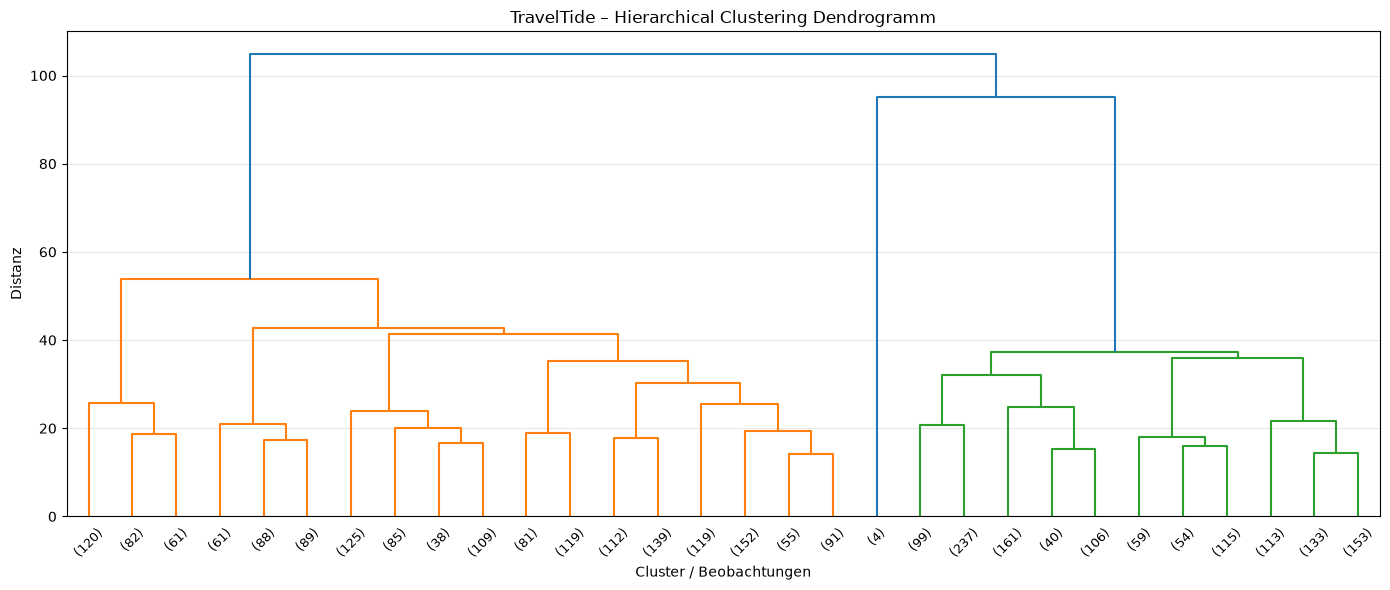

HIERARCHICAL – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
Hierarchical_Cluster,
1,263
2,1463
3,4
4,1270


HIERARCHICAL – CLUSTER-PROFILE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation
Hierarchical_Cluster,,,,,
1,3.60,0.00,0.23,29.01,0.0
2,1.78,0.16,0.16,14.33,0.0
3,10.00,1.00,1.00,10.00,1.0
4,2.95,1.00,1.00,23.82,0.0


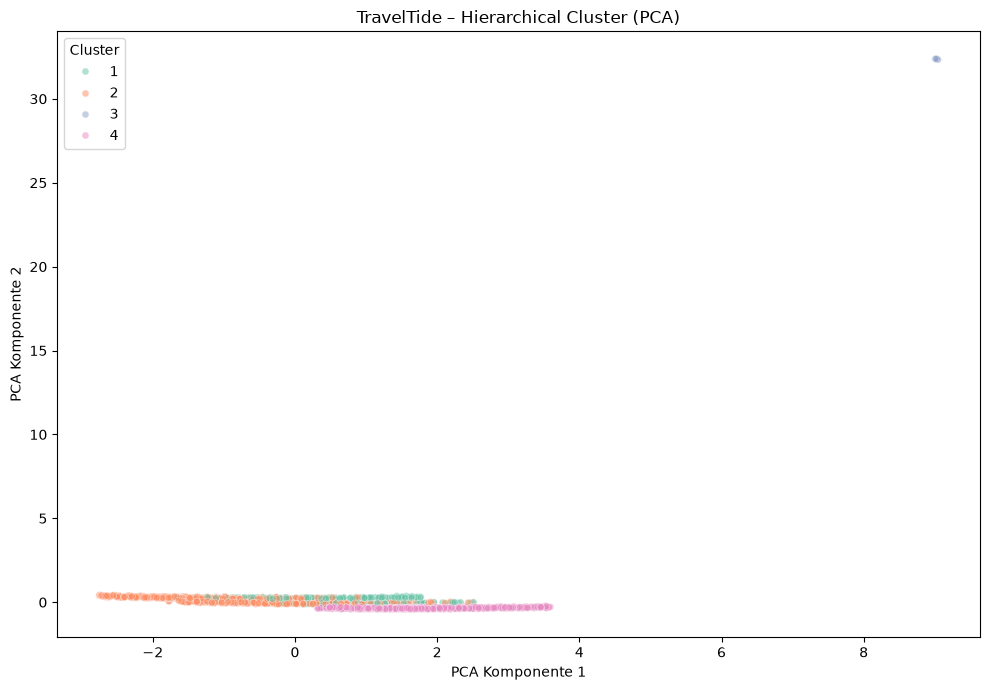

In [142]:
# ============================================================
# 2. HIERARCHICAL CLUSTERING
# ============================================================

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster
)

# ------------------------------------------------------------
# 2.1 Kleinere Stichprobe erstellen
# ------------------------------------------------------------

hier_sample_size = min(3000, len(X_sample))

X_hier = X_sample.sample(
    n=hier_sample_size,
    random_state=42
)

# ------------------------------------------------------------
# 2.2 Hierarchisches Clustering berechnen
# ------------------------------------------------------------

Z = linkage(
    X_hier,
    method="ward"
)

# ------------------------------------------------------------
# 2.3 Dendrogramm darstellen
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=45,
    leaf_font_size=9
)

plt.title("TravelTide – Hierarchical Clustering Dendrogramm")
plt.xlabel("Cluster / Beobachtungen")
plt.ylabel("Distanz")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2.4 Vier Cluster erstellen
# ------------------------------------------------------------

hier_labels = fcluster(
    Z,
    t=4,
    criterion="maxclust"
)

hier_results = cluster_data.loc[
    X_hier.index
].copy()

hier_results["Hierarchical_Cluster"] = hier_labels

# ------------------------------------------------------------
# 2.5 Cluster-Größen anzeigen
# ------------------------------------------------------------

print("HIERARCHICAL – ANZAHL SESSIONS JE CLUSTER")

display(
    hier_results["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# ------------------------------------------------------------
# 2.6 Cluster-Profile berechnen
# ------------------------------------------------------------

hier_profile = hier_results.groupby(
    "Hierarchical_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        cancellation_col
    ]
].mean().round(2)

print("HIERARCHICAL – CLUSTER-PROFILE")

display(hier_profile)

# ------------------------------------------------------------
# 2.7 Visualisierung mit PCA
# ------------------------------------------------------------

X_hier_pca = PCA(
    n_components=2
).fit_transform(X_hier)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_hier_pca[:, 0],
    y=X_hier_pca[:, 1],
    hue=hier_labels,
    palette="Set2",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – Hierarchical Cluster (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


DBSCAN – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
DBSCAN_Cluster,
-1,23
0,4032
1,4158
2,947
3,840


Erkannte Cluster: 4
Sessions im Rauschen: 23
Anteil Rauschen: 0.23%
DBSCAN – CLUSTER-PROFILE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation
DBSCAN_Cluster,,,,,
-1,8.00,0.91,0.7,21.48,0.61
0,1.96,0.00,0.0,15.83,0.00
1,2.97,1.00,1.0,23.98,0.00
2,2.25,0.00,1.0,18.14,0.00
3,2.10,1.00,0.0,16.89,0.00


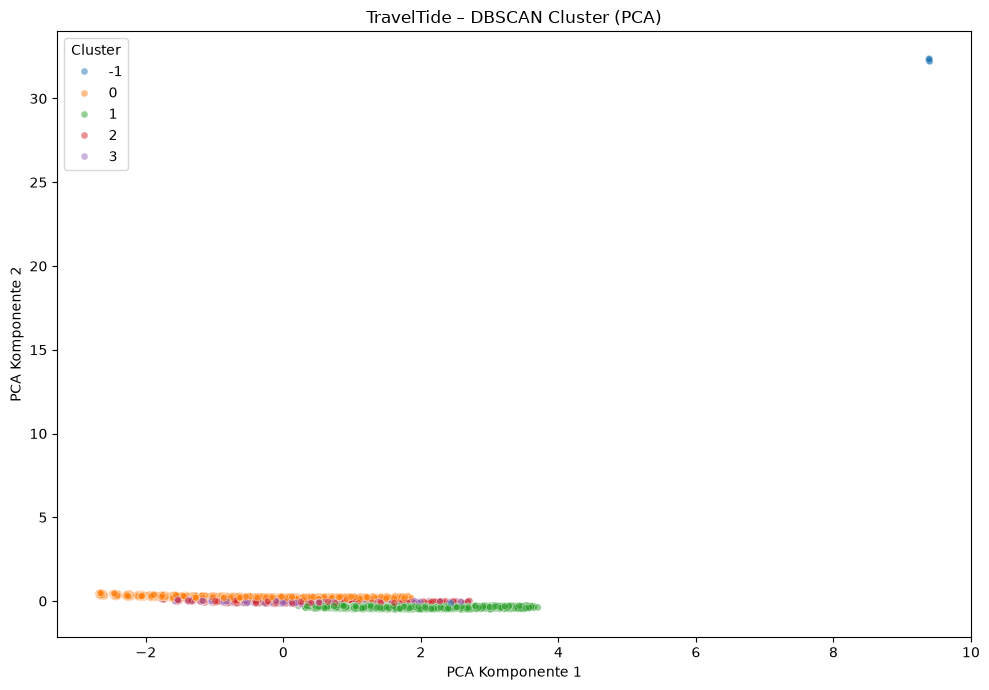

In [143]:
# ============================================================
# 3. DBSCAN CLUSTERING
# ============================================================

from sklearn.cluster import DBSCAN

# ------------------------------------------------------------
# 3.1 DBSCAN durchführen
# ------------------------------------------------------------

dbscan = DBSCAN(
    eps=1.5,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_sample)

dbscan_results = cluster_data.loc[
    X_sample.index
].copy()

dbscan_results["DBSCAN_Cluster"] = dbscan_labels

# ------------------------------------------------------------
# 3.2 Anzahl der Sessions je Cluster
# ------------------------------------------------------------

print("DBSCAN – ANZAHL SESSIONS JE CLUSTER")

display(
    dbscan_results["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# Cluster -1 bedeutet: Rauschen / nicht zugeordnet
noise_count = (
    dbscan_results["DBSCAN_Cluster"] == -1
).sum()

cluster_count = len(
    set(dbscan_labels) - {-1}
)

print(f"Erkannte Cluster: {cluster_count}")
print(f"Sessions im Rauschen: {noise_count:,}")
print(
    f"Anteil Rauschen: "
    f"{noise_count / len(dbscan_results) * 100:.2f}%"
)

# ------------------------------------------------------------
# 3.3 Cluster-Profile berechnen
# ------------------------------------------------------------

dbscan_profile = dbscan_results.groupby(
    "DBSCAN_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        cancellation_col
    ]
].mean().round(2)

print("DBSCAN – CLUSTER-PROFILE")

display(dbscan_profile)

# ------------------------------------------------------------
# 3.4 Visualisierung mit PCA
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=dbscan_labels,
    palette="tab10",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – DBSCAN Cluster (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


GMM – ANZAHL SESSIONS JE CLUSTER


,Anzahl Sessions
GMM_Cluster,
0,1953
1,4158
2,14
3,3875


GMM – CLUSTER-PROFILE


,session_duration_min,flight_booked,hotel_booked,page_clicks,cancellation,GMM_Confidence
GMM_Cluster,,,,,,
0,3.165,0.165,0.201,25.529,0.0,0.974
1,2.970,1.000,1.000,23.976,0.0,1.000
2,10.000,1.000,1.000,10.000,1.0,1.000
3,1.464,0.135,0.143,11.793,0.0,0.987


GMM – DURCHSCHNITTLICHE ZUORDNUNGSSICHERHEIT


GMM_Cluster
0    0.974
1    1.000
2    1.000
3    0.987
Name: GMM_Confidence, dtype: float64

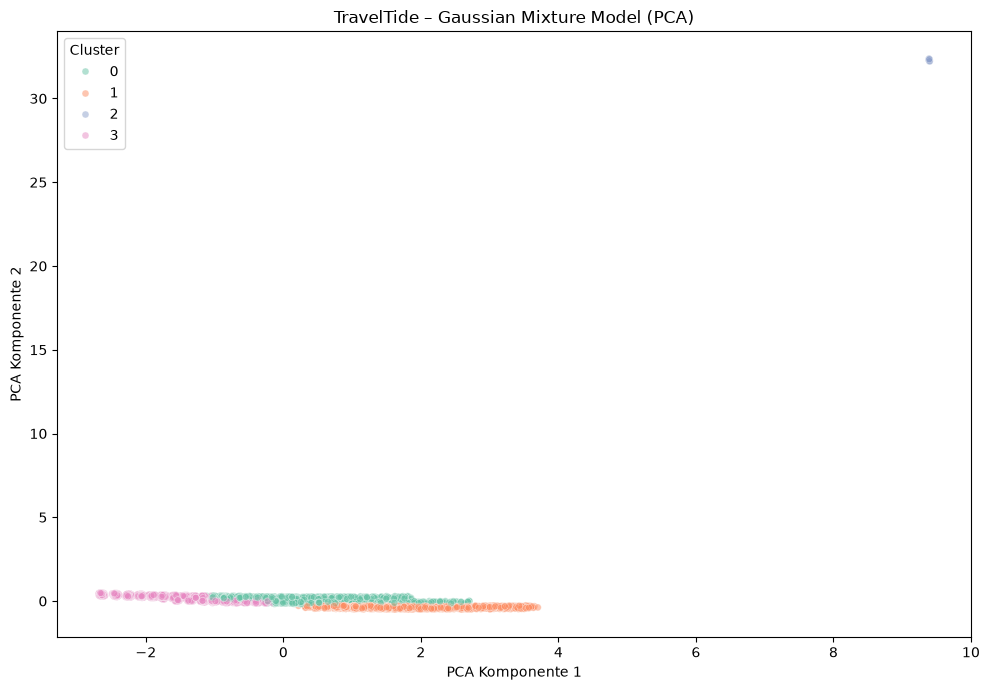

GMM BIC: -93,558.77
GMM AIC: -94,849.42


In [144]:
# ============================================================
# 4. GAUSSIAN MIXTURE MODELS (GMM)
# ============================================================

from sklearn.mixture import GaussianMixture

# ------------------------------------------------------------
# 4.1 GMM mit vier Komponenten berechnen
# ------------------------------------------------------------

gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    random_state=42,
    n_init=3
)

gmm.fit(X_sample)

gmm_labels = gmm.predict(X_sample)

# Wahrscheinlichkeiten der Cluster-Zugehörigkeit
gmm_probabilities = gmm.predict_proba(X_sample)

gmm_results = cluster_data.loc[
    X_sample.index
].copy()

gmm_results["GMM_Cluster"] = gmm_labels

gmm_results["GMM_Confidence"] = (
    gmm_probabilities.max(axis=1)
)

# ------------------------------------------------------------
# 4.2 Anzahl der Sessions je Cluster
# ------------------------------------------------------------

print("GMM – ANZAHL SESSIONS JE CLUSTER")

display(
    gmm_results["GMM_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Anzahl Sessions")
)

# ------------------------------------------------------------
# 4.3 Cluster-Profile berechnen
# ------------------------------------------------------------

gmm_profile = gmm_results.groupby(
    "GMM_Cluster"
)[
    [
        "session_duration_min",
        "flight_booked",
        "hotel_booked",
        "page_clicks",
        cancellation_col,
        "GMM_Confidence"
    ]
].mean().round(3)

print("GMM – CLUSTER-PROFILE")

display(gmm_profile)

# ------------------------------------------------------------
# 4.4 Cluster-Wahrscheinlichkeiten analysieren
# ------------------------------------------------------------

print("GMM – DURCHSCHNITTLICHE ZUORDNUNGSSICHERHEIT")

display(
    gmm_results.groupby("GMM_Cluster")[
        "GMM_Confidence"
    ].mean().round(3)
)

# ------------------------------------------------------------
# 4.5 Visualisierung mit PCA
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=gmm_labels,
    palette="Set2",
    alpha=0.5,
    s=25
)

plt.title("TravelTide – Gaussian Mixture Model (PCA)")
plt.xlabel("PCA Komponente 1")
plt.ylabel("PCA Komponente 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4.6 Modellgüte: BIC und AIC
# ------------------------------------------------------------

print(f"GMM BIC: {gmm.bic(X_sample):,.2f}")
print(f"GMM AIC: {gmm.aic(X_sample):,.2f}")


In [145]:
# # ============================================================
# # 5. RFM-SEGMENTIERUNG – VORLAGE FÜR KUNDENDATEN
# # ============================================================

# # Voraussetzung:
# # sessions muss zusätzlich enthalten:
# # customer_id  = eindeutige Kunden-ID
# # total_spent  = Umsatz pro Session oder Buchung

# if not {"customer_id", "total_spent"}.issubset(sessions.columns):

#     print(
#         "Eine vollständige RFM-Analyse ist noch nicht möglich."
#     )
#     print(
#         "Es fehlen die Spalten customer_id und total_spent."
#     )

# else:

#     # --------------------------------------------------------
#     # 5.1 Daten vorbereiten
#     # --------------------------------------------------------

#     rfm_data = sessions.copy()

#     rfm_data["session_start"] = pd.to_datetime(
#         rfm_data["session_start"],
#         errors="coerce"
#     )

#     rfm_data["total_spent"] = pd.to_numeric(
#         rfm_data["total_spent"],
#         errors="coerce"
#     )

#     rfm_data = rfm_data.dropna(
#         subset=[
#             "customer_id",
#             "session_start",
#             "total_spent"
#         ]
#     )

#     # --------------------------------------------------------
#     # 5.2 RFM-Kennzahlen berechnen
#     # --------------------------------------------------------

#     reference_date = (
#         rfm_data["session_start"].max()
#         + pd.Timedelta(days=1)
#     )

#     rfm = rfm_data.groupby("customer_id").agg(
#         Recency=(
#             "session_start",
#             lambda x: (reference_date - x.max()).days
#         ),
#         Frequency=(
#             "session_start",
#             "count"
#         ),
#         Monetary=(
#             "total_spent",
#             "sum"
#         )
#     )

#     # --------------------------------------------------------
#     # 5.3 RFM-Scores berechnen
#     # --------------------------------------------------------

#     # Recency: niedriger Wert = besser
#     rfm["R_Score"] = pd.qcut(
#         rfm["Recency"].rank(method="first"),
#         5,
#         labels=[5, 4, 3, 2, 1]
#     ).astype(int)

#     # Frequency: höherer Wert = besser
#     rfm["F_Score"] = pd.qcut(
#         rfm["Frequency"].rank(method="first"),
#         5,
#         labels=[1, 2, 3, 4, 5]
#     ).astype(int)

#     # Monetary: höherer Wert = besser
#     rfm["M_Score"] = pd.qcut(
#         rfm["Monetary"].rank(method="first"),
#         5,
#         labels=[1, 2, 3, 4, 5]
#     ).astype(int)

#     # Gesamtscore
#     rfm["RFM_Score"] = (
#         rfm["R_Score"].astype(str) +
#         rfm["F_Score"].astype(str) +
#         rfm["M_Score"].astype(str)
#     )

#     # --------------------------------------------------------
#     # 5.4 Kundensegmente zuweisen
#     # --------------------------------------------------------

#     def assign_segment(row):

#         if (
#             row["R_Score"] >= 4 and
#             row["F_Score"] >= 4 and
#             row["M_Score"] >= 4
#         ):
#             return "VIP-Kunden"

#         elif (
#             row["R_Score"] >= 3 and
#             row["F_Score"] >= 3
#         ):
#             return "Aktive Kunden"

#         elif row["R_Score"] <= 2:
#             return "Inaktive Kunden"

#         elif row["F_Score"] <= 2:
#             return "Gelegentliche Kunden"

#         else:
#             return "Potenzialkunden"

#     rfm["Segment"] = rfm.apply(
#         assign_segment,
#         axis=1
#     )

#     # --------------------------------------------------------
#     # 5.5 Ergebnisse anzeigen
#     # --------------------------------------------------------

#     print("RFM – KUNDENSEGMENTIERUNG")

#     display(rfm.head(20))

#     print("ANZAHL KUNDEN JE SEGMENT")

#     display(
#         rfm["Segment"]
#         .value_counts()
#         .to_frame("Anzahl Kunden")
#     )

#     # --------------------------------------------------------
#     # 5.6 Segmente visualisieren
#     # --------------------------------------------------------

#     plt.figure(figsize=(10, 6))

#     sns.countplot(
#         data=rfm.reset_index(),
#         x="Segment",
#         order=rfm["Segment"].value_counts().index
#     )

#     plt.title("TravelTide – RFM-Kundensegmente")
#     plt.xlabel("Kundensegment")
#     plt.ylabel("Anzahl Kunden")
#     plt.xticks(rotation=30, ha="right")
#     plt.grid(axis="y", alpha=0.3)

#     plt.tight_layout()
#     plt.show()


MONATLICHE ANALYSE


,TOTAL,Flights,Hotels,Cancellations,Avg_Page_Clicks,Avg_Duration
session_start,,,,,,
2023-01-31 00:00:00+00:00,302661,148003,149343,124,19.37,2.41
2023-02-28 00:00:00+00:00,316158,154932,156117,146,19.37,2.41
2023-03-31 00:00:00+00:00,378339,185196,186869,246,19.33,2.40
2023-04-30 00:00:00+00:00,255479,125015,126028,289,19.36,2.41
2023-05-31 00:00:00+00:00,300794,147265,148498,341,19.35,2.41
2023-06-30 00:00:00+00:00,314078,154110,155515,405,19.35,2.41
2023-07-31 00:00:00+00:00,219156,107330,108754,373,19.35,2.41


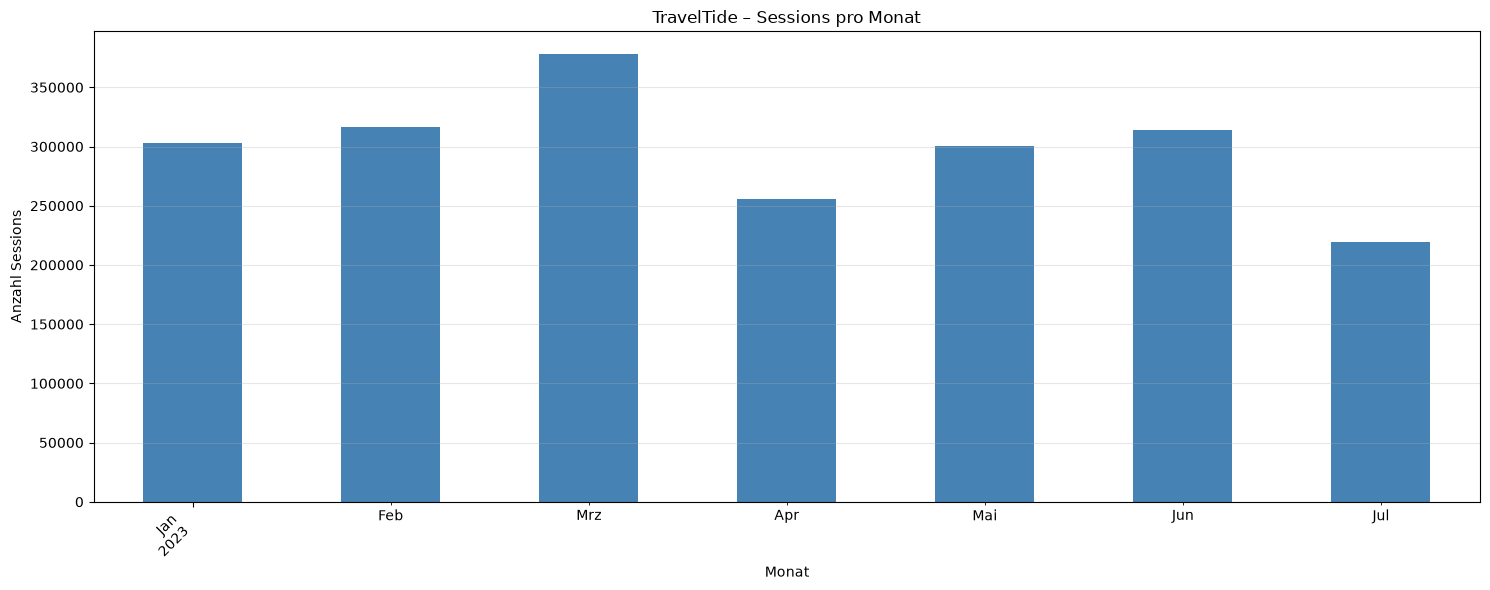

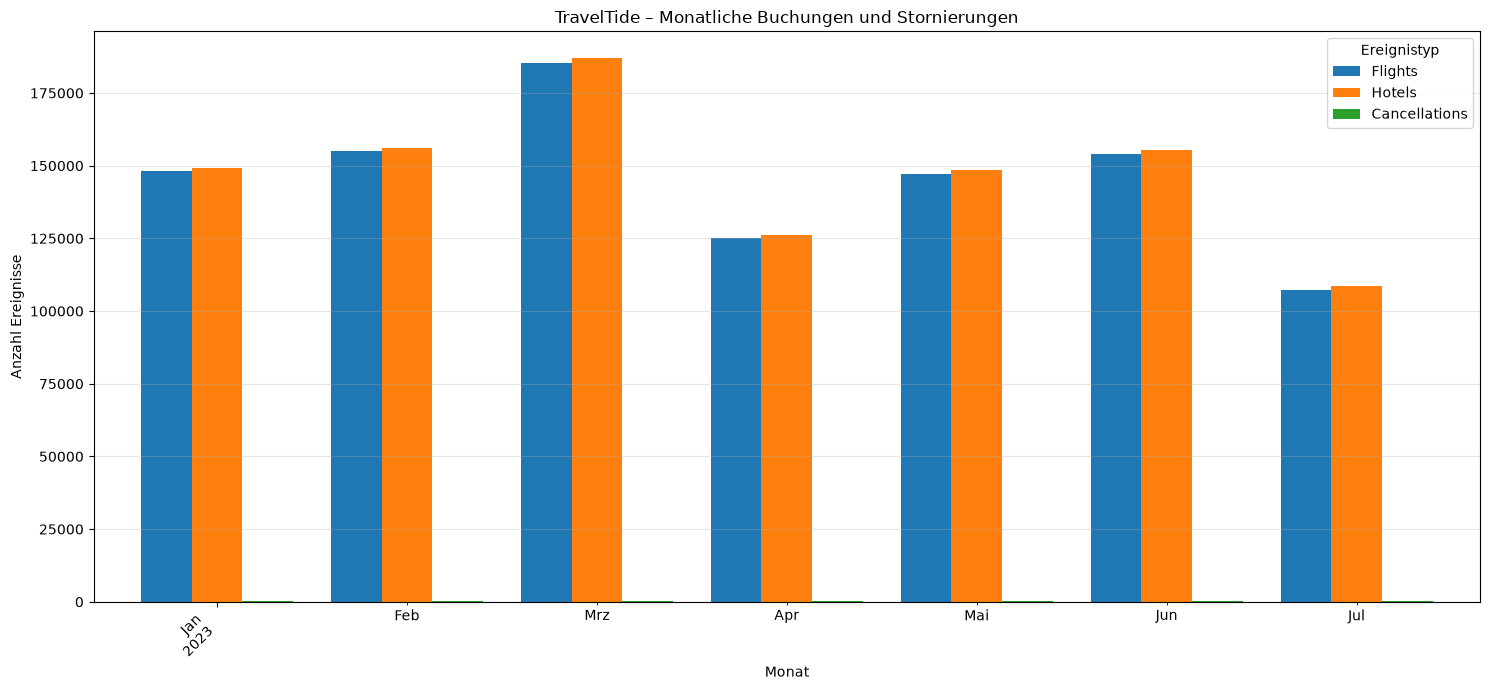

ANALYSE NACH WOCHENTAG


,TOTAL,Flights,Hotels,Cancellations,Avg_Page_Clicks
Montag,297258,145694,146978,279,19.37
Dienstag,295810,144787,146015,283,19.34
Mittwoch,295466,144929,146293,260,19.34
Donnerstag,310686,152119,153500,291,19.36
Freitag,298722,146343,147630,266,19.36
Samstag,295373,144599,145787,285,19.36
Sonntag,293350,143380,144921,260,19.36


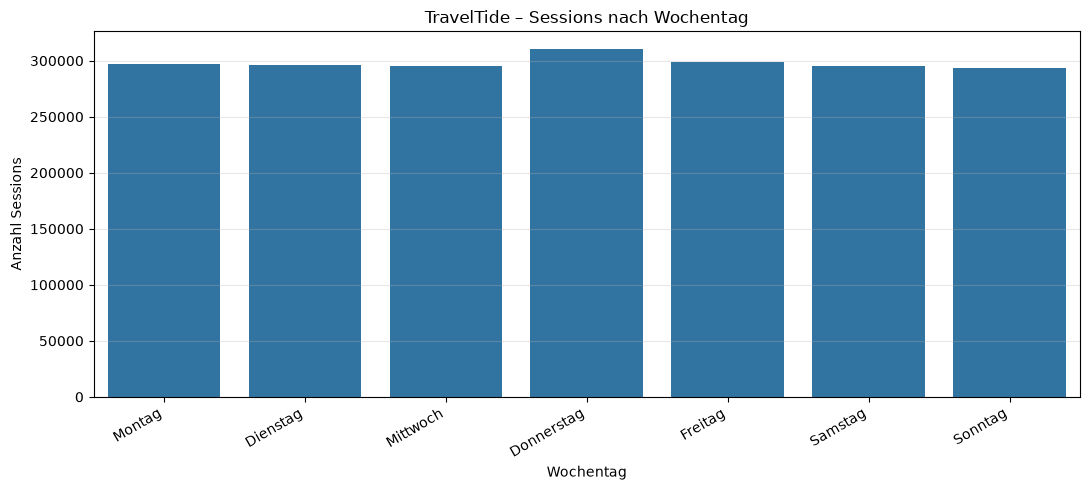

ANALYSE NACH TAGESSTUNDE


,TOTAL,Flights,Hotels,Cancellations
start_hour,,,,
0,11172,5481,5510,8
1,24066,11746,11859,20
2,26663,13012,13187,22
3,29241,14332,14532,25
4,32938,16060,16222,26
5,36744,18070,18171,40
6,40670,20085,20161,30
7,45601,22359,22593,38
8,51723,25461,25668,64


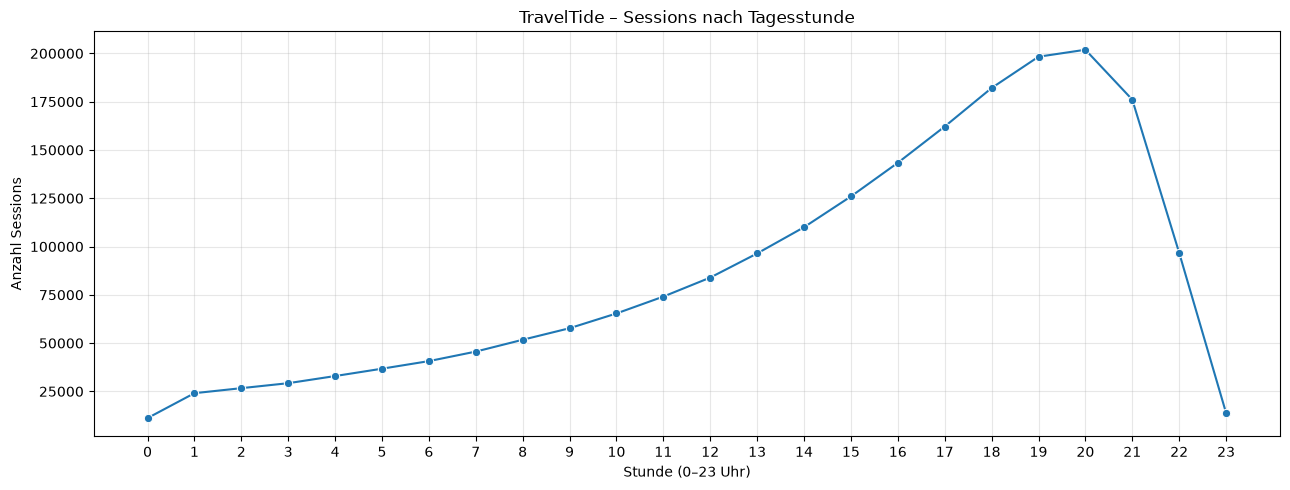

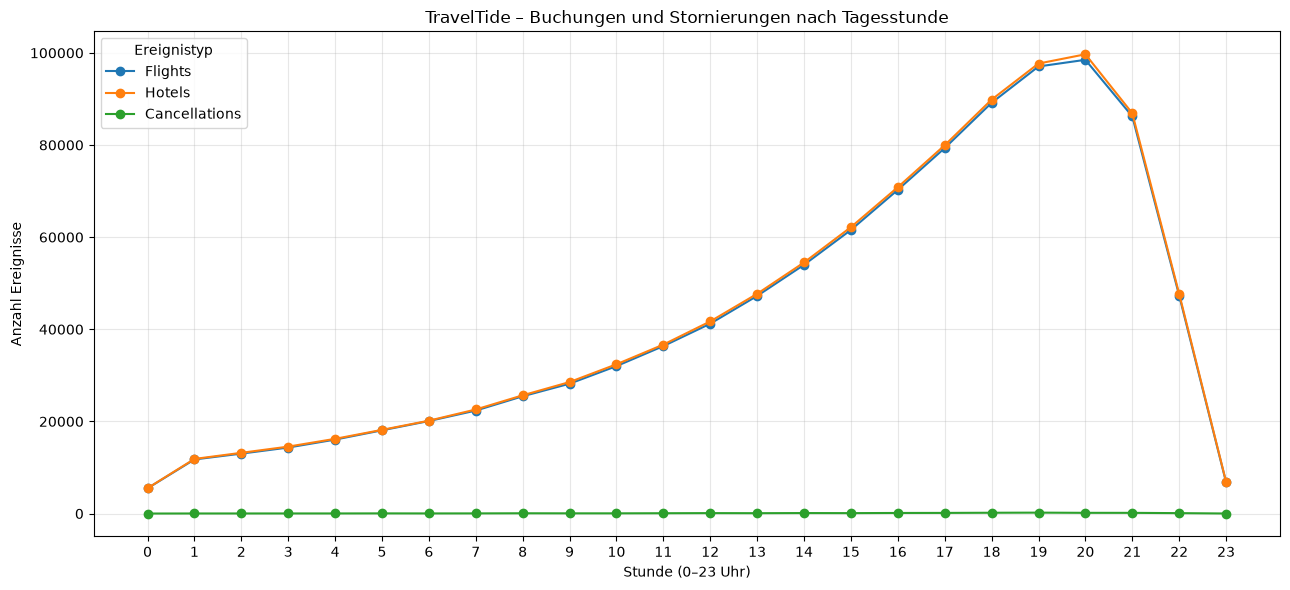

In [146]:
# ============================================================
# 6. ZEITLICHE GRUPPIERUNG
# ============================================================

# ------------------------------------------------------------
# 6.1 Monatliche Aggregation
# ------------------------------------------------------------

monthly_analysis = (
    cluster_data
    .set_index("session_start")
    .resample("ME")
    .agg(
        TOTAL=("session_duration_min", "size"),
        Flights=("flight_booked", "sum"),
        Hotels=("hotel_booked", "sum"),
        Cancellations=(cancellation_col, "sum"),
        Avg_Page_Clicks=("page_clicks", "mean"),
        Avg_Duration=("session_duration_min", "mean")
    )
)

print("MONATLICHE ANALYSE")

display(monthly_analysis.round(2))

# ------------------------------------------------------------
# 6.2 Sessions pro Monat visualisieren
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

monthly_analysis["TOTAL"].plot(
    kind="bar",
    color="steelblue"
)

plt.title("TravelTide – Sessions pro Monat")
plt.xlabel("Monat")
plt.ylabel("Anzahl Sessions")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6.3 Buchungen und Stornierungen pro Monat
# ------------------------------------------------------------

monthly_analysis[
    ["Flights", "Hotels", "Cancellations"]
].plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title(
    "TravelTide – Monatliche Buchungen und Stornierungen"
)

plt.xlabel("Monat")
plt.ylabel("Anzahl Ereignisse")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Ereignistyp")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6.4 Sessions nach Wochentag
# ------------------------------------------------------------

weekday_names = [
    "Montag",
    "Dienstag",
    "Mittwoch",
    "Donnerstag",
    "Freitag",
    "Samstag",
    "Sonntag"
]

weekday_analysis = (
    cluster_data
    .groupby("weekday")
    .agg(
        TOTAL=("session_duration_min", "size"),
        Flights=("flight_booked", "sum"),
        Hotels=("hotel_booked", "sum"),
        Cancellations=(cancellation_col, "sum"),
        Avg_Page_Clicks=("page_clicks", "mean")
    )
)

weekday_analysis.index = [
    weekday_names[i]
    for i in weekday_analysis.index
]

print("ANALYSE NACH WOCHENTAG")

display(weekday_analysis.round(2))

plt.figure(figsize=(11, 5))

sns.barplot(
    x=weekday_analysis.index,
    y=weekday_analysis["TOTAL"]
)

plt.title("TravelTide – Sessions nach Wochentag")
plt.xlabel("Wochentag")
plt.ylabel("Anzahl Sessions")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6.5 Sessions nach Tageszeit
# ------------------------------------------------------------

hour_analysis = (
    cluster_data
    .groupby("start_hour")
    .agg(
        TOTAL=("session_duration_min", "size"),
        Flights=("flight_booked", "sum"),
        Hotels=("hotel_booked", "sum"),
        Cancellations=(cancellation_col, "sum")
    )
)

print("ANALYSE NACH TAGESSTUNDE")

display(hour_analysis)

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=hour_analysis,
    x=hour_analysis.index,
    y="TOTAL",
    marker="o"
)

plt.title("TravelTide – Sessions nach Tagesstunde")
plt.xlabel("Stunde (0–23 Uhr)")
plt.ylabel("Anzahl Sessions")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6.6 Buchungsverhalten nach Tagesstunde
# ------------------------------------------------------------

hour_analysis[
    ["Flights", "Hotels", "Cancellations"]
].plot(
    kind="line",
    marker="o",
    figsize=(13, 6)
)

plt.title(
    "TravelTide – Buchungen und Stornierungen nach Tagesstunde"
)

plt.xlabel("Stunde (0–23 Uhr)")
plt.ylabel("Anzahl Ereignisse")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(title="Ereignistyp")

plt.tight_layout()
plt.show()


In [147]:
# ============================================================
# 1. ERGEBNIS-DATAFRAME ERSTELLEN
# ============================================================

# Gewünschte ID-Spalten
id_columns = [
    "session_id",
    "user_id",
    "trip_id"
]

# Prüfen, ob alle ID-Spalten vorhanden sind
missing_columns = [
    col for col in id_columns
    if col not in sessions.columns
]

if missing_columns:
    raise ValueError(
        f"Folgende Spalten fehlen in sessions: {missing_columns}"
    )

# Basis-DataFrame mit IDs erstellen
clustering_results = sessions[
    id_columns
].copy()

# Ursprünglichen Index als Zuordnungsschlüssel verwenden
clustering_results["_original_index"] = sessions.index

# ============================================================
# 2. SESSION-DATEN ERGÄNZEN
# ============================================================

# Session-Informationen aus cluster_data übernehmen
session_columns = [
    "session_start",
    "session_end",
    "flight_booked",
    "hotel_booked",
    "page_clicks",
    cancellation_col
]

session_info = cluster_data[
    session_columns
].copy()

session_info["_original_index"] = cluster_data.index

clustering_results = clustering_results.merge(
    session_info,
    on="_original_index",
    how="left"
)

# ============================================================
# 3. K-MEANS CLUSTER ZUORDNEN
# ============================================================

clustering_results["KMeans_Cluster"] = (
    cluster_results["KMeans_Cluster"]
    .reindex(clustering_results["_original_index"])
    .to_numpy()
)

# ============================================================
# 4. HIERARCHICAL CLUSTER ZUORDNEN
# ============================================================

clustering_results["Hierarchical_Cluster"] = (
    hier_results["Hierarchical_Cluster"]
    .reindex(clustering_results["_original_index"])
    .to_numpy()
)

# ============================================================
# 5. DBSCAN CLUSTER ZUORDNEN
# ============================================================

clustering_results["DBSCAN_Cluster"] = (
    dbscan_results["DBSCAN_Cluster"]
    .reindex(clustering_results["_original_index"])
    .to_numpy()
)

# ============================================================
# 6. GAUSSIAN MIXTURE MODEL CLUSTER ZUORDNEN
# ============================================================

clustering_results["GMM_Cluster"] = (
    gmm_results["GMM_Cluster"]
    .reindex(clustering_results["_original_index"])
    .to_numpy()
)

# ============================================================
# 7. ERGEBNIS-DATAFRAME BEREINIGEN
# ============================================================

clustering_results = clustering_results.drop(
    columns=["_original_index"]
)

# ============================================================
# 8. ERGEBNIS ANZEIGEN
# ============================================================

print("CLUSTERING RESULTS")
print("-----------------------------------")

print(f"Anzahl Sessions: {len(clustering_results):,}")
print(f"Anzahl Spalten: {len(clustering_results.columns)}")

display(clustering_results.head(20))

# ============================================================
# 9. KONTROLLE DER CLUSTER-ZUORDNUNGEN
# ============================================================

cluster_columns = [
    "KMeans_Cluster",
    "Hierarchical_Cluster",
    "DBSCAN_Cluster",
    "GMM_Cluster"
]

print("ANZAHL ZUGEORDNETER SESSIONS JE MODELL")

display(
    clustering_results[cluster_columns]
    .notna()
    .sum()
    .to_frame("Zugeordnete Sessions")
)

print("ANZAHL FEHLENDER CLUSTER-ZUORDNUNGEN")

display(
    clustering_results[cluster_columns]
    .isna()
    .sum()
    .to_frame("Fehlende Zuordnungen")
)


CLUSTERING RESULTS
-----------------------------------
Anzahl Sessions: 2,096,299
Anzahl Spalten: 13


,session_id,user_id,trip_id,session_start,session_end,flight_booked,hotel_booked,page_clicks,cancellation,KMeans_Cluster,Hierarchical_Cluster,DBSCAN_Cluster,GMM_Cluster
0,275450-c9095461e19f482296686ee955f026dc,275450,NaN,2023-06-22 16:27:00+00:00,2023-06-22 16:31:28+00:00,False,False,36.0,False,NaN,NaN,NaN,NaN
1,275679-97b7e062a4b0493db934bf2921f39957,275679,275679-92558bc49db145cf915eb799096fc0c0,2023-06-22 14:05:00+00:00,2023-06-22 14:08:04+00:00,True,True,25.0,False,NaN,NaN,NaN,NaN
2,276121-c9d32570954f4d8d93f7bcc8de887007,276121,NaN,2023-06-22 15:14:00+00:00,2023-06-22 15:15:34+00:00,False,False,13.0,False,NaN,NaN,NaN,NaN
3,276194-66dcf78424ac4436bead3cfc599dcb0e,276194,NaN,2023-06-22 21:07:00+00:00,2023-06-22 21:08:03+00:00,False,False,8.0,False,NaN,NaN,NaN,NaN
4,276224-e4f9f5c982a64aa5a0603a97e770cec0,276224,276224-0f140e412d4149deb9ecc7eadad60d1d,2023-06-22 05:10:00+00:00,2023-06-22 05:13:04+00:00,True,True,25.0,False,NaN,NaN,NaN,NaN
5,276374-5b513599cc9b424cba2a2bba25c7cf98,276374,276374-128149646d5448bcaa801f0b6abaf732,2023-06-22 14:27:00+00:00,2023-06-22 14:30:55+00:00,True,True,31.0,False,NaN,NaN,NaN,NaN
6,276732-81d0cc5cbd3c47ee9785230af0b0c498,276732,276732-bef0ffbd9b14462eb888bcdbecbb7ec2,2023-06-22 20:28:00+00:00,2023-06-22 20:32:17+00:00,False,True,35.0,False,NaN,NaN,NaN,NaN
7,276774-14faf2ccfd3c4809a75109eaabdad50b,276774,NaN,2023-06-22 16:41:00+00:00,2023-06-22 16:42:41+00:00,False,False,14.0,False,NaN,NaN,NaN,NaN
8,276830-4e6201624cd74857bab6885313c3085e,276830,276830-3e775ff3d9e54d9f90062704c6f4d259,2023-06-22 15:24:00+00:00,2023-06-22 15:26:31+00:00,True,True,20.0,False,NaN,NaN,NaN,NaN
9,276976-2035d8e87eba4ad1974572f81a003e05,276976,NaN,2023-06-22 21:53:00+00:00,2023-06-22 21:54:27+00:00,False,False,11.0,False,NaN,NaN,NaN,NaN


ANZAHL ZUGEORDNETER SESSIONS JE MODELL


,Zugeordnete Sessions
KMeans_Cluster,10000
Hierarchical_Cluster,3000
DBSCAN_Cluster,10000
GMM_Cluster,10000


ANZAHL FEHLENDER CLUSTER-ZUORDNUNGEN


,Fehlende Zuordnungen
KMeans_Cluster,2086299
Hierarchical_Cluster,2093299
DBSCAN_Cluster,2086299
GMM_Cluster,2086299


In [148]:
# ============================================================
# 10. CLUSTERING RESULTS SPEICHERN
# ============================================================

clustering_file = Path(TARGET_DIR) / "clustering_results.csv"

clustering_results.to_csv(
    clustering_file,
    index=False
)

print(f"Clustering Results gespeichert unter: {clustering_file}")

Clustering Results gespeichert unter: D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\03_cleaning\clustering_results.csv
